# 03 · Baseline models and error diagnostics

**Question.** How well do persistence, seasonal, engineering, statistical and tree controls reconstruct the current aggregate under the same observable sensor masks, and where do they fail?

The notebook starts from saved fold-local preprocessing and fixed development IDs. It first checks that the saved preprocessing is reproduced on reload, then measures computation cost before fixing a tuning budget. Model selection uses inner validation; outer-validation predictions are paired by observation ID, scenario and seed. No locked or external targets are opened.

In [1]:
from pathlib import Path
import hashlib, json, re, warnings
import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib import font_manager
from IPython.display import display

ROOT = Path.cwd()
if ROOT.name == "Notebooks":
    ROOT = ROOT.parent
assert ROOT.is_dir()
REFINED = ROOT / "Data/Interim/development_minutes_refined"
RUN = "guldana_n3_20261007_v01"
TABLES = ROOT / "Tables" / RUN / "03_baselines"
FIGURES = ROOT / "Figures/PNG" / RUN
for directory in [TABLES, FIGURES, ROOT / "Data/Interim/timestamp_index"]:
    directory.mkdir(parents=True, exist_ok=True)
font_path = font_manager.findfont("Times New Roman", fallback_to_default=False)
assert Path(font_path).is_file()
mpl.rcParams.update({"font.family": "Times New Roman", "font.size": 18,
                     "axes.titlesize": 20, "axes.labelsize": 18,
                     "xtick.labelsize": 18, "ytick.labelsize": 18,
                     "legend.fontsize": 18, "figure.dpi": 350,
                     "savefig.dpi": 350, "axes.unicode_minus": True,
                     "pdf.fonttype": 42, "ps.fonttype": 42})
from matplotlib_inline.backend_inline import set_matplotlib_formats
set_matplotlib_formats("png")
pd.set_option("display.max_rows", 120)
pd.set_option("display.max_columns", 20)
pd.set_option("display.width", 180)
pd.set_option("display.max_colwidth", 80)


# Keep HTML tables compact; publication font requirements apply to Matplotlib figures.
def table(frame, name, caption, precision=4):
    frame.to_csv(TABLES / (name + ".csv"), index=False)
    frame.to_latex(TABLES / (name + ".tex"), index=False, caption=caption,
                   float_format=lambda x: f"{x:.{precision}f}")
    def signed_number(x):
        rounded = round(float(x), precision)
        return f"{0.0 if rounded == 0 else rounded:.{precision}f}".replace("-", "−")
    formatters = {col: signed_number for col in frame.select_dtypes(include="floating").columns}
    display(frame.style.format(formatters, na_rep="Unavailable").hide(axis="index").set_caption(caption))
# Figure export verifies the real font, all text sizes and PNG density before inline display.
from IPython.display import Image
from PIL import Image as PILImage
import matplotlib.dates as mdates
from matplotlib.text import Text
FIGURE_PNG = ROOT / "Figures/PNG" / RUN
FIGURE_PDF = ROOT / "Figures/PDF" / RUN
FIGURE_PNG.mkdir(parents=True, exist_ok=True)
FIGURE_PDF.mkdir(parents=True, exist_ok=True)
figure_qa = []
def save_figure(fig, name):
    fig.canvas.draw()
    texts = [t for t in fig.findobj(Text) if t.get_visible() and t.get_text().strip()]
    for text_item in texts:
        assert 18 <= text_item.get_fontsize() <= 20, (text_item.get_text(), text_item.get_fontsize())
        resolved = font_manager.findfont(text_item.get_fontproperties(), fallback_to_default=False)
        assert font_manager.FontProperties(fname=resolved).get_name() == "Times New Roman"
    png = FIGURE_PNG / f"{name}.png"
    pdf = FIGURE_PDF / f"{name}.pdf"
    fig.savefig(png, dpi=350, bbox_inches="tight", pad_inches=.06)
    fig.savefig(pdf, dpi=350, bbox_inches="tight", pad_inches=.06)
    with PILImage.open(png) as im:
        assert all(abs(d - 350) < .02 for d in im.info["dpi"])
        figure_qa.append({"Figure": name, "Width px": im.width, "Height px": im.height, "DPI": im.info["dpi"][0],
                          "Font": "Times New Roman", "Text items checked": len(texts)})
    plt.close(fig)
    display(Image(filename=str(png)))


gate = json.loads((ROOT / "Manifests/nb01_gate.json").read_text())
assert gate["status"] == "primary_development_data_adequate_for_nb02"
schema = json.loads((ROOT / "Configs/sensor_schema.json").read_text())
semantic_map = pd.read_csv(ROOT / "Data/Interim/sensor_semantic_map.csv")
PREP = ROOT / "Models/preprocessing" / RUN
PREP.mkdir(parents=True,exist_ok=True)

import time, os, platform, resource
import torch
from sklearn.linear_model import Ridge, HuberRegressor
from sklearn.ensemble import ExtraTreesRegressor, HistGradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error
from catboost import CatBoostRegressor
import joblib
NB02_GATE=json.loads((ROOT / "Manifests/nb02_gate.json").read_text())
assert NB02_GATE["status"]=="development_preprocessing_ready_for_clean_kernel_reload"
MODEL_DIR=ROOT / "Models/baselines" / RUN
PRED_DIR=ROOT / "Predictions/development" / RUN
for directory in [MODEL_DIR,PRED_DIR]:directory.mkdir(parents=True,exist_ok=True)


In [3]:
# Complete scientific tables: semantic groups, unchanged values, mathematical minus.
# This display-only setup does not fit models or modify numerical exports.
import copy as _table_copy
import re as _table_re
import pandas as _table_pd
from bs4 import BeautifulSoup as _TableSoup, NavigableString as _TableText
from pandas.io.formats.style import Styler as _TableStyler
from IPython.display import HTML as _TableHTML
import hashlib as _table_hashlib, json as _table_json
_table_layout_bytes = (ROOT / "Configs/article_table_layout.json").read_bytes()
assert _table_hashlib.sha256(_table_layout_bytes).hexdigest() == "fbbb6522e8c59dbde1eea0021da0a6f72e3257d1c6d0c8d49e74c5bd3a6a9d8c"
_ARTICLE_TABLE_GROUPS = _table_json.loads(_table_layout_bytes)
_ARTICLE_NUMBER = _table_re.compile(r"^\s*[+−-]?(?:\d+(?:\.\d*)?|\.\d+)(?:[eE][+−-]?\d+)?%?\s*$")
def _article_table_layout(tag, additions):
    declarations = dict(part.strip().split(":", 1) for part in tag.get("style", "").split(";") if ":" in part)
    declarations.update(additions)
    tag["style"] = ";".join(key + ":" + value for key, value in declarations.items()) + ";"
def _article_table_html(html):
    soup = _TableSoup(html, "html.parser")
    for table in list(soup.find_all("table")):
        head = table.find("thead")
        body = table.find("tbody")
        if head is None or body is None:
            continue
        heads = [tag.get_text(strip=True) for tag in head.find_all("th")]
        rule = _ARTICLE_TABLE_GROUPS.get("|".join(heads))
        if rule is not None and len(head.find_all("tr")) == 1:
            rows = body.find_all("tr", recursive=False)
            if all(len(row.find_all(["th", "td"], recursive=False)) == len(heads) for row in rows):
                assert set(sum(rule["columns"], [])) == set(heads)
                original_styles = [style.get_text() for style in soup.find_all("style")]
                for number, (columns, label) in enumerate(zip(rule["columns"], rule["labels"]), 1):
                    part = _table_copy.deepcopy(table)
                    keep = [heads.index(name) for name in columns]
                    for row in part.find_all("tr"):
                        for index, tag in enumerate(row.find_all(["th", "td"], recursive=False)):
                            if index not in keep:
                                tag.decompose()
                    caption = part.find("caption")
                    if caption is None:
                        caption = soup.new_tag("caption")
                        part.insert(0, caption)
                    caption.append(" " + label)
                    suffix = "_article_part_" + str(number)
                    original_id = table.get("id")
                    for tag in [part] + part.find_all(True):
                        if tag.has_attr("id"):
                            tag["id"] = (tag["id"].replace(original_id, original_id + suffix, 1)
                                         if original_id and tag["id"].startswith(original_id) else tag["id"] + suffix)
                    if original_id:
                        for style_text in original_styles:
                            if "#" + original_id in style_text:
                                copied_style = soup.new_tag("style")
                                copied_style.string = style_text.replace("#" + original_id, "#" + original_id + suffix)
                                table.insert_before(copied_style)
                    table.insert_before(part)
                table.decompose()
    for table in soup.find_all("table"):
        _article_table_layout(table, {"max-width":"100%", "table-layout":"auto", "margin-bottom":"1.4em"})
        for tag in table.find_all(["th", "td", "caption"]):
            _article_table_layout(tag, {"white-space":"normal", "vertical-align":"top"})
            if tag.name == "caption":
                _article_table_layout(tag, {"text-align":"left", "caption-side":"top"})
            for old_break in list(tag.find_all("wbr")):
                old_break.decompose()
            for node in list(tag.descendants):
                if not isinstance(node, _TableText) or node.parent.name in {"code", "pre", "script", "style"}:
                    continue
                text = str(node)
                if tag.name == "td" and _ARTICLE_NUMBER.fullmatch(text):
                    text = text.replace("-", "−")
                chunks = _table_re.split("(?<=_)", text)
                for index, chunk in enumerate(chunks):
                    node.insert_before(_TableText(chunk))
                    if index + 1 < len(chunks):
                        node.insert_before(soup.new_tag("wbr"))
                node.extract()
    return str(_TableSoup(str(soup), "html.parser"))
def _article_styler_html(value):
    with _table_pd.option_context("styler.render.max_elements", max(1, value.data.size + len(value.data)),
                                  "styler.render.max_rows", None, "styler.render.max_columns", None):
        html = value.to_html(max_rows=len(value.data), max_columns=len(value.data.columns))
    assert not _TableSoup(html, "html.parser").select(".row_trim, .col_trim"), "Scientific table was truncated"
    return _article_table_html(html)
def _article_frame_html(value):
    return _article_table_html(value.to_html(max_rows=None, max_cols=None))
def _article_HTML_html(value):
    result = value._repr_html_()
    if isinstance(result, tuple):
        return _article_table_html(result[0]), result[1]
    return _article_table_html(result)
_table_format = get_ipython().display_formatter.formatters["text/html"]
_table_format.for_type(_TableStyler, _article_styler_html)
_table_format.for_type(_table_pd.DataFrame, _article_frame_html)
_table_format.for_type(_TableHTML, _article_HTML_html);


## 1. Data load and explicit reusable transformations

Only refined development values are loaded. The transformation and masking definitions are included below as readable source. Current aggregate values remain labels and are excluded from observed input batches.

In [2]:
# Load development-only minute artifacts, preserving IDs and separate validity states.
houses = {}
cohort_rows = []
for house in range(1,11):
    path = REFINED / f"plegma_house_{house:02d}.parquet"
    assert hashlib.sha256(path.read_bytes()).hexdigest() == gate["refined_files"][str(path.relative_to(ROOT))]
    data = pd.read_parquet(path)
    ids = pd.read_parquet(ROOT / f"Manifests/observation_ids/plegma_house_{house:02d}.parquet")
    ids = ids.loc[ids.split.eq("development")].set_index("timestamp")
    values = data.pivot(index="timestamp",columns="sensor",values="mean").reindex(ids.index)
    available = data.pivot(index="timestamp",columns="sensor",values="available").reindex(ids.index).fillna(False).astype(bool)
    coverage = data.pivot(index="timestamp",columns="sensor",values="coverage_fraction").reindex(ids.index)
    states = data.pivot(index="timestamp",columns="sensor",values="state").reindex(ids.index)
    assert values.index.equals(ids.index) and not {"A","V"}.intersection(values.columns)
    assert np.isfinite(values.where(available).stack()).all()
    eligible = available.P_agg & ~ids.context_only
    houses[house] = {"values":values,"available":available,"coverage":coverage,"states":states,"ids":ids,"eligible":eligible}
    cohort_rows.append({"House":house,"Eligible targets":int(eligible.sum()),
        "Fold 1 train":int((eligible & ids.fold_1.eq("train")).sum()),
        "Fold 1 inner validation":int((eligible & ids.fold_1.eq("inner_validation")).sum()),
        "Fold 1 outer validation":int((eligible & ids.fold_1.eq("outer_validation")).sum())})
cohort = pd.DataFrame(cohort_rows)

assert cohort["Eligible targets"].sum() == gate["eligible_development_targets"]

In [3]:
# Causal tabular representation; no training statistics are computed here.
POWER_TYPES = [t for t in schema["power_types"] if t != "aggregate"]
CONTEXT = {"temperature (C)":"indoor_temperature","humidity (%)":"indoor_humidity"}
MAX_HISTORY = 360

def age_since_observed(valid, limit=MAX_HISTORY):
    positions = np.arange(len(valid),dtype=np.int64)
    last = np.maximum.accumulate(np.where(np.asarray(valid),positions,-limit-1))
    return np.minimum(positions-last,limit+1).astype(np.float32)

def causal_features(values, available, coverage, mapping, aggregate_hidden=None, auxiliary_keep=None, partitions=None):
    v = values.copy()
    a = available.copy()
    if aggregate_hidden is not None:
        a.loc[aggregate_hidden,"P_agg"] = False
    if auxiliary_keep is not None:
        for s in mapping:
            if s in auxiliary_keep: a[s] &= np.asarray(auxiliary_keep[s],dtype=bool)
    v = v.where(a)
    x = {}
    hour = v.index.hour + v.index.minute/60
    for name,phase in [("hour",hour/24),("weekday",v.index.dayofweek/7),("year",(v.index.dayofyear-1)/365.2425)]:
        x[f"{name}_sin"] = np.sin(2*np.pi*phase)
        x[f"{name}_cos"] = np.cos(2*np.pi*phase)
    past = v.P_agg.shift(1)
    for lag in [1,2,5,15,30,60,120,240,360]:
        x[f"aggregate_lag_{lag}"] = v.P_agg.shift(lag)
    # Separate day/week retrievals are available to every model, only within the same partition.
    for lag in [1440,10080]:
        same_partition = partitions.eq(partitions.shift(lag)) if partitions is not None else pd.Series(False,index=v.index)
        x[f"aggregate_lag_{lag}"] = v.P_agg.shift(lag).where(same_partition)
    for width in [15,60,240,360]:
        roll = past.rolling(width,min_periods=1)
        for stat in ["mean","std","min","max"]: x[f"aggregate_{stat}_{width}"] = getattr(roll,stat)()
        x[f"aggregate_coverage_{width}"] = past.notna().rolling(width,min_periods=1).mean()
    x["aggregate_age"] = np.minimum(age_since_observed(past.notna())+1,MAX_HISTORY+1)
    x["aggregate_last"] = past.ffill(limit=MAX_HISTORY-1)
    representatives = list(mapping)
    x["current_aux_count"] = a[representatives].sum(axis=1) if representatives else 0
    x["installed_aux_count"] = len(representatives)
    for canonical in POWER_TYPES:
        sensors = [s for s in representatives if mapping[s]["type"]==canonical]
        tag = canonical.replace("/","_")
        if sensors:
            x[f"current_{tag}_sum"] = v[sensors].sum(axis=1,min_count=1)
            x[f"current_{tag}_count"] = a[sensors].sum(axis=1)
            x[f"installed_{tag}_count"] = len(sensors)
        else:
            x[f"current_{tag}_sum"] = np.nan
            x[f"current_{tag}_count"] = 0
            x[f"installed_{tag}_count"] = 0
        past_type = v[sensors].sum(axis=1,min_count=1).shift(1) if sensors else pd.Series(np.nan,index=v.index)
        for width in [15,60,240]:
            x[f"past_{tag}_mean_{width}"] = past_type.rolling(width,min_periods=1).mean()
        x[f"past_{tag}_std_240"] = past_type.rolling(240,min_periods=2).std()
        x[f"past_{tag}_last"] = past_type.ffill(limit=MAX_HISTORY-1)
        x[f"past_{tag}_coverage_240"] = (a[sensors].mean(axis=1).shift(1).rolling(240,min_periods=1).mean()
                                                       if sensors else 0)
    x["current_aux_sum"] = v[representatives].sum(axis=1,min_count=1) if representatives else np.nan
    for sensor,canonical in CONTEXT.items():
        x[f"current_{canonical}"] = v[sensor] if sensor in v else np.nan
        x[f"{canonical}_age"] = age_since_observed(a[sensor]) if sensor in a else MAX_HISTORY+1
    return pd.DataFrame(x,index=v.index).astype(np.float32)


duplicate_maps={}
for fold in [1,2,3]:
    state=json.loads((PREP/f"fold_{fold}_preprocessing.json").read_text())
    duplicate_maps[fold]={int(h):m for h,m in state["duplicate_maps"].items()}


In [4]:
# Full training-population fitting, explicit lineage, and serialization without opaque classes.
FEATURE_CACHE = ROOT / "Data/Interim/causal_features" / RUN
FEATURE_CACHE.mkdir(parents=True,exist_ok=True)
for house in houses:
    assert duplicate_maps[1][house] == duplicate_maps[2][house] == duplicate_maps[3][house]

def house_features(house,fold):
    info = houses[house]
    path = FEATURE_CACHE / f"plegma_house_{house:02d}.parquet"
    if path.is_file():
        x = pd.read_parquet(path)
    else:
        x = causal_features(info["values"],info["available"],info["coverage"],duplicate_maps[fold][house])
        x.to_parquet(path,compression="zstd")
    partitions = info["ids"][f"fold_{fold}"]
    for lag in [1440,10080]:
        x[f"aggregate_lag_{lag}"] = info["values"].P_agg.shift(lag).where(partitions.eq(partitions.shift(lag))).astype(np.float32)
    return x

class FoldSafePreprocessor:
    def __init__(self,state=None): self.state = state
    def fit(self,x,y):
        median = x.median().fillna(0)
        spread = x.quantile(.75)-x.quantile(.25)
        filled = x.fillna(median)
        std = filled.std(ddof=0)
        variable = std.gt(1e-8)
        missing = x.isna().any() & x.notna().any()
        scale = spread.where(spread.gt(1e-8),std).where(variable,1).fillna(1)
        self.state = {"input_columns":list(x.columns),"value_columns":list(x.columns[variable]),
            "missing_columns":list(x.columns[missing]),"median":median.to_dict(),"scale":scale.to_dict(),
            "target_mean":float(y.mean()),"target_scale":float(y.std(ddof=0)),"fit_rows":len(x)}
        assert self.state["target_scale"]>0
        return self
    def transform(self,x):
        assert list(x.columns)==self.state["input_columns"]
        values = self.state["value_columns"];missing=self.state["missing_columns"]
        median=pd.Series(self.state["median"]);scale=pd.Series(self.state["scale"])
        z=((x[values].fillna(median)-median[values])/scale[values]).astype(np.float32)
        z=pd.concat([z,x[missing].isna().astype(np.float32).add_prefix("missing__")],axis=1)
        assert np.isfinite(z.to_numpy()).all()
        return z
    def save(self,path): path.write_text(json.dumps(self.state,indent=2,allow_nan=False)+"\n")
    @classmethod
    def load(cls,path): return cls(json.loads(path.read_text()))


preprocessors={}
for relative,expected in NB02_GATE["preprocessing_files"].items():
    assert hashlib.sha256((ROOT/relative).read_bytes()).hexdigest()==expected
for fold in [1,2,3]:
    preprocessors[fold]=FoldSafePreprocessor.load(PREP/f"fold_{fold}_preprocessing.json")


In [5]:
# Construct label-free observed sensor tensors with deterministic, order-independent masking.
def keyed_uniform(*parts):
    key="|".join(map(str,parts)).encode()
    return int.from_bytes(hashlib.sha256(key).digest()[:8],"little")/2**64

def observed_sensor_batch(info,mapping,queries,target_scale,fold=1,history_minutes=360,
                          aggregate_gap=1,auxiliary_retention=1.,seed=17,mode="point",sensor_order=None):
    assert mode in {"point","block","sensor_dropout","mixed"}
    assert 1<=aggregate_gap<=history_minutes<=360 and 0<=auxiliary_retention<=1
    queries=np.asarray(queries,dtype=int)
    assert (queries>=history_minutes).all() and (queries<len(info["values"])).all()
    sensors=["P_agg",*sorted(mapping)] if sensor_order is None else list(sensor_order)
    assert set(sensors)=={"P_agg",*mapping} and len(sensors)==len(mapping)+1
    aggregate_index=sensors.index("P_agg")
    history_indices=queries[:,None]-np.arange(history_minutes,0,-1)[None,:]
    raw=info["values"][sensors].to_numpy(dtype=np.float64)
    available=info["available"][sensors].to_numpy(dtype=bool)
    coverage=info["coverage"][sensors].to_numpy(dtype=np.float64)
    hvalues=raw[history_indices].transpose(0,2,1)
    hmask=available[history_indices].transpose(0,2,1).copy()
    hcoverage=coverage[history_indices].transpose(0,2,1)
    if aggregate_gap>1: hmask[:,aggregate_index,-(aggregate_gap-1):]=False
    current_mask=available[queries].copy()
    current_mask[:,aggregate_index]=False
    current_values=raw[queries].copy()
    for b,q in enumerate(queries):
        identity=info["ids"].iloc[q].observation_id
        drop_history=(mode=="sensor_dropout") or (mode=="mixed" and keyed_uniform(identity,seed,"history")<.5)
        for j,sensor in enumerate(sensors):
            if sensor=="P_agg":continue
            keep=keyed_uniform(identity,seed,sensor)<auxiliary_retention
            current_mask[b,j] &= keep
            if drop_history and not keep:hmask[b,j,:]=False
    positions=np.arange(history_minutes)[None,None,:]
    last=np.maximum.accumulate(np.where(hmask,positions,-history_minutes-1),axis=-1)
    age=np.minimum(positions-last,history_minutes+1)/(history_minutes+1)
    history=np.stack([np.where(hmask,hvalues/target_scale,0),hmask.astype(float),
                      np.where(hmask,np.nan_to_num(hcoverage),0),age],axis=-1).astype(np.float32)
    current_values=np.where(current_mask,current_values/target_scale,0).astype(np.float32)
    types=["aggregate" if s=="P_agg" else mapping[s]["type"] for s in sensors]
    type_ids=np.array([schema["power_types"].index(t) for t in types],dtype=np.int64)
    role_ids=np.array([0 if s=="P_agg" else 1 for s in sensors],dtype=np.int64)
    ts=info["values"].index[queries]
    context=[]
    for b,(q,t) in enumerate(zip(queries,ts)):
        hour=t.hour+t.minute/60
        row=[np.sin(2*np.pi*hour/24),np.cos(2*np.pi*hour/24),
             np.sin(2*np.pi*t.dayofweek/7),np.cos(2*np.pi*t.dayofweek/7),
             np.sin(2*np.pi*(t.dayofyear-1)/365.2425),np.cos(2*np.pi*(t.dayofyear-1)/365.2425)]
        for lag in [1440,10080]:
            previous=q-lag
            ok=previous>=0 and info["ids"].iloc[previous][f"fold_{fold}"]==info["ids"].iloc[q][f"fold_{fold}"]
            ok=ok and bool(info["available"].iloc[previous].P_agg)
            row += [float(info["values"].iloc[previous].P_agg/target_scale) if ok else 0.,float(ok)]
        for sensor,unit_scale in [("temperature (C)",50),("humidity (%)",100)]:
            ok=sensor in info["available"] and bool(info["available"].iloc[q][sensor])
            row += [float(info["values"].iloc[q][sensor]/unit_scale) if ok else 0.,float(ok)]
        context.append(row)
    batch={"history":history,"current_values":current_values,"current_mask":current_mask,
           "type_ids":type_ids,"role_ids":role_ids,"unit_ids":np.zeros(len(sensors),dtype=np.int64),
           "context":np.asarray(context,dtype=np.float32),"sensor_names":sensors,"target_scale":float(target_scale)}
    assert np.isfinite(history).all() and np.isfinite(batch["context"]).all()
    assert not current_mask[:,aggregate_index].any() and not current_values[:,aggregate_index].any()
    return batch

def masked_tabular_rows(base_rows,batch,mapping):
    x=base_rows.copy()
    history=batch["history"]
    assert history.shape[2]==360
    mask=history[:,:,:,1].astype(bool)
    values=np.where(mask,history[:,:,:,0].astype(np.float64)*batch["target_scale"],np.nan)
    current=np.where(batch["current_mask"],batch["current_values"].astype(np.float64)*batch["target_scale"],np.nan)
    sensors=batch["sensor_names"];agg=sensors.index("P_agg")
    def summarize(a,width,stat):
        a=a[:,-width:];valid=np.isfinite(a);count=valid.sum(axis=1);filled=np.where(valid,a,0)
        if stat=="mean":return np.divide(filled.sum(axis=1),count,out=np.full(len(a),np.nan),where=count>0)
        if stat=="std":
            mean=np.divide(filled.sum(axis=1),count,out=np.zeros(len(a)),where=count>0)
            squares=np.where(valid,(a-mean[:,None])**2,0).sum(axis=1)
            return np.sqrt(np.divide(squares,count-1,out=np.full(len(a),np.nan),where=count>1))
        if stat=="min":return np.where(count>0,np.where(valid,a,np.inf).min(axis=1),np.nan)
        if stat=="max":return np.where(count>0,np.where(valid,a,-np.inf).max(axis=1),np.nan)
    def last_value(a):
        valid=np.isfinite(a);last=np.where(valid,np.arange(a.shape[1]),-1).max(axis=1)
        return np.where(last>=0,a[np.arange(len(a)),np.maximum(0,last)],np.nan),np.where(last>=0,a.shape[1]-last,a.shape[1]+1)
    for lag in [1,2,5,15,30,60,120,240,360]:x[f"aggregate_lag_{lag}"]=values[:,agg,-lag]
    for width in [15,60,240,360]:
        for stat in ["mean","std","min","max"]:x[f"aggregate_{stat}_{width}"]=summarize(values[:,agg,:],width,stat)
        x[f"aggregate_coverage_{width}"]=mask[:,agg,-width:].mean(axis=1)
    x["aggregate_last"],x["aggregate_age"]=last_value(values[:,agg,:])
    # Day/week retrieval is supplied by the same label-free context, with explicit presence bits.
    for j,lag in [(6,1440),(8,10080)]:
        x[f"aggregate_lag_{lag}"]=np.where(batch["context"][:,j+1]>0,batch["context"][:,j]*batch["target_scale"],np.nan)
    aux=[j for j,s in enumerate(sensors) if s!="P_agg"]
    x["current_aux_count"]=np.isfinite(current[:,aux]).sum(axis=1)
    x["current_aux_sum"]=np.where(x.current_aux_count>0,np.nansum(current[:,aux],axis=1),np.nan)
    for canonical in POWER_TYPES:
        idx=[sensors.index(s) for s in mapping if mapping[s]["type"]==canonical]
        tag=canonical.replace("/","_")
        if not idx:continue
        c=current[:,idx];cnt=np.isfinite(c).sum(axis=1)
        x[f"current_{tag}_sum"]=np.where(cnt>0,np.nansum(c,axis=1),np.nan)
        x[f"current_{tag}_count"]=cnt
        hv=values[:,idx,:]
        summed=np.where(np.isfinite(hv).any(axis=1),np.nansum(hv,axis=1),np.nan)
        for width in [15,60,240]:x[f"past_{tag}_mean_{width}"]=summarize(summed,width,"mean")
        x[f"past_{tag}_std_240"]=summarize(summed,240,"std")
        x[f"past_{tag}_last"]=last_value(summed)[0]
        x[f"past_{tag}_coverage_240"]=mask[:,idx,-240:].mean(axis=(1,2))
    return x.astype(np.float32)

# Deterministic empirical-run sampler, fitted independently in each training fold.
def sample_fitted_gap_lengths(fold,canonical,n,seed=17,max_context=360):
    fitted=json.loads((PREP/f"fold_{fold}_mask_distribution.json").read_text())["types"][canonical]
    rng=np.random.default_rng(seed)
    observed=rng.random(n)>=fitted["unavailable_fraction"]
    counts=np.asarray(fitted["gap_counts"],dtype=float)
    if counts.sum()==0:return np.ones(n,dtype=int)
    lengths=rng.choice(fitted["gap_lengths"],size=n,p=counts/counts.sum())
    return np.where(observed,1,np.minimum(lengths+1,max_context)).astype(int)

## 2. Reproducibility check of saved preprocessing

Recreate every saved reference input from the refined development data and the reloaded numeric preprocessing state. Feature order, current masks, semantic IDs, context, sensor histories and transformed tabular values are compared for all three folds and all four fixture households.

In [6]:
# Recreate all 12 saved-state fixtures in this notebook's fresh kernel.
fixture_manifest=json.loads((ROOT / "Manifests/nb02_parity_fixtures.json").read_text())
reload_rows=[]
for entry in fixture_manifest:
    path=ROOT/entry["fixture"]
    assert hashlib.sha256(path.read_bytes()).hexdigest()==entry["sha256"]
    reference=np.load(path,allow_pickle=False)
    fold,house=entry["fold"],entry["house"]
    prep=preprocessors[fold];mapping=duplicate_maps[fold][house]
    x=house_features(house,fold).iloc[reference["queries"]]
    batch=observed_sensor_batch(houses[house],mapping,reference["queries"],prep.state["target_scale"],fold=fold,
        aggregate_gap=30,auxiliary_retention=.5,mode="mixed")
    for field in ["history","current_values","current_mask","type_ids","role_ids","unit_ids","context"]:
        np.testing.assert_array_equal(batch[field],reference[field])
    masked=masked_tabular_rows(x,batch,mapping)
    np.testing.assert_array_equal(np.array(masked.columns,dtype=str),reference["input_columns"])
    np.testing.assert_allclose(masked.to_numpy(),reference["masked"],rtol=0,atol=0,equal_nan=True)
    transformed=prep.transform(masked)
    np.testing.assert_array_equal(np.array(transformed.columns,dtype=str),reference["transformed_columns"])
    np.testing.assert_array_equal(transformed.to_numpy(),reference["transformed"])
    reload_rows.append({"Fold":fold,"House":house,"Queries":len(masked),"Transformed features":transformed.shape[1],
                        "Maximum absolute reload difference":float(np.max(np.abs(transformed.to_numpy()-reference["transformed"])))})
table(pd.DataFrame(reload_rows),"clean_kernel_preprocessing_reload","Table 1. Fresh-kernel reproduction of every saved preprocessing fixture.")
(ROOT / "Manifests/nb03_preprocessing_reload.json").write_text(json.dumps({"status":"exact_parity_verified",
    "fixtures":len(reload_rows),"folds":[1,2,3],"maximum_absolute_difference":0.,"current_and_future_targets_not_accessed_by_features":True},indent=2)+"\n");

## 3. Hardware-cost pilot before fixing the search budget

This pilot uses a deterministic balanced sample of fold-1 training IDs only. It records fitting time, inference throughput and process memory for fixed small configurations at two sample sizes. It does not inspect validation scores, choose hyperparameters or enter the scientific leaderboard. Any resulting training-population limit must be fixed for all learned families, saved with exact IDs, and reported as a computational limitation. The actual budget and final comparison design will be set after these measurements.

In [7]:
# Prepare a deterministic, balanced training pilot without reading validation targets.
pilot_parts=[];pilot_targets=[];pilot_ids=[]
rng=np.random.default_rng(17)
for house,info in houses.items():
    eligible=info["eligible"] & info["ids"].fold_1.eq("train")
    positions=np.flatnonzero(eligible.to_numpy())
    positions=rng.choice(positions,size=min(14000,len(positions)),replace=False)
    x=house_features(house,1).iloc[positions]
    pilot_parts.append(preprocessors[1].transform(x).to_numpy())
    pilot_targets.append(info["values"].P_agg.iloc[positions].to_numpy())
    pilot_ids.append(info["ids"].iloc[positions][["observation_id"]].assign(house=house))
pilot_x=np.stack(pilot_parts)
pilot_y=np.stack(pilot_targets)
pd.concat(pilot_ids).to_parquet(TABLES / "hardware_pilot_training_ids.parquet",index=False)
pilot_rows=[]

def benchmark_cpu_baselines(per_house):
    x=pilot_x[:,:per_house].reshape(-1,pilot_x.shape[-1])
    y=pilot_y[:,:per_house].reshape(-1)
    estimators={"Ridge":Ridge(alpha=10),
       "ExtraTrees":ExtraTreesRegressor(n_estimators=64,max_depth=12,min_samples_leaf=4,n_jobs=4,random_state=17),
       "HistGradientBoosting":HistGradientBoostingRegressor(max_iter=50,max_leaf_nodes=15,learning_rate=.08,early_stopping=False,random_state=17),
       "CatBoost":CatBoostRegressor(iterations=80,depth=6,learning_rate=.08,loss_function="RMSE",thread_count=4,random_seed=17,verbose=False,allow_writing_files=False)}
    from threadpoolctl import threadpool_limits
    for name,model in estimators.items():
        begin=time.perf_counter()
        with threadpool_limits(limits=4):model.fit(x,y)
        fit_seconds=time.perf_counter()-begin
        begin=time.perf_counter()
        prediction=model.predict(x[:10000])
        predict_seconds=time.perf_counter()-begin
        assert np.isfinite(prediction).all()
        pilot_rows.append({"Family":name,"Training rows":len(y),"Features":x.shape[1],
            "Fit seconds":fit_seconds,"Prediction rows":len(prediction),"Prediction seconds":predict_seconds,
            "Process peak RSS (GiB)":resource.getrusage(resource.RUSAGE_SELF).ru_maxrss/2**30})
    table(pd.DataFrame(pilot_rows),"cpu_hardware_cost_pilot","Table 2. Fixed-configuration training-only CPU cost pilot; these are not model-performance results.",precision=3)

In [8]:
# Historical training-only CPU cost pilot; numerical qualifications are explicit.
from scipy.linalg import LinAlgWarning
with warnings.catch_warnings(record=True) as cpu_pilot_notices:
    warnings.simplefilter("always",LinAlgWarning)
    benchmark_cpu_baselines(3276)
for notice in cpu_pilot_notices:
    if not issubclass(notice.category,LinAlgWarning):
        raise RuntimeError(f"Unexpected cost-pilot warning: {notice.category.__name__}: {notice.message}")
    print("Cost-pilot numerical qualification:",str(notice.message),
          "No checkpoint or validation-accuracy claim is derived from this hardware pilot.")


Family,Training rows,Features,Fit seconds,Prediction rows,Prediction seconds,Process peak RSS (GiB)
Ridge,32760,180,0.254,10000,0.001,1.885
ExtraTrees,32760,180,4.737,10000,0.018,1.885
HistGradientBoosting,32760,180,0.696,10000,0.019,1.885
CatBoost,32760,180,0.735,10000,0.005,1.885


In [9]:
# Second cost measurement: 13,107 training targets per house; inspect scaling before budget selection.
benchmark_cpu_baselines(13107)

Family,Training rows,Features,Fit seconds,Prediction rows,Prediction seconds,Process peak RSS (GiB)
Ridge,32760,180,0.254,10000,0.001,1.885
ExtraTrees,32760,180,4.737,10000,0.018,1.885
HistGradientBoosting,32760,180,0.696,10000,0.019,1.885
CatBoost,32760,180,0.735,10000,0.005,1.885
Ridge,131070,180,2.108,10000,0.001,1.885
ExtraTrees,131070,180,28.548,10000,0.022,1.885
HistGradientBoosting,131070,180,2.296,10000,0.013,1.885
CatBoost,131070,180,1.477,10000,0.006,1.885


**Interpretation.** The computed pilot table gives the measured fitting times and exact configurations for the same training population; ExtraTrees is the slowest of these particular trials. These timings are hardware observations for these specific configurations and do not establish equivalent statistical capacity or linear scaling to the full cohort. Inference timings use each estimator's configured/default prediction threading; they are preliminary throughput observations rather than a standardized latency leaderboard.

### Sensor input and accelerator cost

Measure preprocessing separately from numerical training so a slow input builder is not mistaken for a slow architecture. The temporal probe below is a six-block shared causal convolutional encoder with a small regression head, used only to measure MPS cost on actual training histories. It is not a trained candidate comparison, has no validation score, and its parameters will not initialize a scientific model. Its excluded mechanisms mean it cannot establish the full proposed model's cost.

In [10]:
# Time actual sensor-input construction before selecting a learning budget.
input_cost_rows=[]
probe_house=1
probe_info=houses[probe_house]
probe_pool=np.flatnonzero((probe_info["eligible"] & probe_info["ids"].fold_1.eq("train")).to_numpy())
probe_queries=np.random.default_rng(17).choice(probe_pool,size=128,replace=False)
for size in [32,128]:
    start=time.perf_counter()
    probe_batch=observed_sensor_batch(probe_info,duplicate_maps[1][probe_house],probe_queries[:size],
        preprocessors[1].state["target_scale"],aggregate_gap=30,auxiliary_retention=.5,mode="mixed")
    seconds=time.perf_counter()-start
    input_cost_rows.append({"Queries":size,"Power tokens":probe_batch["history"].shape[1],
        "History minutes":360,"Construction seconds":seconds,"Queries / second":size/seconds})
table(pd.DataFrame(input_cost_rows),"sensor_input_cost_pilot","Table 3. Cost of constructing actual mixed-mask sensor inputs.",precision=3)

Queries,Power tokens,History minutes,Construction seconds,Queries / second
32,6,360,0.314,101.859
128,6,360,0.080,1595.480


In [11]:
# A training-only temporal hardware probe; no validation metric or reusable model checkpoint.
import torch.nn as nn
import torch.nn.functional as F
DEVICE=torch.device("mps" if torch.backends.mps.is_available() else "cpu")
torch.manual_seed(17)
torch.set_num_threads(4)
class ProbeBlock(nn.Module):
    def __init__(self,width,dilation):
        super().__init__();self.dilation=dilation
        self.depth=nn.Conv1d(width,width,3,groups=width,dilation=dilation)
        self.point=nn.Conv1d(width,2*width,1);self.norm=nn.LayerNorm(width)
    def forward(self,x):
        update=self.point(self.depth(F.pad(x,(2*self.dilation,0))))
        value,gate=update.chunk(2,dim=1)
        return self.norm((x+torch.tanh(value)*torch.sigmoid(gate)).transpose(1,2)).transpose(1,2)
class TemporalCostProbe(nn.Module):
    def __init__(self):
        super().__init__();self.stem=nn.Conv1d(4,64,1)
        self.blocks=nn.Sequential(*[ProbeBlock(64,d) for d in [1,2,4,8,16,32]])
        self.head=nn.Linear(65,1)
    def forward(self,history,current):
        b,n,l,c=history.shape
        x=self.blocks(self.stem(history.permute(0,1,3,2).reshape(b*n,c,l)))
        pooled=x[:,:,-1].reshape(b,n,64).mean(dim=1)
        return self.head(torch.cat([pooled,current.sum(dim=1,keepdim=True)],dim=1)).squeeze(1)

def synchronize_device():
    if DEVICE.type=="mps":torch.mps.synchronize()

accelerator_rows=[]
for size in [32,64]:
    batch=observed_sensor_batch(probe_info,duplicate_maps[1][probe_house],probe_queries[:size],
        preprocessors[1].state["target_scale"],aggregate_gap=30,auxiliary_retention=.5,mode="mixed")
    history=torch.as_tensor(batch["history"][:,:,-240:,:].copy(),device=DEVICE)
    current=torch.as_tensor(batch["current_values"],device=DEVICE)
    target=torch.as_tensor((probe_info["values"].P_agg.iloc[probe_queries[:size]].to_numpy()/batch["target_scale"]).astype("float32"),device=DEVICE)
    probe=TemporalCostProbe().to(DEVICE);optimizer=torch.optim.AdamW(probe.parameters(),lr=3e-4)
    def train_probe_step():
        optimizer.zero_grad(set_to_none=True)
        loss=F.mse_loss(probe(history,current),target)
        loss.backward();optimizer.step()
        return loss
    for _ in range(3):train_probe_step()
    synchronize_device();begin=time.perf_counter()
    for _ in range(20):loss=train_probe_step()
    synchronize_device();seconds=time.perf_counter()-begin
    assert torch.isfinite(loss).item()
    accelerator_rows.append({"Device":DEVICE.type,"Batch size":size,"History minutes":240,
        "Parameters":sum(p.numel() for p in probe.parameters()),"Measured steps":20,
        "Seconds / step":seconds/20,"Examples / second":size*20/seconds,
        "MPS allocated GiB":torch.mps.current_allocated_memory()/2**30 if DEVICE.type=="mps" else 0.})
    del probe,optimizer,history,current,target
    if DEVICE.type=="mps":torch.mps.empty_cache()
table(pd.DataFrame(accelerator_rows),"temporal_accelerator_cost_pilot","Table 4. Six-block temporal hardware proxy; warmup excluded, repeated training batch, no accuracy comparison.",precision=3)

Device,Batch size,History minutes,Parameters,Measured steps,Seconds / step,Examples / second,MPS allocated GiB
mps,32,240,52610,20,0.092,347.241,0.003
mps,64,240,52610,20,0.342,187.392,0.002


**Interpretation.** The temporal proxy has higher measured MPS throughput at batch 32 than at batch 64 on this hardware; a larger batch is not automatically faster. Sensor-input timings include cold allocation/cache effects and therefore are not a stable size-scaling curve. The same temporal graph is next measured on CPU before a device is selected.

In [12]:
# Compare the same temporal proxy on CPU; device choice is based on measured cost only.
DEVICE=torch.device("cpu")
for size in [16,32]:
    batch=observed_sensor_batch(probe_info,duplicate_maps[1][probe_house],probe_queries[:size],
        preprocessors[1].state["target_scale"],aggregate_gap=30,auxiliary_retention=.5,mode="mixed")
    history=torch.as_tensor(batch["history"][:,:,-240:,:].copy(),device=DEVICE)
    current=torch.as_tensor(batch["current_values"],device=DEVICE)
    target=torch.as_tensor((probe_info["values"].P_agg.iloc[probe_queries[:size]].to_numpy()/batch["target_scale"]).astype("float32"),device=DEVICE)
    probe=TemporalCostProbe().to(DEVICE);optimizer=torch.optim.AdamW(probe.parameters(),lr=3e-4)
    for _ in range(3):train_probe_step()
    begin=time.perf_counter()
    for _ in range(20):loss=train_probe_step()
    seconds=time.perf_counter()-begin
    assert torch.isfinite(loss).item()
    accelerator_rows.append({"Device":DEVICE.type,"Batch size":size,"History minutes":240,
        "Parameters":sum(p.numel() for p in probe.parameters()),"Measured steps":20,
        "Seconds / step":seconds/20,"Examples / second":size*20/seconds,"MPS allocated GiB":0.})
    del probe,optimizer,history,current,target
table(pd.DataFrame(accelerator_rows),"temporal_accelerator_cost_pilot","Table 4. Six-block temporal hardware proxy; warmup excluded, repeated training batch, no accuracy comparison.",precision=3)

Device,Batch size,History minutes,Parameters,Measured steps,Seconds / step,Examples / second,MPS allocated GiB
mps,32,240,52610,20,0.092,347.241,0.003
mps,64,240,52610,20,0.342,187.392,0.002
cpu,16,240,52610,20,1.750,9.144,0.000
cpu,32,240,52610,20,3.506,9.127,0.000


**Hardware decision and scope.** The identical temporal proxy is substantially faster on MPS than on CPU at batch 32 in the preceding measured comparison. Use MPS with initial batch 32 for compatible neural training, and CPU with four threads for classical models. Full-population deep training across every model family, fold, seed and ablation would exceed a practical local budget; this study therefore uses an explicit common modeling cohort. This is a computationally bounded study, not evidence about the best attainable accuracy with unrestricted training.

## 4. Prespecified common modeling cohort and budget

Before any validation performance is read, choose **6,553 training, 1,024 inner-validation and 4,096 outer-validation targets per house per fold**, using fixed RNG seeds and eligible observation IDs, never target magnitude. A nested subset of 1,638 training targets per house supplies hyperparameter trials. All learned families and fitted naive statistics use the same corresponding fitting IDs; the fold-local preprocessing from Notebook 02 is a common training-only resource. Its fitting population is larger and is explicitly distinguished from model-fitting labels. Historical observations between sampled targets remain available causal telemetry.

Allow four trials per outer fold (12 per family), at most 180 s of iterative training per trial and 600 s per final fold/seed fit, with at most 100 epochs. Budget-limited or nonconverged status and learning curves are reported. CPU solvers run their finite configured iterations; if a solver exceeds the cap, the overrun is recorded rather than silently treated as a fair capped run. Any necessary budget change must be applied comparably to all families before final model selection. Initial seeds remain 17, 43 and 101.

The primary endpoint is house-macro MAE over a prespecified randomized observation regime: point, block, sensor dropout and mixed modes have equal selection probability; auxiliary retention probabilities 1, 0.75, 0.5, 0.25 and 0 are equally likely. Block/mixed gaps are 5, 30 or 120 minutes with equal probability. Each observation ID and seed fixes the regime and channel mask identically for every model. Report mode-specific metrics as well as the aggregate. This estimates performance under the stated simulated regime mixture, not naturally occurring outage prevalence. Fixed-grid stress tests will be secondary, and cannot redefine the primary score.

In [13]:
# Freeze target-magnitude-blind modeling IDs and the compute/observation protocol before fitting.
import yaml
MODELING_COUNTS={"train":6553,"inner_validation":1024,"outer_validation":4096}
SEARCH_PER_HOUSE=1638
MODELING_SEED=20261007
sample_rows=[]
for fold in [1,2,3]:
    for house,info in houses.items():
        rng=np.random.default_rng(MODELING_SEED+fold*100+house)
        for role,wanted in MODELING_COUNTS.items():
            pool=np.flatnonzero((info["eligible"] & info["ids"][f"fold_{fold}"].eq(role)).to_numpy())
            assert len(pool)>=wanted
            chosen=rng.choice(pool,size=wanted,replace=False)
            search_set=set(chosen[:SEARCH_PER_HOUSE]) if role=="train" else set()
            for position in sorted(chosen):
                record=info["ids"].iloc[position]
                sample_rows.append({"fold":fold,"house":house,"role":role,"row_position":int(position),
                    "timestamp":info["ids"].index[position],"observation_id":record.observation_id,
                    "search_train":position in search_set,"eligible_role_population":len(pool)})
modeling_ids=pd.DataFrame(sample_rows)
modeling_path=ROOT / "Manifests/modeling_cohort.parquet"
if modeling_path.exists():
    previous=pd.read_parquet(modeling_path)
    pd.testing.assert_frame_equal(previous,modeling_ids)
else:modeling_ids.to_parquet(modeling_path,index=False)
assert not modeling_ids.duplicated(["fold","observation_id"]).any()
assert not modeling_ids.query("role == 'outer_validation'").observation_id.duplicated().any()

MODES=["point","block","sensor_dropout","mixed"]
RETENTION=[1.,.75,.5,.25,0.]
def scenario_for(observation_id,seed):
    mode=MODES[min(3,int(keyed_uniform(observation_id,seed,"mode")*4))]
    retention=RETENTION[min(4,int(keyed_uniform(observation_id,seed,"retention")*5))]
    gap=[5,30,120][min(2,int(keyed_uniform(observation_id,seed,"gap")*3))] if mode in {"block","mixed"} else 1
    return mode,gap,retention

compute_protocol={"version":"bounded_local_v1","fixed_before_validation_scores":True,
    "modeling_id_file":str(modeling_path.relative_to(ROOT)),"modeling_id_sha256":hashlib.sha256(modeling_path.read_bytes()).hexdigest(),
    "sampling_seed":MODELING_SEED,"per_house_per_fold":MODELING_COUNTS,"search_train_per_house":SEARCH_PER_HOUSE,
    "trials_per_outer_fold":4,"total_trials_per_family":12,"trial_training_seconds":180,
    "final_training_seconds":600,"max_epochs":100,"neural_initial_batch_size":32,"neural_device":"mps",
    "cpu_threads":4,"seeds":[17,43,101],"selection_metric":"inner_validation_house_macro_MAE_kW",
    "primary_metric":"outer_OOF_house_macro_MAE_kW_over_prespecified_regime_mixture",
    "mode_probabilities":dict.fromkeys(MODES,.25),"retention_probabilities":dict.fromkeys(map(str,RETENTION),.2),
    "block_lengths_minutes":[5,30,120],"model_fit_population_is_subsampled":True,
    "preprocessing_fit_population":"full eligible training role from NB02; shared across all families",
    "budget_censored_fits_must_be_reported":True}
protocol_path=ROOT / "Configs/compute_protocol.yaml"
if protocol_path.exists():assert yaml.safe_load(protocol_path.read_text())==compute_protocol
else:protocol_path.write_text(yaml.safe_dump(compute_protocol,sort_keys=False))
cohort_summary=modeling_ids.groupby(["fold","role"]).agg(
    Targets=("observation_id","size"),Houses=("house","nunique"),Search_targets=("search_train","sum")).reset_index()
table(cohort_summary,"frozen_modeling_cohort","Table 5. Frozen model-fitting and validation cohorts; target magnitudes do not determine inclusion.",precision=0)
scenario_rows=[]
for row in modeling_ids.query("role == 'outer_validation'").itertuples():
    mode,gap,retention=scenario_for(row.observation_id,17)
    scenario_rows.append({"fold":row.fold,"house":row.house,"observation_id":row.observation_id,
                          "mode":mode,"gap":gap,"retention":retention})
scenario_design=pd.DataFrame(scenario_rows)
scenario_summary=scenario_design.groupby(["fold","mode"]).agg(Targets=("observation_id","size")).reset_index()
table(scenario_summary,"primary_observation_regime_counts","Table 6. Seed-17 primary OOF observation-regime counts fixed before model accuracy is computed.",precision=0)

fold,role,Targets,Houses,Search_targets
1,inner_validation,10240,10,0
1,outer_validation,40960,10,0
1,train,65530,10,16380
2,inner_validation,10240,10,0
2,outer_validation,40960,10,0
2,train,65530,10,16380
3,inner_validation,10240,10,0
3,outer_validation,40960,10,0
3,train,65530,10,16380


fold,mode,Targets
1,block,10236
1,mixed,10243
1,point,10248
1,sensor_dropout,10233
2,block,10350
2,mixed,10320
2,point,10108
2,sensor_dropout,10182
3,block,10312
3,mixed,10269


## 5. Shared masked inputs and measured preprocessing cost

Each selected observation receives the predeclared regime from its ID and seed. Tabular and neural inputs derive from the same masked sensor history; labels are attached only afterwards. An explicit immutable array store avoids repeatedly converting whole-house pandas frames. This is an implementation optimization, with exact parity against all twelve saved fixtures before use. Sensor names are used only to keep random masks stable under permutation; they are not identity embeddings.


In [14]:
# Prepare immutable source arrays and vectorized context without changing the observation contract.
def prepare_sensor_store(info,mapping,target_scale,fold):
    sensors=["P_agg",*sorted(mapping)]
    environment={}
    for sensor in ["temperature (C)","humidity (%)"]:
        environment[sensor]=(info["values"][sensor].to_numpy(dtype=np.float64,copy=True),
            info["available"][sensor].to_numpy(dtype=bool,copy=True)) if sensor in info["available"] else (
            np.zeros(len(info["values"])),np.zeros(len(info["values"]),dtype=bool))
    store={"raw":info["values"][sensors].to_numpy(dtype=np.float64,copy=True),
        "available":info["available"][sensors].to_numpy(dtype=bool,copy=True),
        "coverage":info["coverage"][sensors].to_numpy(dtype=np.float64,copy=True),
        "observation_ids":info["ids"].observation_id.to_numpy(copy=True),
        "roles":info["ids"][f"fold_{fold}"].to_numpy(copy=True),"timestamps":info["values"].index,
        "environment":environment,"sensors":sensors,"mapping":mapping,"target_scale":float(target_scale),"fold":fold}
    for key in ["raw","available","coverage","observation_ids","roles"]:store[key].flags.writeable=False
    for arrays in environment.values():
        for array in arrays:array.flags.writeable=False
    return store

def fast_sensor_batch(store,queries,history_minutes=360,
                          aggregate_gap=1,auxiliary_retention=1.,seed=17,mode="point",sensor_order=None):
    mapping=store["mapping"];target_scale=store["target_scale"];fold=store["fold"]
    assert mode in {"point","block","sensor_dropout","mixed"}
    assert 1<=aggregate_gap<=history_minutes<=360 and 0<=auxiliary_retention<=1
    queries=np.asarray(queries,dtype=int)
    assert (queries>=history_minutes).all() and (queries<len(store["raw"])).all()
    sensors=["P_agg",*sorted(mapping)] if sensor_order is None else list(sensor_order)
    assert set(sensors)=={"P_agg",*mapping} and len(sensors)==len(mapping)+1
    aggregate_index=sensors.index("P_agg")
    history_indices=queries[:,None]-np.arange(history_minutes,0,-1)[None,:]
    order=[store["sensors"].index(s) for s in sensors]
    raw=store["raw"] if sensor_order is None else store["raw"][:,order]
    available=store["available"] if sensor_order is None else store["available"][:,order]
    coverage=store["coverage"] if sensor_order is None else store["coverage"][:,order]
    hvalues=raw[history_indices].transpose(0,2,1)
    hmask=available[history_indices].transpose(0,2,1).copy()
    hcoverage=coverage[history_indices].transpose(0,2,1)
    if aggregate_gap>1: hmask[:,aggregate_index,-(aggregate_gap-1):]=False
    current_mask=available[queries].copy()
    current_mask[:,aggregate_index]=False
    current_values=raw[queries].copy()
    for b,q in enumerate(queries):
        identity=store["observation_ids"][q]
        drop_history=(mode=="sensor_dropout") or (mode=="mixed" and keyed_uniform(identity,seed,"history")<.5)
        for j,sensor in enumerate(sensors):
            if sensor=="P_agg":continue
            keep=keyed_uniform(identity,seed,sensor)<auxiliary_retention
            current_mask[b,j] &= keep
            if drop_history and not keep:hmask[b,j,:]=False
    positions=np.arange(history_minutes)[None,None,:]
    last=np.maximum.accumulate(np.where(hmask,positions,-history_minutes-1),axis=-1)
    age=np.minimum(positions-last,history_minutes+1)/(history_minutes+1)
    history=np.stack([np.where(hmask,hvalues/target_scale,0),hmask.astype(float),
                      np.where(hmask,np.nan_to_num(hcoverage),0),age],axis=-1).astype(np.float32)
    current_values=np.where(current_mask,current_values/target_scale,0).astype(np.float32)
    types=["aggregate" if s=="P_agg" else mapping[s]["type"] for s in sensors]
    type_ids=np.array([schema["power_types"].index(t) for t in types],dtype=np.int64)
    role_ids=np.array([0 if s=="P_agg" else 1 for s in sensors],dtype=np.int64)
    ts=store["timestamps"][queries]
    hour=ts.hour.to_numpy()+ts.minute.to_numpy()/60
    context=np.empty((len(queries),14),dtype=np.float64)
    context[:,:6]=np.column_stack([np.sin(2*np.pi*hour/24),np.cos(2*np.pi*hour/24),
        np.sin(2*np.pi*ts.dayofweek.to_numpy()/7),np.cos(2*np.pi*ts.dayofweek.to_numpy()/7),
        np.sin(2*np.pi*(ts.dayofyear.to_numpy()-1)/365.2425),np.cos(2*np.pi*(ts.dayofyear.to_numpy()-1)/365.2425)])
    for j,lag in [(6,1440),(8,10080)]:
        previous=queries-lag; safe=np.maximum(previous,0)
        ok=(previous>=0)&(store["roles"][safe]==store["roles"][queries])&available[safe,aggregate_index]
        context[:,j]=np.where(ok,raw[safe,aggregate_index]/target_scale,0.)
        context[:,j+1]=ok
    for j,sensor,unit_scale in [(10,"temperature (C)",50),(12,"humidity (%)",100)]:
        ev,em=store["environment"][sensor]
        context[:,j]=np.where(em[queries],ev[queries]/unit_scale,0.)
        context[:,j+1]=em[queries]
    batch={"history":history,"current_values":current_values,"current_mask":current_mask,
           "type_ids":type_ids,"role_ids":role_ids,"unit_ids":np.zeros(len(sensors),dtype=np.int64),
           "context":np.asarray(context,dtype=np.float32),"sensor_names":sensors,"target_scale":float(target_scale)}
    assert np.isfinite(history).all() and np.isfinite(batch["context"]).all()
    assert not current_mask[:,aggregate_index].any() and not current_values[:,aggregate_index].any()
    return batch


In [15]:
# Exact parity of the optimized input builder with the frozen scientific fixtures.
fast_rows=[]
for entry in fixture_manifest:
    reference=np.load(ROOT/entry["fixture"],allow_pickle=False)
    fold,house=entry["fold"],entry["house"]
    store=prepare_sensor_store(houses[house],duplicate_maps[fold][house],preprocessors[fold].state["target_scale"],fold)
    batch=fast_sensor_batch(store,reference["queries"],aggregate_gap=30,auxiliary_retention=.5,mode="mixed")
    for field in ["history","current_values","current_mask","type_ids","role_ids","unit_ids","context"]:
        np.testing.assert_array_equal(batch[field],reference[field])
    reverse=fast_sensor_batch(store,reference["queries"],aggregate_gap=30,auxiliary_retention=.5,
        mode="mixed",sensor_order=store["sensors"][::-1])
    np.testing.assert_array_equal(batch["history"][:,::-1],reverse["history"])
    np.testing.assert_array_equal(batch["current_values"][:,::-1],reverse["current_values"])
    fast_rows.append({"Fold":fold,"House":house,"Queries":len(reference["queries"]),"Maximum input difference":0.})
    del store,batch,reverse
# Fresh stores in perturbation checks ensure invariance cannot be an artefact of stale caching.
info=houses[1];q=12000;mapping=duplicate_maps[1][1];scale=preprocessors[1].state["target_scale"]
store=prepare_sensor_store(info,mapping,scale,1)
a=fast_sensor_batch(store,[q])
changed={**info,"values":info["values"].copy(),"available":info["available"].copy(),"coverage":info["coverage"].copy()}
changed["values"].iloc[q,changed["values"].columns.get_loc("P_agg")]=123456.
changed["available"].iloc[q,changed["available"].columns.get_loc("P_agg")]=False
changed["coverage"].iloc[q,changed["coverage"].columns.get_loc("P_agg")]=0.
changed["values"].iloc[q+1:]=777.
b=fast_sensor_batch(prepare_sensor_store(changed,mapping,scale,1),[q])
for field in ["history","current_values","current_mask","context"]:np.testing.assert_array_equal(a[field],b[field])
positive={**info,"values":info["values"].copy(),"available":info["available"].copy()}
sensor=sorted(mapping)[0]
positive["values"].iloc[q,positive["values"].columns.get_loc(sensor)]=42.
positive["available"].iloc[q,positive["available"].columns.get_loc(sensor)]=True
c=fast_sensor_batch(prepare_sensor_store(positive,mapping,scale,1),[q])
assert not np.array_equal(a["current_values"],c["current_values"])
table(pd.DataFrame(fast_rows),"optimized_input_parity","Table 7. Optimized input construction reproduces all frozen sensor fixtures exactly.",precision=0)
del changed,positive,a,b,c,store


Fold,House,Queries,Maximum input difference
1,1,3,0
1,3,3,0
1,8,3,0
1,10,3,0
2,1,3,0
2,3,3,0
2,8,3,0
2,10,3,0
3,1,3,0
3,3,3,0


In [16]:
# Build common masked model matrices, retaining float64 labels separately from float32 inputs.
CACHE=ROOT / "Data/Processed" / RUN / "modeling_inputs"
CACHE.mkdir(parents=True,exist_ok=True)
INPUT_CONTRACT="masked_sensor_v1_exact_fixtures"
def build_modeling_inputs(fold,seed):
    started=time.perf_counter();summaries=[];parts=[];raw_parts=[];meta_parts=[]
    selected=modeling_ids.loc[modeling_ids.fold.eq(fold)].copy()
    for house in range(1,11):
        metadata=selected.loc[selected.house.eq(house)].reset_index(drop=True)
        queries=metadata.row_position.to_numpy();info=houses[house]
        prep=preprocessors[fold];mapping=duplicate_maps[fold][house]
        source=house_features(house,fold).iloc[queries].copy()
        source.index=np.arange(len(source))
        store=prepare_sensor_store(info,mapping,prep.state["target_scale"],fold)
        regimes=[scenario_for(identity,seed) for identity in metadata.observation_id]
        metadata[["mode","gap","retention"]]=pd.DataFrame(regimes,index=metadata.index)
        masked=np.empty((len(source),len(source.columns)),dtype=np.float32)
        counts=np.zeros(len(source),dtype=np.int16)
        for (mode,gap,retention),indices in metadata.groupby(["mode","gap","retention"],sort=True).groups.items():
            indices=np.asarray(indices,dtype=int)
            for offset in range(0,len(indices),512):
                take=indices[offset:offset+512]
                batch=fast_sensor_batch(store,queries[take],aggregate_gap=int(gap),auxiliary_retention=float(retention),seed=seed,mode=mode)
                reconstructed=masked_tabular_rows(source.iloc[take],batch,mapping)
                masked[take]=reconstructed.to_numpy()
                counts[take]=batch["current_mask"].sum(axis=1)
        raw_frame=pd.DataFrame(masked,columns=source.columns)
        transformed=prep.transform(raw_frame)
        # Only this line attaches targets; neither input builder receives the target vector.
        metadata["y_kW"]=info["values"].P_agg.to_numpy(dtype=np.float64)[queries]
        assert np.isfinite(metadata.y_kW).all()
        metadata["seed"]=seed;metadata["observed_auxiliary_count"]=counts
        metadata["installed_auxiliary_count"]=len(mapping)
        summaries.append({"House":house,"Targets":len(metadata),"Mean observed auxiliaries":float(counts.mean()),
            "No current auxiliary (%)":float((counts==0).mean()*100),
            "No aggregate history (%)":float(raw_frame.aggregate_last.isna().mean()*100)})
        raw_parts.append(masked);parts.append(transformed.to_numpy());meta_parts.append(metadata)
        del store,source,raw_frame,transformed
    raw=np.concatenate(raw_parts);x=np.concatenate(parts);metadata=pd.concat(meta_parts,ignore_index=True)
    assert len(metadata)==len(selected) and not metadata.observation_id.duplicated().any()
    stem=f"fold_{fold}_seed_{seed}"
    array_path=CACHE/f"{stem}.npz";meta_path=CACHE/f"{stem}.parquet"
    np.savez_compressed(array_path,x=x,raw=raw,input_columns=np.array(prep.state["input_columns"],dtype=str),
        transformed_columns=np.array([*prep.state["value_columns"],*["missing__"+v for v in prep.state["missing_columns"]]],dtype=str))
    metadata.to_parquet(meta_path,index=False,compression="zstd")
    record={"input_contract":INPUT_CONTRACT,"fold":fold,"seed":seed,"rows":len(metadata),
        "array_file":str(array_path.relative_to(ROOT)),"array_sha256":hashlib.sha256(array_path.read_bytes()).hexdigest(),
        "metadata_file":str(meta_path.relative_to(ROOT)),"metadata_sha256":hashlib.sha256(meta_path.read_bytes()).hexdigest(),
        "modeling_id_sha256":compute_protocol["modeling_id_sha256"],
        "preprocessing_sha256":hashlib.sha256((PREP/f"fold_{fold}_preprocessing.json").read_bytes()).hexdigest(),
        "elapsed_seconds":time.perf_counter()-started,"targets_dtype":"float64","inputs_dtype":"float32"}
    (CACHE/f"{stem}.json").write_text(json.dumps(record,indent=2)+"\n")
    table(pd.DataFrame(summaries),f"masked_inputs_{stem}",
        f"Table 8.{fold}.{seed}. Actual input availability in the frozen modeling cohort; fold {fold}, seed {seed}.")
    return record

def load_modeling_inputs(fold,seed):
    stem=f"fold_{fold}_seed_{seed}";record=json.loads((CACHE/f"{stem}.json").read_text())
    assert record["modeling_id_sha256"]==compute_protocol["modeling_id_sha256"]
    for kind in ["array","metadata"]:
        assert hashlib.sha256((ROOT/record[f"{kind}_file"]).read_bytes()).hexdigest()==record[f"{kind}_sha256"]
    with np.load(ROOT/record["array_file"],allow_pickle=False) as arrays:
        x=arrays["x"].copy();raw=pd.DataFrame(arrays["raw"],columns=arrays["input_columns"])
        columns=arrays["transformed_columns"].tolist()
    return x,raw,pd.read_parquet(ROOT/record["metadata_file"]),columns


In [17]:
# Shared masked inputs: fold 1, seed 17.
input_record_1_17=build_modeling_inputs(1,17)


House,Targets,Mean observed auxiliaries,No current auxiliary (%),No aggregate history (%)
1,11673,1.9486,28.0733,0.0514
2,11673,1.9364,28.3817,0.0000
3,11673,2.0670,27.7992,0.0514
4,11673,1.8734,30.1722,0.0171
5,11673,1.4738,33.1192,0.1114
6,11673,1.4902,31.2687,0.0857
7,11673,1.8112,32.1854,0.0000
8,11673,1.3730,34.2671,0.0000
9,11673,1.1908,37.5311,0.0000
10,11673,2.1308,28.0562,0.0428


In [18]:
# Shared masked inputs: fold 1, seed 43.
input_record_1_43=build_modeling_inputs(1,43)


House,Targets,Mean observed auxiliaries,No current auxiliary (%),No aggregate history (%)
1,11673,1.9316,28.3989,0.0771
2,11673,1.9377,28.2532,0.0000
3,11673,2.0971,27.5936,0.0257
4,11673,1.8705,29.7096,0.0257
5,11673,1.4600,32.7508,0.0600
6,11673,1.4994,30.9518,0.0685
7,11673,1.7983,32.2968,0.0000
8,11673,1.4010,33.0592,0.0000
9,11673,1.1775,38.0451,0.0000
10,11673,2.1275,28.2875,0.0257


In [19]:
# Shared masked inputs: fold 1, seed 101.
input_record_1_101=build_modeling_inputs(1,101)


House,Targets,Mean observed auxiliaries,No current auxiliary (%),No aggregate history (%)
1,11673,1.9421,27.8420,0.0428
2,11673,1.9414,28.0905,0.0000
3,11673,2.0481,28.5959,0.0171
4,11673,1.8648,29.9152,0.0086
5,11673,1.4837,32.2711,0.1114
6,11673,1.5050,31.1916,0.0428
7,11673,1.8041,31.7999,0.0000
8,11673,1.3716,33.9673,0.0000
9,11673,1.1766,38.0022,0.0000
10,11673,2.1293,27.4480,0.0600


In [20]:
# Shared masked inputs: fold 2, seed 17.
input_record_2_17=build_modeling_inputs(2,17)


House,Targets,Mean observed auxiliaries,No current auxiliary (%),No aggregate history (%)
1,11673,1.9511,28.1761,0.0257
2,11673,1.9208,28.1761,0.0000
3,11673,2.2137,26.7112,0.0171
4,11673,1.9425,29.4269,0.0086
5,11673,1.4985,32.8193,0.0857
6,11673,1.4749,31.5943,0.0771
7,11673,1.9130,31.3373,0.0000
8,11673,1.3936,32.9307,0.0000
9,11673,1.2211,36.4002,0.0000
10,11673,2.1943,27.7735,0.0771


In [21]:
# Shared masked inputs: fold 2, seed 43.
input_record_2_43=build_modeling_inputs(2,43)


House,Targets,Mean observed auxiliaries,No current auxiliary (%),No aggregate history (%)
1,11673,1.9894,27.5593,0.0257
2,11673,1.8939,28.9814,0.0000
3,11673,2.2123,27.2081,0.0171
4,11673,1.9533,28.8872,0.0171
5,11673,1.5088,32.4852,0.0857
6,11673,1.4910,30.6262,0.0685
7,11673,1.8913,30.7976,0.0000
8,11673,1.3825,33.1277,0.0000
9,11673,1.2249,36.7258,0.0000
10,11673,2.1909,27.4565,0.0685


In [22]:
# Shared masked inputs: fold 2, seed 101.
input_record_2_101=build_modeling_inputs(2,101)


House,Targets,Mean observed auxiliaries,No current auxiliary (%),No aggregate history (%)
1,11673,1.9731,28.0391,0.0428
2,11673,1.8964,28.7330,0.0000
3,11673,2.1993,27.6022,0.0171
4,11673,1.9711,29.3583,0.0086
5,11673,1.5038,31.9712,0.0771
6,11673,1.4939,30.7547,0.0514
7,11673,1.9183,30.7376,0.0000
8,11673,1.4138,32.2882,0.0000
9,11673,1.2163,36.8114,0.0000
10,11673,2.1794,27.0368,0.0771


In [23]:
# Shared masked inputs: fold 3, seed 17.
input_record_3_17=build_modeling_inputs(3,17)


House,Targets,Mean observed auxiliaries,No current auxiliary (%),No aggregate history (%)
1,11673,1.9700,28.3732,0.0257
2,11673,1.8726,28.9386,0.0000
3,11673,2.2888,26.5142,0.0171
4,11673,2.0612,28.3903,0.0086
5,11673,1.6078,31.1145,0.0600
6,11673,1.4719,32.2025,0.0428
7,11673,1.9643,30.1208,0.0000
8,11673,1.3565,33.4704,0.0000
9,11673,1.1559,38.4648,0.0000
10,11673,2.1808,27.4308,0.0514


In [24]:
# Shared masked inputs: fold 3, seed 43.
input_record_3_43=build_modeling_inputs(3,43)


House,Targets,Mean observed auxiliaries,No current auxiliary (%),No aggregate history (%)
1,11673,1.9665,27.9534,0.0343
2,11673,1.8956,27.9791,0.0000
3,11673,2.2834,26.2914,0.0086
4,11673,2.0456,28.9386,0.0343
5,11673,1.5840,32.2368,0.0514
6,11673,1.5132,30.7719,0.0257
7,11673,1.9834,29.1613,0.0000
8,11673,1.3711,32.9221,0.0000
9,11673,1.1535,39.0388,0.0000
10,11673,2.2001,27.6193,0.0685


In [25]:
# Shared masked inputs: fold 3, seed 101.
input_record_3_101=build_modeling_inputs(3,101)


House,Targets,Mean observed auxiliaries,No current auxiliary (%),No aggregate history (%)
1,11673,1.9817,27.9363,0.0343
2,11673,1.8982,28.0990,0.0000
3,11673,2.2667,27.0967,0.0171
4,11673,2.0469,28.1761,0.0257
5,11673,1.5810,32.0055,0.0685
6,11673,1.4844,31.4315,0.0257
7,11673,1.9611,29.7953,0.0000
8,11673,1.4010,32.4338,0.0000
9,11673,1.1352,39.1587,0.0086
10,11673,2.1866,27.4651,0.0257


**Input interpretation.** Across the nine common cohorts, current auxiliary absence is frequent and varies by house. Entire 360-minute aggregate histories are unavailable in only a small fraction of selected cases, as quantified in the computed table; this must not be confused with the imposed 5/30/120-minute gaps, which remove only the most recent part of history. Full input matrices and float64 labels remain separate, linked by fixed observation IDs.

## 6. Naive, seasonal and engineering controls

All fitted summaries use the common 6,553 training labels per house and fold. Median and fallback values are house-specific, with global fallbacks for an unseen house. Seasonal median uses weekday-by-hour bins with at least eight training observations. Day/week and last-valid methods fall back to the training median when their permitted context is absent. Partial sum treats an empty observed sensor set as zero. Its residual correction uses the training median residual by house and observed sensor count (at least 30 examples), then house/global fallback. These are descriptive statistical controls; no house-ID embedding is supplied to learned ML/neural models. No prediction is clipped, and negative predictions are reported explicitly.

The naive state is fitted once, before outer predictions. No test or calibration partition is accessed.

In [26]:
# Fit seven interpretable controls using only the common training-target IDs.
NAIVE_NAMES=["Median","Last valid aggregate","Seasonal median","Previous day","Previous week",
             "Partial appliance sum","Partial sum + residual"]
def fit_naive_state(raw,metadata):
    assert metadata.role.eq("train").all()
    frame=metadata[["house","timestamp","y_kW","observed_auxiliary_count"]].reset_index(drop=True).copy()
    frame["season"]=frame.timestamp.dt.dayofweek*24+frame.timestamp.dt.hour
    frame["residual"]=frame.y_kW-raw.current_aux_sum.fillna(0).to_numpy()
    state={"global_median":float(frame.y_kW.median()),"house_medians":{},"seasonal":{},
           "global_seasonal":{},"residual_house_count":{},"residual_house":{},
           "residual_global":float(frame.residual.median()),"minimum_seasonal_count":8,"minimum_residual_count":30}
    for house,group in frame.groupby("house"):
        state["house_medians"][str(house)]=float(group.y_kW.median())
        state["residual_house"][str(house)]=float(group.residual.median())
    for (house,season),group in frame.groupby(["house","season"]):
        if len(group)>=8:state["seasonal"][f"{house}|{season}"]=float(group.y_kW.median())
    for season,group in frame.groupby("season"):
        if len(group)>=8:state["global_seasonal"][str(season)]=float(group.y_kW.median())
    for (house,count),group in frame.groupby(["house","observed_auxiliary_count"]):
        if len(group)>=30:state["residual_house_count"][f"{house}|{count}"]=float(group.residual.median())
    return state

def predict_naive(state,raw,metadata):
    house=metadata.house.to_numpy();season=(metadata.timestamp.dt.dayofweek*24+metadata.timestamp.dt.hour).to_numpy()
    median=np.array([state["house_medians"].get(str(h),state["global_median"]) for h in house])
    seasonal=np.array([state["seasonal"].get(f"{h}|{s}",
        state["global_seasonal"].get(str(s),median[i])) for i,(h,s) in enumerate(zip(house,season))])
    partial=raw.current_aux_sum.fillna(0).to_numpy(dtype=np.float64)
    residual=np.array([state["residual_house_count"].get(f"{h}|{c}",
        state["residual_house"].get(str(h),state["residual_global"]))
        for h,c in zip(house,metadata.observed_auxiliary_count)])
    def fill(values):return np.where(np.isfinite(values),values,median)
    predictions=np.column_stack([median,fill(raw.aggregate_last.to_numpy(dtype=np.float64)),seasonal,
        fill(raw.aggregate_lag_1440.to_numpy(dtype=np.float64)),
        fill(raw.aggregate_lag_10080.to_numpy(dtype=np.float64)),partial,partial+residual])
    assert np.isfinite(predictions).all()
    return predictions

def regression_summary(metadata,prediction):
    error=prediction-metadata.y_kW.to_numpy(dtype=np.float64)
    per_house=pd.DataFrame({"house":metadata.house,"absolute":np.abs(error),"squared":error**2,
                           "bias":error,"negative":prediction<0}).groupby("house").mean()
    return {"House-macro MAE (kW)":float(per_house.absolute.mean()),
        "House-macro RMSE (kW)":float(np.sqrt(per_house.squared).mean()),
        "Bias (kW)":float(per_house.bias.mean()),"Negative prediction (%)":float(per_house.negative.mean()*100)}

def run_naive_controls(fold,seed):
    x,raw,metadata,columns=load_modeling_inputs(fold,seed)
    train=metadata.role.eq("train").to_numpy();outer=metadata.role.eq("outer_validation").to_numpy()
    start=time.perf_counter()
    state=fit_naive_state(raw.loc[train].reset_index(drop=True),metadata.loc[train].reset_index(drop=True))
    state["training_id_sha256"]=hashlib.sha256("\n".join(metadata.loc[train,"observation_id"]).encode()).hexdigest()
    state["fold"]=fold;state["seed"]=seed;state["input_contract"]=INPUT_CONTRACT
    state_path=MODEL_DIR/f"naive_fold_{fold}_seed_{seed}.json"
    state_path.write_text(json.dumps(state,indent=2,allow_nan=False)+"\n")
    fit_seconds=time.perf_counter()-start
    outer_metadata=metadata.loc[outer].reset_index(drop=True)
    outer_raw=raw.loc[outer].reset_index(drop=True)
    start=time.perf_counter();prediction=predict_naive(state,outer_raw,outer_metadata);prediction_seconds=time.perf_counter()-start
    reloaded=json.loads(state_path.read_text())
    np.testing.assert_array_equal(prediction,predict_naive(reloaded,outer_raw,outer_metadata))
    output=outer_metadata.copy()
    for j,name in enumerate(NAIVE_NAMES):output[name]=prediction[:,j]
    path=PRED_DIR/f"naive_OOF_fold_{fold}_seed_{seed}.parquet"
    output.to_parquet(path,index=False,compression="zstd")
    metrics=[]
    for j,name in enumerate(NAIVE_NAMES):
        metrics.append({"Model":name,"Fold":fold,"Seed":seed,**regression_summary(outer_metadata,prediction[:,j])})
    table(pd.DataFrame(metrics),f"naive_metrics_fold_{fold}_seed_{seed}",
        f"Table 9.{fold}.{seed}. Prespecified naive controls on untouched outer-fold observations; fold {fold}, seed {seed}.")
    record={"fold":fold,"seed":seed,"fit_seconds_all_controls":fit_seconds,
        "prediction_seconds_all_controls":prediction_seconds,"training_targets":int(train.sum()),
        "OOF_targets":int(outer.sum()),"state_sha256":hashlib.sha256(state_path.read_bytes()).hexdigest(),
        "prediction_sha256":hashlib.sha256(path.read_bytes()).hexdigest(),"reload_max_absolute_difference":0.}
    (MODEL_DIR/f"naive_fold_{fold}_seed_{seed}_resources.json").write_text(json.dumps(record,indent=2)+"\n")
    return metrics


In [27]:
# Naive controls: fold 1, seed 17.
naive_metrics_1_17=run_naive_controls(1,17)


Model,Fold,Seed,House-macro MAE (kW),House-macro RMSE (kW),Bias (kW),Negative prediction (%)
Median,1,17,0.2863,0.8032,−0.2393,0.0000
Last valid aggregate,1,17,0.1668,0.5988,−0.0017,0.0000
Seasonal median,1,17,0.2918,0.8016,−0.2215,0.0000
Previous day,1,17,0.4099,0.9939,−0.0126,0.0000
Previous week,1,17,0.3966,0.9656,−0.0489,0.0000
Partial appliance sum,1,17,0.2696,0.6899,−0.2691,0.0000
Partial sum + residual,1,17,0.2177,0.6584,−0.1820,0.0000


In [28]:
# Naive controls: fold 1, seed 43.
naive_metrics_1_43=run_naive_controls(1,43)


Model,Fold,Seed,House-macro MAE (kW),House-macro RMSE (kW),Bias (kW),Negative prediction (%)
Median,1,43,0.2863,0.8032,−0.2393,0.0000
Last valid aggregate,1,43,0.1641,0.5892,−0.0023,0.0000
Seasonal median,1,43,0.2918,0.8016,−0.2215,0.0000
Previous day,1,43,0.4099,0.9939,−0.0126,0.0000
Previous week,1,43,0.3966,0.9656,−0.0489,0.0000
Partial appliance sum,1,43,0.2678,0.6852,−0.2672,0.0000
Partial sum + residual,1,43,0.2163,0.6535,−0.1796,0.0000


In [29]:
# Naive controls: fold 1, seed 101.
naive_metrics_1_101=run_naive_controls(1,101)


Model,Fold,Seed,House-macro MAE (kW),House-macro RMSE (kW),Bias (kW),Negative prediction (%)
Median,1,101,0.2863,0.8032,−0.2393,0.0000
Last valid aggregate,1,101,0.1590,0.5749,0.0004,0.0000
Seasonal median,1,101,0.2918,0.8016,−0.2215,0.0000
Previous day,1,101,0.4099,0.9939,−0.0126,0.0000
Previous week,1,101,0.3966,0.9656,−0.0489,0.0000
Partial appliance sum,1,101,0.2695,0.6883,−0.2689,0.0000
Partial sum + residual,1,101,0.2179,0.6566,−0.1817,0.0000


In [30]:
# Naive controls: fold 2, seed 17.
naive_metrics_2_17=run_naive_controls(2,17)


Model,Fold,Seed,House-macro MAE (kW),House-macro RMSE (kW),Bias (kW),Negative prediction (%)
Median,2,17,0.2840,0.7379,−0.2434,0.0000
Last valid aggregate,2,17,0.1491,0.5288,−0.0002,0.0000
Seasonal median,2,17,0.2884,0.7356,−0.2275,0.0000
Previous day,2,17,0.3854,0.8915,−0.0211,0.0000
Previous week,2,17,0.3764,0.8812,−0.0746,0.0000
Partial appliance sum,2,17,0.2614,0.6237,−0.2609,0.0000
Partial sum + residual,2,17,0.2082,0.5897,−0.1749,0.0000


In [31]:
# Naive controls: fold 2, seed 43.
naive_metrics_2_43=run_naive_controls(2,43)


Model,Fold,Seed,House-macro MAE (kW),House-macro RMSE (kW),Bias (kW),Negative prediction (%)
Median,2,43,0.2840,0.7379,−0.2434,0.0000
Last valid aggregate,2,43,0.1497,0.5277,−0.0057,0.0000
Seasonal median,2,43,0.2884,0.7356,−0.2275,0.0000
Previous day,2,43,0.3854,0.8915,−0.0211,0.0000
Previous week,2,43,0.3764,0.8812,−0.0746,0.0000
Partial appliance sum,2,43,0.2619,0.6210,−0.2615,0.0000
Partial sum + residual,2,43,0.2088,0.5870,−0.1748,0.0000


In [32]:
# Naive controls: fold 2, seed 101.
naive_metrics_2_101=run_naive_controls(2,101)


Model,Fold,Seed,House-macro MAE (kW),House-macro RMSE (kW),Bias (kW),Negative prediction (%)
Median,2,101,0.2840,0.7379,−0.2434,0.0000
Last valid aggregate,2,101,0.1451,0.5172,−0.0054,0.0000
Seasonal median,2,101,0.2884,0.7356,−0.2275,0.0000
Previous day,2,101,0.3854,0.8915,−0.0211,0.0000
Previous week,2,101,0.3764,0.8812,−0.0746,0.0000
Partial appliance sum,2,101,0.2597,0.6233,−0.2593,0.0000
Partial sum + residual,2,101,0.2064,0.5894,−0.1723,0.0000


In [33]:
# Naive controls: fold 3, seed 17.
naive_metrics_3_17=run_naive_controls(3,17)


Model,Fold,Seed,House-macro MAE (kW),House-macro RMSE (kW),Bias (kW),Negative prediction (%)
Median,3,17,0.2634,0.6525,−0.2174,0.0000
Last valid aggregate,3,17,0.1432,0.4731,−0.0033,0.0000
Seasonal median,3,17,0.2673,0.6562,−0.2068,0.0000
Previous day,3,17,0.3696,0.7957,−0.0128,0.0000
Previous week,3,17,0.3480,0.7778,−0.0670,0.0000
Partial appliance sum,3,17,0.2591,0.5723,−0.2589,0.0000
Partial sum + residual,3,17,0.2134,0.5388,−0.1716,0.0000


In [34]:
# Naive controls: fold 3, seed 43.
naive_metrics_3_43=run_naive_controls(3,43)


Model,Fold,Seed,House-macro MAE (kW),House-macro RMSE (kW),Bias (kW),Negative prediction (%)
Median,3,43,0.2634,0.6525,−0.2174,0.0000
Last valid aggregate,3,43,0.1437,0.4770,0.0030,0.0000
Seasonal median,3,43,0.2673,0.6562,−0.2068,0.0000
Previous day,3,43,0.3696,0.7957,−0.0128,0.0000
Previous week,3,43,0.3480,0.7778,−0.0670,0.0000
Partial appliance sum,3,43,0.2571,0.5667,−0.2568,0.0000
Partial sum + residual,3,43,0.2113,0.5336,−0.1690,0.0000


In [35]:
# Naive controls: fold 3, seed 101.
naive_metrics_3_101=run_naive_controls(3,101)


Model,Fold,Seed,House-macro MAE (kW),House-macro RMSE (kW),Bias (kW),Negative prediction (%)
Median,3,101,0.2634,0.6525,−0.2174,0.0000
Last valid aggregate,3,101,0.1456,0.4848,0.0052,0.0000
Seasonal median,3,101,0.2673,0.6562,−0.2068,0.0000
Previous day,3,101,0.3696,0.7957,−0.0128,0.0000
Previous week,3,101,0.3480,0.7778,−0.0670,0.0000
Partial appliance sum,3,101,0.2598,0.5735,−0.2594,0.0000
Partial sum + residual,3,101,0.2135,0.5398,−0.1719,0.0000


## 7. Classical models and inner-only hyperparameter selection

Each family uses the four configurations fixed in Configs/search_spaces.yaml, on the same 16,380 nested training targets. Selection uses only the 10,240 inner-validation targets with seed 17. Each selected configuration is refitted on all 65,530 common training targets for each of the three seeds, and produces 40,960 outer predictions. Ridge/Huber fit an additional standardization layer using their model-fitting subset only. The autoregressive control uses aggregate history, its missingness and calendar harmonics. The mask-only ExtraTrees control receives availability/count/age/installation features without measured values or calendar features.

ExtraTrees grows in blocks of 32 trees. Histogram boosting checks inner MAE every 25 iterations and retains its best inner checkpoint, stopping after three unimproved checks. CatBoost uses inner MAE with 50-iteration patience; inner validation is exactly house-balanced, so pooled MAE equals house-macro MAE. Finite linear/Huber/CatBoost fits record any wall-clock overrun rather than enforcing an interruption. All trials, including failed ones, are reported. None of these OOF results is a locked final-test result.

In [36]:
# Comparable classical families: prespecified search, inner-only selection, and saved OOF predictions.
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.exceptions import ConvergenceWarning
from threadpoolctl import threadpool_limits
import copy
BASELINE_SPACES=yaml.safe_load((ROOT/"Configs/search_spaces.yaml").read_text())["classical_baselines"]
CLASSICAL_NAMES=list(BASELINE_SPACES)
HISTORY_DIR=MODEL_DIR/"histories";HISTORY_DIR.mkdir(exist_ok=True)
TRIAL_DIR=MODEL_DIR/"trials";TRIAL_DIR.mkdir(exist_ok=True)

def family_columns(family,columns):
    if family=="Autoregressive_Ridge":
        return [i for i,name in enumerate(columns) if name.startswith(("aggregate_","missing__aggregate_")) or name.endswith(("_sin","_cos"))]
    if family=="Mask_only_ExtraTrees":
        return [i for i,name in enumerate(columns) if name.startswith("missing__") or
                any(word in name for word in ["_count","_installed","_coverage","_age"])]
    return list(range(len(columns)))

def fit_classical(family,params,seed,x,y,inner_x,inner_meta,seconds):
    start=time.perf_counter();history=[];issues=[];censored=False
    inner_y=inner_meta.y_kW.to_numpy(dtype=np.float64)
    def score(model,iteration):
        tr=model.predict(x);iv=model.predict(inner_x)
        metric=regression_summary(inner_meta,iv)["House-macro MAE (kW)"]
        history.append({"iteration":int(iteration),"elapsed_seconds":time.perf_counter()-start,
            "train_RMSE_kW":float(np.sqrt(np.mean((tr-y)**2))),"inner_house_macro_MAE_kW":metric})
        return metric
    with threadpool_limits(limits=4), warnings.catch_warnings(record=True) as caught:
        warnings.simplefilter("always")
        if family in {"Ridge","Autoregressive_Ridge","Huber"}:
            estimator=HuberRegressor(**params) if family=="Huber" else Ridge(**params)
            model=make_pipeline(StandardScaler(),estimator)
            model.fit(x,y);score(model,getattr(estimator,"n_iter_",1) or 1)
        elif family in {"ExtraTrees","Mask_only_ExtraTrees"}:
            full=int(params["n_estimators"]);options={k:v for k,v in params.items() if k!="n_estimators"}
            model=ExtraTreesRegressor(**options,n_estimators=32,warm_start=True,n_jobs=4,random_state=seed)
            for trees in range(32,full+1,32):
                model.set_params(n_estimators=trees);model.fit(x,y);score(model,trees)
                if time.perf_counter()-start>=seconds and trees<full:censored=True;break
        elif family=="HistGradientBoosting":
            full=int(params["max_iter"]);options={k:v for k,v in params.items() if k!="max_iter"}
            model=HistGradientBoostingRegressor(**options,max_iter=25,warm_start=True,
                early_stopping=False,random_state=seed)
            best=float("inf");best_model=None;stale=0
            for iterations in range(25,full+1,25):
                model.set_params(max_iter=iterations);model.fit(x,y);value=score(model,iterations)
                if value<best-1e-5:best=value;best_model=copy.deepcopy(model);stale=0
                else:stale+=1
                if time.perf_counter()-start>=seconds and iterations<full:censored=True;break
                if stale>=3:break
            model=best_model
        elif family=="CatBoost":
            model=CatBoostRegressor(**params,random_seed=seed,thread_count=4,loss_function="RMSE",
                eval_metric="MAE",allow_writing_files=False,verbose=False)
            model.fit(x,y,eval_set=(inner_x,inner_y),early_stopping_rounds=50,verbose=False)
            evaluations=model.get_evals_result()
            for i,(tr,iv) in enumerate(zip(evaluations["learn"]["RMSE"],evaluations["validation"]["MAE"])):
                history.append({"iteration":i+1,"elapsed_seconds":np.nan,
                    "train_RMSE_kW":float(tr),"inner_house_macro_MAE_kW":float(iv)})
            # The validation cohort is exactly balanced by house: pooled MAE equals house-macro MAE.
            assert inner_meta.groupby("house").size().nunique()==1
        else:raise ValueError(family)
        issues=[{"category":type(w.message).__name__,"message":str(w.message)} for w in caught]
    duration=time.perf_counter()-start
    overrun=duration>seconds
    status="budget_censored" if censored else ("finite_solver_budget_overrun" if overrun else "completed")
    if any(i["category"]=="ConvergenceWarning" for i in issues):status+=";not_converged"
    return model,pd.DataFrame(history),{"fit_seconds":duration,"status":status,"warnings":issues,
        "budget_seconds":seconds,"budget_censored":censored,"budget_overrun":overrun}

def run_classical_family(fold,family,resume=False):
    x,raw,meta,columns=load_modeling_inputs(fold,17)
    selected=family_columns(family,columns);assert selected
    use_columns=[columns[i] for i in selected]
    search=(meta.role.eq("train")&meta.search_train).to_numpy()
    inner=meta.role.eq("inner_validation").to_numpy()
    assert int(search.sum())==16380 and int(inner.sum())==10240
    inner_meta=meta.loc[inner].reset_index(drop=True)
    trial_rows=[];candidate_scores=[];folder=TRIAL_DIR/f"fold_{fold}_{family}";folder.mkdir(exist_ok=True)
    for trial,params in enumerate(BASELINE_SPACES[family],1):
        try:
            if resume and (folder/f"trial_{trial}.json").exists() and (folder/f"trial_{trial}.joblib").exists():
                previous=json.loads((folder/f"trial_{trial}.json").read_text())
                assert previous["params"]==params and previous["status"].startswith("completed")
                model=joblib.load(folder/f"trial_{trial}.joblib")["model"]
                history=pd.read_csv(folder/f"trial_{trial}_history.csv")
                resource_record={k:v for k,v in previous.items() if k not in ["trial","params","inner_house_macro_MAE_kW"]}
                score=regression_summary(inner_meta,model.predict(x[inner][:,selected]))["House-macro MAE (kW)"]
                np.testing.assert_allclose(score,previous["inner_house_macro_MAE_kW"],rtol=0,atol=1e-12)
            else:
                model,history,resource_record=fit_classical(family,params,17,x[search][:,selected],
                    meta.loc[search,"y_kW"].to_numpy(dtype=np.float64),x[inner][:,selected],inner_meta,
                    compute_protocol["trial_training_seconds"])
                prediction=model.predict(x[inner][:,selected])
                score=regression_summary(inner_meta,prediction)["House-macro MAE (kW)"]
                assert np.isfinite(score)
                history.to_csv(folder/f"trial_{trial}_history.csv",index=False)
                joblib.dump({"model":model,"feature_columns":use_columns,"input_contract":INPUT_CONTRACT},
                    folder/f"trial_{trial}.joblib",compress=3)
            record={"trial":trial,"params":params,"inner_house_macro_MAE_kW":score,**resource_record}
            candidate_scores.append((score,trial,params))
        except Exception as error:
            record={"trial":trial,"params":params,"inner_house_macro_MAE_kW":None,
                "status":"failed","error_type":type(error).__name__,"error":str(error)}
        (folder/f"trial_{trial}.json").write_text(json.dumps(record,indent=2,allow_nan=False)+"\n")
        trial_rows.append({"Trial":trial,"Parameters":json.dumps(params,sort_keys=True),
            "Inner MAE (kW)":record.get("inner_house_macro_MAE_kW"),
            "Fit seconds":record.get("fit_seconds"),"Status":record["status"]})
    table(pd.DataFrame(trial_rows),f"search_fold_{fold}_{family}",
        f"Table 10.{fold}.{family}. All prespecified inner-validation trials, including failures.")
    assert candidate_scores,f"No successful trials: {family}, fold {fold}"
    best_score,best_trial,best_params=min(candidate_scores,key=lambda item:(item[0],item[1]))
    selection={"fold":fold,"family":family,"selected_trial":best_trial,"parameters":best_params,
        "inner_selection_MAE_kW":best_score,"selection_seed":17,"outer_targets_used_for_selection":False,
        "feature_columns":use_columns,"input_contract":INPUT_CONTRACT}
    (MODEL_DIR/f"selection_fold_{fold}_{family}.json").write_text(json.dumps(selection,indent=2)+"\n")
    metric_rows=[]
    for seed in [17,43,101]:
        if seed!=17:x,raw,meta,columns=load_modeling_inputs(fold,seed)
        train=meta.role.eq("train").to_numpy();inner=meta.role.eq("inner_validation").to_numpy()
        outer=meta.role.eq("outer_validation").to_numpy()
        train_y=meta.loc[train,"y_kW"].to_numpy(dtype=np.float64)
        stem=f"{family}_fold_{fold}_seed_{seed}"
        model_path=MODEL_DIR/f"{stem}.joblib";fit_record_path=MODEL_DIR/f"{stem}_fit.json"
        if resume and model_path.exists() and fit_record_path.exists():
            saved=joblib.load(model_path)
            assert saved["parameters"]==best_params and saved["feature_columns"]==use_columns
            assert saved["training_id_sha256"]==hashlib.sha256("\n".join(meta.loc[train,"observation_id"]).encode()).hexdigest()
            model=saved["model"];history=pd.read_csv(HISTORY_DIR/f"{stem}.csv")
            resource_record=json.loads(fit_record_path.read_text())
        else:
            model,history,resource_record=fit_classical(family,best_params,seed,x[train][:,selected],train_y,
                x[inner][:,selected],meta.loc[inner].reset_index(drop=True),compute_protocol["final_training_seconds"])
            history.to_csv(HISTORY_DIR/f"{stem}.csv",index=False)
        # A fixed tree-reduction order permits bitwise checkpoint parity; fitting still uses four threads.
        if isinstance(model,ExtraTreesRegressor):model.set_params(n_jobs=1)
        resource_record["prediction_thread_policy"]="one tree-reduction thread; other BLAS bounded at four"
        fit_record_path.write_text(json.dumps(resource_record,indent=2)+"\n")
        bundle={"model":model,"feature_columns":use_columns,"fold":fold,"seed":seed,
            "input_contract":INPUT_CONTRACT,"parameters":best_params,
            "training_id_sha256":hashlib.sha256("\n".join(meta.loc[train,"observation_id"]).encode()).hexdigest()}
        model_path=MODEL_DIR/f"{stem}.joblib";joblib.dump(bundle,model_path,compress=3)
        start=time.perf_counter()
        with threadpool_limits(limits=4):prediction=model.predict(x[outer][:,selected])
        resource_record["OOF_prediction_seconds"]=time.perf_counter()-start
        output=meta.loc[outer].reset_index(drop=True).copy();output["prediction_kW"]=prediction
        np.testing.assert_array_equal(prediction,joblib.load(model_path)["model"].predict(x[outer][:,selected]))
        path=PRED_DIR/f"{stem}.parquet";output.to_parquet(path,index=False,compression="zstd")
        resource_record.update({"fold":fold,"seed":seed,"family":family,"feature_count":len(selected),
            "training_targets":int(train.sum()),"OOF_targets":int(outer.sum()),
            "model_bytes":model_path.stat().st_size,"model_sha256":hashlib.sha256(model_path.read_bytes()).hexdigest(),
            "prediction_sha256":hashlib.sha256(path.read_bytes()).hexdigest(),"reload_max_absolute_difference":0.})
        (MODEL_DIR/f"{stem}_resources.json").write_text(json.dumps(resource_record,indent=2)+"\n")
        metric_rows.append({"Model":family,"Fold":fold,"Seed":seed,**regression_summary(output,prediction),
            "Fit seconds":resource_record["fit_seconds"],"Status":resource_record["status"]})
    table(pd.DataFrame(metric_rows),f"classical_metrics_fold_{fold}_{family}",
        f"Table 11.{fold}.{family}. Three-seed OOF performance after inner-only hyperparameter selection.")
    return metric_rows


In [37]:
# Classical family: fold 1, Ridge.
classical_1_Ridge=run_classical_family(1,"Ridge")


Trial,Parameters,Inner MAE (kW),Fit seconds,Status
1,"{""alpha"": 0.1}",0.1871,0.4582,completed
2,"{""alpha"": 1.0}",0.1870,0.1764,completed
3,"{""alpha"": 10.0}",0.1865,0.0311,completed
4,"{""alpha"": 100.0}",0.1847,0.0311,completed


Model,Fold,Seed,House-macro MAE (kW),House-macro RMSE (kW),Bias (kW),Negative prediction (%),Fit seconds,Status
Ridge,1,17,0.1952,0.4278,0.0019,6.9702,0.2034,completed
Ridge,1,43,0.1926,0.4203,0.0028,6.6846,0.1162,completed
Ridge,1,101,0.1943,0.4190,0.0077,6.8945,0.0939,completed


In [38]:
# Classical family: fold 1, Huber.
classical_1_Huber=run_classical_family(1,"Huber")


Trial,Parameters,Inner MAE (kW),Fit seconds,Status
1,"{""alpha"": 0.0001, ""epsilon"": 1.1, ""max_iter"": 300}",0.1361,4.3080,completed;not_converged
2,"{""alpha"": 0.0001, ""epsilon"": 1.35, ""max_iter"": 300}",0.1366,4.0340,completed;not_converged
3,"{""alpha"": 0.01, ""epsilon"": 1.35, ""max_iter"": 300}",0.1366,3.9966,completed;not_converged
4,"{""alpha"": 0.01, ""epsilon"": 1.8, ""max_iter"": 300}",0.1384,3.8823,completed;not_converged


Model,Fold,Seed,House-macro MAE (kW),House-macro RMSE (kW),Bias (kW),Negative prediction (%),Fit seconds,Status
Huber,1,17,0.1508,0.4612,−0.0543,0.5737,19.3467,completed;not_converged
Huber,1,43,0.1503,0.4517,−0.0554,0.8057,19.8425,completed;not_converged
Huber,1,101,0.1471,0.4404,−0.0469,0.5908,20.5808,completed;not_converged


**Numerical convergence investigation.** The initial Huber fits above all reach 300 iterations without convergence, using only a small portion of their fixed time budget. Their scores are initial solver diagnostics and are superseded below. Each identical configuration is continued in warm-start segments of at most 300 iterations until optimizer convergence, at most ten segments, or its original cumulative time budget. The stop rule uses optimizer convergence only, never OOF quality; all four configurations receive the same continuation. This changes numerical completion, not the hyperparameter candidates, modeling IDs or observation masks. Initial attempt time is included. Later folds use the same continuation rule from the start.

In [39]:
# Continue the same Huber configurations to optimizer convergence within their original time budgets.
import shutil
HUBER_DIAGNOSTICS=MODEL_DIR/"numerical_diagnostics/huber_initial_300_iterations"
HUBER_DIAGNOSTICS.mkdir(parents=True,exist_ok=True)
huber_initial_states={}
# Preserve every initial attempt before replacement; the initial point is included in cumulative resources.
for trial,params in enumerate(BASELINE_SPACES["Huber"],1):
    source=TRIAL_DIR/"fold_1_Huber";dest=HUBER_DIAGNOSTICS/"trials"
    dest.mkdir(exist_ok=True)
    for suffix in [".json",".joblib","_history.csv"]:
        src=source/f"trial_{trial}{suffix}";dst=dest/src.name
        if not dst.exists():shutil.copy2(src,dst)
    record=json.loads((dest/f"trial_{trial}.json").read_text())
    huber_initial_states[(1,json.dumps(params,sort_keys=True),17,16380)]={
        "model":joblib.load(dest/f"trial_{trial}.joblib")["model"],
        "history":pd.read_csv(dest/f"trial_{trial}_history.csv"),"resources":record}
for seed in [17,43,101]:
    stem=f"Huber_fold_1_seed_{seed}"
    for src in [MODEL_DIR/f"{stem}.joblib",MODEL_DIR/f"{stem}_resources.json",
                HISTORY_DIR/f"{stem}.csv",PRED_DIR/f"{stem}.parquet"]:
        dst=HUBER_DIAGNOSTICS/src.name
        if not dst.exists():shutil.copy2(src,dst)
    selection=json.loads((MODEL_DIR/"selection_fold_1_Huber.json").read_text())
    huber_initial_states[(1,json.dumps(selection["parameters"],sort_keys=True),seed,65530)]={
        "model":joblib.load(HUBER_DIAGNOSTICS/f"{stem}.joblib")["model"],
        "history":pd.read_csv(HUBER_DIAGNOSTICS/f"{stem}.csv"),
        "resources":json.loads((HUBER_DIAGNOSTICS/f"{stem}_resources.json").read_text())}
for src in [*TABLES.glob("*fold_1_Huber.*")]:
    if not (HUBER_DIAGNOSTICS/src.name).exists():shutil.copy2(src,HUBER_DIAGNOSTICS/src.name)
base_fit_classical=fit_classical
def fit_classical(family,params,seed,x,y,inner_x,inner_meta,seconds):
    if family!="Huber":return base_fit_classical(family,params,seed,x,y,inner_x,inner_meta,seconds)
    # Reuse a diagnostic checkpoint only when the actual training arrays have the same lineage.
    key=(int(inner_meta.fold.iloc[0]),json.dumps(params,sort_keys=True),seed,len(y))
    initial=huber_initial_states.pop(key,None)
    prior_seconds=initial["resources"]["fit_seconds"] if initial else 0.
    model=initial["model"] if initial else make_pipeline(StandardScaler(),HuberRegressor(**params,warm_start=True))
    estimator=model.named_steps["huberregressor"];estimator.set_params(warm_start=True)
    history=initial["history"].to_dict("records") if initial else []
    issues=initial["resources"].get("warnings",[]).copy() if initial else []
    iterations=int(history[-1]["iteration"]) if history else 0
    start=time.perf_counter()-prior_seconds;converged=False;censored=False
    for segment in range(1 if initial else 0,10):
        with threadpool_limits(limits=4),warnings.catch_warnings(record=True) as caught:
            warnings.simplefilter("always");model.fit(x,y)
            train_prediction=model.predict(x);inner_prediction=model.predict(inner_x)
        iterations+=int(estimator.n_iter_)
        step_issues=[{"category":type(w.message).__name__,"message":str(w.message),"segment":segment+1} for w in caught]
        issues.extend(step_issues)
        converged=not any(isinstance(w.message,ConvergenceWarning) for w in caught)
        history.append({"iteration":iterations,"elapsed_seconds":time.perf_counter()-start,
            "train_RMSE_kW":float(np.sqrt(np.mean((train_prediction-y)**2))),
            "inner_house_macro_MAE_kW":regression_summary(inner_meta,inner_prediction)["House-macro MAE (kW)"]})
        if converged:break
        if time.perf_counter()-start>=seconds:censored=True;break
    duration=time.perf_counter()-start
    status="completed" if converged else ("budget_censored;not_converged" if censored else "iteration_ceiling;not_converged")
    if duration>seconds:status+=";budget_overrun"
    return model,pd.DataFrame(history),{"fit_seconds":duration,"status":status,"warnings":issues,
        "budget_seconds":seconds,"budget_censored":censored,"budget_overrun":duration>seconds,
        "converged":converged,"optimizer_iterations":iterations,"initial_attempt_seconds_included":prior_seconds,
        "continuation_criterion":"optimizer convergence only; no OOF criterion"}


In [40]:
# Re-evaluate Huber after the documented numerical continuation; preserve initial diagnostics.
classical_1_Huber=run_classical_family(1,"Huber")


Trial,Parameters,Inner MAE (kW),Fit seconds,Status
1,"{""alpha"": 0.0001, ""epsilon"": 1.1, ""max_iter"": 300}",0.1363,13.9917,completed
2,"{""alpha"": 0.0001, ""epsilon"": 1.35, ""max_iter"": 300}",0.1368,11.3249,completed
3,"{""alpha"": 0.01, ""epsilon"": 1.35, ""max_iter"": 300}",0.1368,12.3459,completed
4,"{""alpha"": 0.01, ""epsilon"": 1.8, ""max_iter"": 300}",0.1384,9.0423,completed


Model,Fold,Seed,House-macro MAE (kW),House-macro RMSE (kW),Bias (kW),Negative prediction (%),Fit seconds,Status
Huber,1,17,0.1508,0.4611,−0.0541,0.5518,39.3335,completed
Huber,1,43,0.1503,0.4514,−0.0551,0.7764,94.7040,completed
Huber,1,101,0.1471,0.4406,−0.0467,0.5737,63.3587,completed


In [41]:
# Classical family: fold 1, Autoregressive_Ridge.
classical_1_Autoregressive_Ridge=run_classical_family(1,"Autoregressive_Ridge")


Trial,Parameters,Inner MAE (kW),Fit seconds,Status
1,"{""alpha"": 0.1}",0.1859,0.0651,completed
2,"{""alpha"": 1.0}",0.1859,0.0238,completed
3,"{""alpha"": 10.0}",0.1857,0.0263,completed
4,"{""alpha"": 100.0}",0.1851,0.0270,completed


Model,Fold,Seed,House-macro MAE (kW),House-macro RMSE (kW),Bias (kW),Negative prediction (%),Fit seconds,Status
Autoregressive_Ridge,1,17,0.1934,0.4989,−0.0186,4.4946,0.0736,completed
Autoregressive_Ridge,1,43,0.1932,0.4909,−0.0180,4.5410,0.0476,completed
Autoregressive_Ridge,1,101,0.1881,0.4757,−0.0123,4.7314,0.0355,completed


**Deterministic tree prediction.** Parallel ExtraTrees prediction can differ at floating-point roundoff scale because tree sums are accumulated in a different order. One prediction thread is therefore used for tree reduction, while four fitting threads are retained. This affects numerical reproducibility only, not the trees or the experimental protocol. The cell below reuses already fitted states after checking their IDs, parameters and inner scores; in that case the first-fit duration is taken from the final training-history timestamp and is labelled accordingly.

In [43]:
# Deterministic checkpoint prediction and recovery of completed fits without retraining.
def run_classical_family(fold,family,resume=False):
    x,raw,meta,columns=load_modeling_inputs(fold,17)
    selected=family_columns(family,columns);assert selected
    use_columns=[columns[i] for i in selected]
    search=(meta.role.eq("train")&meta.search_train).to_numpy()
    inner=meta.role.eq("inner_validation").to_numpy()
    assert int(search.sum())==16380 and int(inner.sum())==10240
    inner_meta=meta.loc[inner].reset_index(drop=True)
    trial_rows=[];candidate_scores=[];folder=TRIAL_DIR/f"fold_{fold}_{family}";folder.mkdir(exist_ok=True)
    for trial,params in enumerate(BASELINE_SPACES[family],1):
        try:
            if resume and (folder/f"trial_{trial}.json").exists() and (folder/f"trial_{trial}.joblib").exists():
                previous=json.loads((folder/f"trial_{trial}.json").read_text())
                assert previous["params"]==params and previous["status"].startswith("completed")
                model=joblib.load(folder/f"trial_{trial}.joblib")["model"]
                history=pd.read_csv(folder/f"trial_{trial}_history.csv")
                resource_record={k:v for k,v in previous.items() if k not in ["trial","params","inner_house_macro_MAE_kW"]}
                score=regression_summary(inner_meta,model.predict(x[inner][:,selected]))["House-macro MAE (kW)"]
                np.testing.assert_allclose(score,previous["inner_house_macro_MAE_kW"],rtol=0,atol=1e-12)
            else:
                model,history,resource_record=fit_classical(family,params,17,x[search][:,selected],
                    meta.loc[search,"y_kW"].to_numpy(dtype=np.float64),x[inner][:,selected],inner_meta,
                    compute_protocol["trial_training_seconds"])
                prediction=model.predict(x[inner][:,selected])
                score=regression_summary(inner_meta,prediction)["House-macro MAE (kW)"]
                assert np.isfinite(score)
                history.to_csv(folder/f"trial_{trial}_history.csv",index=False)
                joblib.dump({"model":model,"feature_columns":use_columns,"input_contract":INPUT_CONTRACT},
                    folder/f"trial_{trial}.joblib",compress=3)
            record={"trial":trial,"params":params,"inner_house_macro_MAE_kW":score,**resource_record}
            candidate_scores.append((score,trial,params))
        except Exception as error:
            record={"trial":trial,"params":params,"inner_house_macro_MAE_kW":None,
                "status":"failed","error_type":type(error).__name__,"error":str(error)}
        (folder/f"trial_{trial}.json").write_text(json.dumps(record,indent=2,allow_nan=False)+"\n")
        trial_rows.append({"Trial":trial,"Parameters":json.dumps(params,sort_keys=True),
            "Inner MAE (kW)":record.get("inner_house_macro_MAE_kW"),
            "Fit seconds":record.get("fit_seconds"),"Status":record["status"]})
    table(pd.DataFrame(trial_rows),f"search_fold_{fold}_{family}",
        f"Table 10.{fold}.{family}. All prespecified inner-validation trials, including failures.")
    assert candidate_scores,f"No successful trials: {family}, fold {fold}"
    best_score,best_trial,best_params=min(candidate_scores,key=lambda item:(item[0],item[1]))
    selection={"fold":fold,"family":family,"selected_trial":best_trial,"parameters":best_params,
        "inner_selection_MAE_kW":best_score,"selection_seed":17,"outer_targets_used_for_selection":False,
        "feature_columns":use_columns,"input_contract":INPUT_CONTRACT}
    (MODEL_DIR/f"selection_fold_{fold}_{family}.json").write_text(json.dumps(selection,indent=2)+"\n")
    metric_rows=[]
    for seed in [17,43,101]:
        if seed!=17:x,raw,meta,columns=load_modeling_inputs(fold,seed)
        train=meta.role.eq("train").to_numpy();inner=meta.role.eq("inner_validation").to_numpy()
        outer=meta.role.eq("outer_validation").to_numpy()
        train_y=meta.loc[train,"y_kW"].to_numpy(dtype=np.float64)
        stem=f"{family}_fold_{fold}_seed_{seed}"
        model_path=MODEL_DIR/f"{stem}.joblib";fit_record_path=MODEL_DIR/f"{stem}_fit.json"
        if resume and model_path.exists() and fit_record_path.exists():
            saved=joblib.load(model_path)
            assert saved["parameters"]==best_params and saved["feature_columns"]==use_columns
            assert saved["training_id_sha256"]==hashlib.sha256("\n".join(meta.loc[train,"observation_id"]).encode()).hexdigest()
            model=saved["model"];history=pd.read_csv(HISTORY_DIR/f"{stem}.csv")
            resource_record=json.loads(fit_record_path.read_text())
        else:
            model,history,resource_record=fit_classical(family,best_params,seed,x[train][:,selected],train_y,
                x[inner][:,selected],meta.loc[inner].reset_index(drop=True),compute_protocol["final_training_seconds"])
            history.to_csv(HISTORY_DIR/f"{stem}.csv",index=False)
        # A fixed tree-reduction order permits bitwise checkpoint parity; fitting still uses four threads.
        if isinstance(model,ExtraTreesRegressor):model.set_params(n_jobs=1)
        resource_record["prediction_thread_policy"]="one tree-reduction thread; other BLAS bounded at four"
        fit_record_path.write_text(json.dumps(resource_record,indent=2)+"\n")
        bundle={"model":model,"feature_columns":use_columns,"fold":fold,"seed":seed,
            "input_contract":INPUT_CONTRACT,"parameters":best_params,
            "training_id_sha256":hashlib.sha256("\n".join(meta.loc[train,"observation_id"]).encode()).hexdigest()}
        model_path=MODEL_DIR/f"{stem}.joblib";joblib.dump(bundle,model_path,compress=3)
        start=time.perf_counter()
        with threadpool_limits(limits=4):prediction=model.predict(x[outer][:,selected])
        resource_record["OOF_prediction_seconds"]=time.perf_counter()-start
        output=meta.loc[outer].reset_index(drop=True).copy();output["prediction_kW"]=prediction
        np.testing.assert_array_equal(prediction,joblib.load(model_path)["model"].predict(x[outer][:,selected]))
        path=PRED_DIR/f"{stem}.parquet";output.to_parquet(path,index=False,compression="zstd")
        resource_record.update({"fold":fold,"seed":seed,"family":family,"feature_count":len(selected),
            "training_targets":int(train.sum()),"OOF_targets":int(outer.sum()),
            "model_bytes":model_path.stat().st_size,"model_sha256":hashlib.sha256(model_path.read_bytes()).hexdigest(),
            "prediction_sha256":hashlib.sha256(path.read_bytes()).hexdigest(),"reload_max_absolute_difference":0.})
        (MODEL_DIR/f"{stem}_resources.json").write_text(json.dumps(resource_record,indent=2)+"\n")
        metric_rows.append({"Model":family,"Fold":fold,"Seed":seed,**regression_summary(output,prediction),
            "Fit seconds":resource_record["fit_seconds"],"Status":resource_record["status"]})
    table(pd.DataFrame(metric_rows),f"classical_metrics_fold_{fold}_{family}",
        f"Table 11.{fold}.{family}. Three-seed OOF performance after inner-only hyperparameter selection.")
    return metric_rows


In [44]:
# Classical family: fold 1, ExtraTrees.
classical_1_ExtraTrees=run_classical_family(1,"ExtraTrees",resume=True)


Trial,Parameters,Inner MAE (kW),Fit seconds,Status
1,"{""max_depth"": 16, ""max_features"": 1.0, ""min_samples_leaf"": 4, ""n_estimators"": 128}",0.1170,5.4399,completed
2,"{""max_depth"": null, ""max_features"": 0.7, ""min_samples_leaf"": 4, ""n_estimators"": 128}",0.1176,6.2579,completed
3,"{""max_depth"": 16, ""max_features"": 0.7, ""min_samples_leaf"": 16, ""n_estimators"": 128}",0.1231,3.6875,completed
4,"{""max_depth"": null, ""max_features"": 1.0, ""min_samples_leaf"": 16, ""n_estimators"": 128}",0.1215,6.3575,completed


Model,Fold,Seed,House-macro MAE (kW),House-macro RMSE (kW),Bias (kW),Negative prediction (%),Fit seconds,Status
ExtraTrees,1,17,0.1231,0.3584,−0.0094,0.0000,22.0248,completed
ExtraTrees,1,43,0.1209,0.3453,−0.0084,0.0000,22.0018,completed
ExtraTrees,1,101,0.1220,0.3527,−0.0084,0.0000,21.6744,completed


In [45]:
# Classical family: fold 1, HistGradientBoosting.
classical_1_HistGradientBoosting=run_classical_family(1,"HistGradientBoosting")


Trial,Parameters,Inner MAE (kW),Fit seconds,Status
1,"{""l2_regularization"": 0.1, ""learning_rate"": 0.05, ""max_iter"": 150, ""max_leaf_nodes"": 15, ""min_samples_leaf"": 20}",0.1216,1.7861,completed
2,"{""l2_regularization"": 1.0, ""learning_rate"": 0.05, ""max_iter"": 300, ""max_leaf_nodes"": 31, ""min_samples_leaf"": 20}",0.1228,2.7778,completed
3,"{""l2_regularization"": 0.1, ""learning_rate"": 0.1, ""max_iter"": 150, ""max_leaf_nodes"": 31, ""min_samples_leaf"": 50}",0.1274,1.8699,completed
4,"{""l2_regularization"": 1.0, ""learning_rate"": 0.1, ""max_iter"": 300, ""max_leaf_nodes"": 15, ""min_samples_leaf"": 50}",0.1262,1.3539,completed


Model,Fold,Seed,House-macro MAE (kW),House-macro RMSE (kW),Bias (kW),Negative prediction (%),Fit seconds,Status
HistGradientBoosting,1,17,0.1332,0.3697,−0.0089,0.0073,4.3823,completed
HistGradientBoosting,1,43,0.1290,0.3562,−0.0081,0.0098,4.2422,completed
HistGradientBoosting,1,101,0.1318,0.3658,−0.0062,0.0342,4.2373,completed


In [46]:
# Classical family: fold 1, CatBoost.
classical_1_CatBoost=run_classical_family(1,"CatBoost")


Trial,Parameters,Inner MAE (kW),Fit seconds,Status
1,"{""depth"": 4, ""iterations"": 400, ""l2_leaf_reg"": 3.0, ""learning_rate"": 0.05}",0.1276,1.4593,completed
2,"{""depth"": 6, ""iterations"": 400, ""l2_leaf_reg"": 3.0, ""learning_rate"": 0.05}",0.1265,2.6847,completed
3,"{""depth"": 8, ""iterations"": 400, ""l2_leaf_reg"": 10.0, ""learning_rate"": 0.05}",0.1272,6.1183,completed
4,"{""depth"": 6, ""iterations"": 400, ""l2_leaf_reg"": 10.0, ""learning_rate"": 0.1}",0.1280,2.1133,completed


Model,Fold,Seed,House-macro MAE (kW),House-macro RMSE (kW),Bias (kW),Negative prediction (%),Fit seconds,Status
CatBoost,1,17,0.1304,0.3637,−0.0111,0.0488,4.3708,completed
CatBoost,1,43,0.1275,0.3504,−0.0101,0.0977,4.3376,completed
CatBoost,1,101,0.1295,0.3586,−0.0080,0.0513,4.6271,completed


In [47]:
# Classical family: fold 1, Mask_only_ExtraTrees.
classical_1_Mask_only_ExtraTrees=run_classical_family(1,"Mask_only_ExtraTrees")


Trial,Parameters,Inner MAE (kW),Fit seconds,Status
1,"{""max_depth"": 16, ""max_features"": 1.0, ""min_samples_leaf"": 4, ""n_estimators"": 128}",0.3623,2.6035,completed
2,"{""max_depth"": null, ""max_features"": 0.7, ""min_samples_leaf"": 4, ""n_estimators"": 128}",0.3606,2.2027,completed
3,"{""max_depth"": 16, ""max_features"": 0.7, ""min_samples_leaf"": 16, ""n_estimators"": 128}",0.3512,1.6275,completed
4,"{""max_depth"": null, ""max_features"": 1.0, ""min_samples_leaf"": 16, ""n_estimators"": 128}",0.3543,2.4303,completed


Model,Fold,Seed,House-macro MAE (kW),House-macro RMSE (kW),Bias (kW),Negative prediction (%),Fit seconds,Status
Mask_only_ExtraTrees,1,17,0.3652,0.7562,−0.0510,0.0000,6.4298,completed
Mask_only_ExtraTrees,1,43,0.3679,0.7576,−0.0492,0.0000,6.4581,completed
Mask_only_ExtraTrees,1,101,0.3701,0.7581,−0.0460,0.0000,6.1184,completed


In [48]:
# Classical family: fold 2, Ridge.
classical_2_Ridge=run_classical_family(2,"Ridge")


Trial,Parameters,Inner MAE (kW),Fit seconds,Status
1,"{""alpha"": 0.1}",0.2039,0.4315,completed
2,"{""alpha"": 1.0}",0.2038,0.1701,completed
3,"{""alpha"": 10.0}",0.2036,0.0366,completed
4,"{""alpha"": 100.0}",0.2017,0.0299,completed


Model,Fold,Seed,House-macro MAE (kW),House-macro RMSE (kW),Bias (kW),Negative prediction (%),Fit seconds,Status
Ridge,2,17,0.1875,0.3816,0.0045,7.5757,0.1118,completed
Ridge,2,43,0.1886,0.3932,0.0011,7.7539,0.0871,completed
Ridge,2,101,0.1871,0.3876,0.0004,7.8271,0.1026,completed


In [49]:
# Classical family: fold 2, Huber.
classical_2_Huber=run_classical_family(2,"Huber")


Trial,Parameters,Inner MAE (kW),Fit seconds,Status
1,"{""alpha"": 0.0001, ""epsilon"": 1.1, ""max_iter"": 300}",0.1530,16.6900,completed
2,"{""alpha"": 0.0001, ""epsilon"": 1.35, ""max_iter"": 300}",0.1534,13.4188,completed
3,"{""alpha"": 0.01, ""epsilon"": 1.35, ""max_iter"": 300}",0.1534,12.5246,completed
4,"{""alpha"": 0.01, ""epsilon"": 1.8, ""max_iter"": 300}",0.1544,11.5580,completed


Model,Fold,Seed,House-macro MAE (kW),House-macro RMSE (kW),Bias (kW),Negative prediction (%),Fit seconds,Status
Huber,2,17,0.1396,0.4012,−0.0519,0.6763,78.7715,completed
Huber,2,43,0.1421,0.4153,−0.0547,0.7275,83.0953,completed
Huber,2,101,0.1406,0.4108,−0.0552,0.6934,63.5237,completed


In [50]:
# Classical family: fold 2, Autoregressive_Ridge.
classical_2_Autoregressive_Ridge=run_classical_family(2,"Autoregressive_Ridge")


Trial,Parameters,Inner MAE (kW),Fit seconds,Status
1,"{""alpha"": 0.1}",0.2064,0.1461,completed
2,"{""alpha"": 1.0}",0.2064,0.0155,completed
3,"{""alpha"": 10.0}",0.2063,0.0195,completed
4,"{""alpha"": 100.0}",0.2060,0.0132,completed


Model,Fold,Seed,House-macro MAE (kW),House-macro RMSE (kW),Bias (kW),Negative prediction (%),Fit seconds,Status
Autoregressive_Ridge,2,17,0.1860,0.4477,−0.0134,5.1367,0.0506,completed
Autoregressive_Ridge,2,43,0.1880,0.4552,−0.0187,5.5835,0.0660,completed
Autoregressive_Ridge,2,101,0.1847,0.4480,−0.0181,5.2734,0.0478,completed


In [51]:
# Classical family: fold 2, ExtraTrees.
classical_2_ExtraTrees=run_classical_family(2,"ExtraTrees")


Trial,Parameters,Inner MAE (kW),Fit seconds,Status
1,"{""max_depth"": 16, ""max_features"": 1.0, ""min_samples_leaf"": 4, ""n_estimators"": 128}",0.1252,5.4411,completed
2,"{""max_depth"": null, ""max_features"": 0.7, ""min_samples_leaf"": 4, ""n_estimators"": 128}",0.1271,6.6183,completed
3,"{""max_depth"": 16, ""max_features"": 0.7, ""min_samples_leaf"": 16, ""n_estimators"": 128}",0.1321,3.3907,completed
4,"{""max_depth"": null, ""max_features"": 1.0, ""min_samples_leaf"": 16, ""n_estimators"": 128}",0.1300,5.9586,completed


Model,Fold,Seed,House-macro MAE (kW),House-macro RMSE (kW),Bias (kW),Negative prediction (%),Fit seconds,Status
ExtraTrees,2,17,0.1127,0.3134,−0.0054,0.0000,21.5473,completed
ExtraTrees,2,43,0.1154,0.3233,−0.0044,0.0000,22.7772,completed
ExtraTrees,2,101,0.1099,0.3144,−0.0051,0.0000,21.9278,completed


In [52]:
# Classical family: fold 2, HistGradientBoosting.
classical_2_HistGradientBoosting=run_classical_family(2,"HistGradientBoosting")


Trial,Parameters,Inner MAE (kW),Fit seconds,Status
1,"{""l2_regularization"": 0.1, ""learning_rate"": 0.05, ""max_iter"": 150, ""max_leaf_nodes"": 15, ""min_samples_leaf"": 20}",0.1372,1.9548,completed
2,"{""l2_regularization"": 1.0, ""learning_rate"": 0.05, ""max_iter"": 300, ""max_leaf_nodes"": 31, ""min_samples_leaf"": 20}",0.1386,2.3432,completed
3,"{""l2_regularization"": 0.1, ""learning_rate"": 0.1, ""max_iter"": 150, ""max_leaf_nodes"": 31, ""min_samples_leaf"": 50}",0.1422,1.9456,completed
4,"{""l2_regularization"": 1.0, ""learning_rate"": 0.1, ""max_iter"": 300, ""max_leaf_nodes"": 15, ""min_samples_leaf"": 50}",0.1391,1.4144,completed


Model,Fold,Seed,House-macro MAE (kW),House-macro RMSE (kW),Bias (kW),Negative prediction (%),Fit seconds,Status
HistGradientBoosting,2,17,0.1230,0.3223,−0.0057,0.0146,4.2524,completed
HistGradientBoosting,2,43,0.1260,0.3307,−0.0007,0.0000,4.1913,completed
HistGradientBoosting,2,101,0.1217,0.3252,−0.0016,0.0024,4.2724,completed


In [53]:
# Classical family: fold 2, CatBoost.
classical_2_CatBoost=run_classical_family(2,"CatBoost")


Trial,Parameters,Inner MAE (kW),Fit seconds,Status
1,"{""depth"": 4, ""iterations"": 400, ""l2_leaf_reg"": 3.0, ""learning_rate"": 0.05}",0.1381,1.2793,completed
2,"{""depth"": 6, ""iterations"": 400, ""l2_leaf_reg"": 3.0, ""learning_rate"": 0.05}",0.1381,1.6093,completed
3,"{""depth"": 8, ""iterations"": 400, ""l2_leaf_reg"": 10.0, ""learning_rate"": 0.05}",0.1382,6.1870,completed
4,"{""depth"": 6, ""iterations"": 400, ""l2_leaf_reg"": 10.0, ""learning_rate"": 0.1}",0.1406,1.6314,completed


Model,Fold,Seed,House-macro MAE (kW),House-macro RMSE (kW),Bias (kW),Negative prediction (%),Fit seconds,Status
CatBoost,2,17,0.1228,0.3147,−0.0002,0.1050,4.3882,completed
CatBoost,2,43,0.1261,0.3267,−0.0004,0.0635,4.4839,completed
CatBoost,2,101,0.1220,0.3202,0.0006,0.1050,4.3690,completed


In [54]:
# Classical family: fold 2, Mask_only_ExtraTrees.
classical_2_Mask_only_ExtraTrees=run_classical_family(2,"Mask_only_ExtraTrees")


Trial,Parameters,Inner MAE (kW),Fit seconds,Status
1,"{""max_depth"": 16, ""max_features"": 1.0, ""min_samples_leaf"": 4, ""n_estimators"": 128}",0.3942,2.4280,completed
2,"{""max_depth"": null, ""max_features"": 0.7, ""min_samples_leaf"": 4, ""n_estimators"": 128}",0.3976,1.8029,completed
3,"{""max_depth"": 16, ""max_features"": 0.7, ""min_samples_leaf"": 16, ""n_estimators"": 128}",0.3837,1.5868,completed
4,"{""max_depth"": null, ""max_features"": 1.0, ""min_samples_leaf"": 16, ""n_estimators"": 128}",0.3843,1.9246,completed


Model,Fold,Seed,House-macro MAE (kW),House-macro RMSE (kW),Bias (kW),Negative prediction (%),Fit seconds,Status
Mask_only_ExtraTrees,2,17,0.3732,0.7063,−0.0362,0.0000,5.5892,completed
Mask_only_ExtraTrees,2,43,0.3805,0.7085,−0.0284,0.0000,5.6399,completed
Mask_only_ExtraTrees,2,101,0.3774,0.7071,−0.0315,0.0000,5.5634,completed


In [55]:
# Classical family: fold 3, Ridge.
classical_3_Ridge=run_classical_family(3,"Ridge")


Trial,Parameters,Inner MAE (kW),Fit seconds,Status
1,"{""alpha"": 0.1}",0.1717,0.4369,completed
2,"{""alpha"": 1.0}",0.1716,0.1771,completed
3,"{""alpha"": 10.0}",0.1714,0.0351,completed
4,"{""alpha"": 100.0}",0.1701,0.0264,completed


Model,Fold,Seed,House-macro MAE (kW),House-macro RMSE (kW),Bias (kW),Negative prediction (%),Fit seconds,Status
Ridge,3,17,0.1733,0.3496,−0.0172,6.7871,0.1117,completed
Ridge,3,43,0.1704,0.3525,−0.0189,6.7432,0.1251,completed
Ridge,3,101,0.1720,0.3510,−0.0148,6.2183,0.1014,completed


In [56]:
# Classical family: fold 3, Huber.
classical_3_Huber=run_classical_family(3,"Huber")


Trial,Parameters,Inner MAE (kW),Fit seconds,Status
1,"{""alpha"": 0.0001, ""epsilon"": 1.1, ""max_iter"": 300}",0.1308,12.8387,completed
2,"{""alpha"": 0.0001, ""epsilon"": 1.35, ""max_iter"": 300}",0.1313,11.5767,completed
3,"{""alpha"": 0.01, ""epsilon"": 1.35, ""max_iter"": 300}",0.1313,12.1600,completed
4,"{""alpha"": 0.01, ""epsilon"": 1.8, ""max_iter"": 300}",0.1326,9.9353,completed


Model,Fold,Seed,House-macro MAE (kW),House-macro RMSE (kW),Bias (kW),Negative prediction (%),Fit seconds,Status
Huber,3,17,0.1366,0.3703,−0.0568,0.2783,57.4533,completed
Huber,3,43,0.1346,0.3727,−0.0584,0.3589,77.1220,completed
Huber,3,101,0.1357,0.3715,−0.0522,0.2563,61.0005,completed


In [57]:
# Classical family: fold 3, Autoregressive_Ridge.
classical_3_Autoregressive_Ridge=run_classical_family(3,"Autoregressive_Ridge")


Trial,Parameters,Inner MAE (kW),Fit seconds,Status
1,"{""alpha"": 0.1}",0.1798,0.0262,completed
2,"{""alpha"": 1.0}",0.1797,0.0121,completed
3,"{""alpha"": 10.0}",0.1796,0.0204,completed
4,"{""alpha"": 100.0}",0.1790,0.0117,completed


Model,Fold,Seed,House-macro MAE (kW),House-macro RMSE (kW),Bias (kW),Negative prediction (%),Fit seconds,Status
Autoregressive_Ridge,3,17,0.1797,0.4045,−0.0121,5.0684,0.0479,completed
Autoregressive_Ridge,3,43,0.1749,0.4019,−0.0138,5.0928,0.0415,completed
Autoregressive_Ridge,3,101,0.1763,0.4007,−0.0090,4.6948,0.0391,completed


In [58]:
# Classical family: fold 3, ExtraTrees.
classical_3_ExtraTrees=run_classical_family(3,"ExtraTrees")


Trial,Parameters,Inner MAE (kW),Fit seconds,Status
1,"{""max_depth"": 16, ""max_features"": 1.0, ""min_samples_leaf"": 4, ""n_estimators"": 128}",0.1078,5.3481,completed
2,"{""max_depth"": null, ""max_features"": 0.7, ""min_samples_leaf"": 4, ""n_estimators"": 128}",0.1093,6.3190,completed
3,"{""max_depth"": 16, ""max_features"": 0.7, ""min_samples_leaf"": 16, ""n_estimators"": 128}",0.1126,3.6026,completed
4,"{""max_depth"": null, ""max_features"": 1.0, ""min_samples_leaf"": 16, ""n_estimators"": 128}",0.1114,6.1060,completed


Model,Fold,Seed,House-macro MAE (kW),House-macro RMSE (kW),Bias (kW),Negative prediction (%),Fit seconds,Status
ExtraTrees,3,17,0.1137,0.2857,−0.0073,0.0000,21.4772,completed
ExtraTrees,3,43,0.1118,0.2914,−0.0070,0.0000,22.2770,completed
ExtraTrees,3,101,0.1131,0.2922,−0.0050,0.0000,22.5364,completed


In [59]:
# Classical family: fold 3, HistGradientBoosting.
classical_3_HistGradientBoosting=run_classical_family(3,"HistGradientBoosting")


Trial,Parameters,Inner MAE (kW),Fit seconds,Status
1,"{""l2_regularization"": 0.1, ""learning_rate"": 0.05, ""max_iter"": 150, ""max_leaf_nodes"": 15, ""min_samples_leaf"": 20}",0.1172,1.9352,completed
2,"{""l2_regularization"": 1.0, ""learning_rate"": 0.05, ""max_iter"": 300, ""max_leaf_nodes"": 31, ""min_samples_leaf"": 20}",0.1168,2.9807,completed
3,"{""l2_regularization"": 0.1, ""learning_rate"": 0.1, ""max_iter"": 150, ""max_leaf_nodes"": 31, ""min_samples_leaf"": 50}",0.1242,1.9227,completed
4,"{""l2_regularization"": 1.0, ""learning_rate"": 0.1, ""max_iter"": 300, ""max_leaf_nodes"": 15, ""min_samples_leaf"": 50}",0.1216,1.6940,completed


Model,Fold,Seed,House-macro MAE (kW),House-macro RMSE (kW),Bias (kW),Negative prediction (%),Fit seconds,Status
HistGradientBoosting,3,17,0.1220,0.2894,−0.0011,0.0220,10.4215,completed
HistGradientBoosting,3,43,0.1214,0.2958,−0.0006,0.0171,8.7474,completed
HistGradientBoosting,3,101,0.1188,0.2943,−0.0027,0.0049,7.7539,completed


In [60]:
# Classical family: fold 3, CatBoost.
classical_3_CatBoost=run_classical_family(3,"CatBoost")


Trial,Parameters,Inner MAE (kW),Fit seconds,Status
1,"{""depth"": 4, ""iterations"": 400, ""l2_leaf_reg"": 3.0, ""learning_rate"": 0.05}",0.1224,1.1216,completed
2,"{""depth"": 6, ""iterations"": 400, ""l2_leaf_reg"": 3.0, ""learning_rate"": 0.05}",0.1197,1.8857,completed
3,"{""depth"": 8, ""iterations"": 400, ""l2_leaf_reg"": 10.0, ""learning_rate"": 0.05}",0.1190,6.2687,completed
4,"{""depth"": 6, ""iterations"": 400, ""l2_leaf_reg"": 10.0, ""learning_rate"": 0.1}",0.1185,2.1940,completed


Model,Fold,Seed,House-macro MAE (kW),House-macro RMSE (kW),Bias (kW),Negative prediction (%),Fit seconds,Status
CatBoost,3,17,0.1210,0.2880,−0.0028,0.1489,3.1900,completed
CatBoost,3,43,0.1204,0.2931,−0.0045,0.0781,3.6024,completed
CatBoost,3,101,0.1204,0.2915,−0.0057,0.2515,3.7223,completed


In [61]:
# Classical family: fold 3, Mask_only_ExtraTrees.
classical_3_Mask_only_ExtraTrees=run_classical_family(3,"Mask_only_ExtraTrees")


Trial,Parameters,Inner MAE (kW),Fit seconds,Status
1,"{""max_depth"": 16, ""max_features"": 1.0, ""min_samples_leaf"": 4, ""n_estimators"": 128}",0.3700,2.3955,completed
2,"{""max_depth"": null, ""max_features"": 0.7, ""min_samples_leaf"": 4, ""n_estimators"": 128}",0.3705,1.7984,completed
3,"{""max_depth"": 16, ""max_features"": 0.7, ""min_samples_leaf"": 16, ""n_estimators"": 128}",0.3642,1.4170,completed
4,"{""max_depth"": null, ""max_features"": 1.0, ""min_samples_leaf"": 16, ""n_estimators"": 128}",0.3630,1.9214,completed


Model,Fold,Seed,House-macro MAE (kW),House-macro RMSE (kW),Bias (kW),Negative prediction (%),Fit seconds,Status
Mask_only_ExtraTrees,3,17,0.3645,0.6289,0.0047,0.0000,8.2987,completed
Mask_only_ExtraTrees,3,43,0.3638,0.6299,0.0012,0.0000,9.3642,completed
Mask_only_ExtraTrees,3,101,0.3609,0.6270,−0.0020,0.0000,8.2786,completed


## 8. Complete baseline comparison and error diagnostics

Join every model's predictions by the exact observation IDs and check target, mask and timestamp equality. The primary table averages house-macro errors across the three prespecified seeds. Their minimum–maximum range describes numerical/mask sensitivity; it is not a confidence interval and does not treat seeds as independent experimental units. All strata below are secondary diagnostics. Load strata use the 90th percentile of each house's common training targets, never an error-selected cutoff.


In [62]:
# Join predictions by verified IDs, then summarize all three temporal folds and seeds.
ALL_BASELINES=NAIVE_NAMES+CLASSICAL_NAMES
oof_parts=[]
resource_rows=[]
for fold in [1,2,3]:
    for seed in [17,43,101]:
        frame=pd.read_parquet(PRED_DIR/f"naive_OOF_fold_{fold}_seed_{seed}.parquet")
        assert frame.role.eq("outer_validation").all()
        for family in CLASSICAL_NAMES:
            prediction=pd.read_parquet(PRED_DIR/f"{family}_fold_{fold}_seed_{seed}.parquet")
            for col in ["observation_id","house","fold","seed","timestamp","mode","gap","retention","y_kW"]:
                pd.testing.assert_series_equal(frame[col],prediction[col],check_names=True)
            frame[family]=prediction.prediction_kW.to_numpy()
            record=json.loads((MODEL_DIR/f"{family}_fold_{fold}_seed_{seed}_resources.json").read_text())
            assert record["reload_max_absolute_difference"]==0
            resource_rows.append({"Model":family,"Fold":fold,"Seed":seed,"Fit seconds":record["fit_seconds"],
                "Prediction seconds":record["OOF_prediction_seconds"],"Model MiB":record["model_bytes"]/2**20,
                "Status":record["status"],"Features":record["feature_count"]})
        oof_parts.append(frame)
oof_all=pd.concat(oof_parts,ignore_index=True)
assert len(oof_all)==368640 and not oof_all.duplicated(["seed","observation_id"]).any()
assert oof_all.groupby("observation_id").seed.nunique().eq(3).all()
oof_all.to_parquet(PRED_DIR/"all_baselines_OOF.parquet",index=False,compression="zstd")
seed_metric_rows=[];house_error_rows=[]
for name in ALL_BASELINES:
    for seed,part in oof_all.groupby("seed"):
        seed_metric_rows.append({"Model":name,"Seed":seed,**regression_summary(part,part[name].to_numpy())})
        for house,sub in part.groupby("house"):
            err=sub[name].to_numpy()-sub.y_kW.to_numpy()
            house_error_rows.append({"Model":name,"Seed":seed,"House":house,
                "MAE (kW)":float(np.abs(err).mean()),"RMSE (kW)":float(np.sqrt(np.mean(err**2)))})
seed_metrics=pd.DataFrame(seed_metric_rows);house_errors=pd.DataFrame(house_error_rows)
summary=seed_metrics.groupby("Model",sort=False).agg(
    MAE_mean=("House-macro MAE (kW)","mean"),MAE_seed_min=("House-macro MAE (kW)","min"),
    MAE_seed_max=("House-macro MAE (kW)","max"),RMSE_mean=("House-macro RMSE (kW)","mean"),
    Bias_mean=("Bias (kW)","mean"),Negative_percent=("Negative prediction (%)","mean")).reset_index().sort_values("MAE_mean")
table(summary.rename(columns={"MAE_mean":"Mean MAE (kW)","MAE_seed_min":"Seed minimum MAE (kW)","MAE_seed_max":"Seed maximum MAE (kW)","RMSE_mean":"Mean RMSE (kW)","Bias_mean":"Mean bias (kW)","Negative_percent":"Negative prediction (%)"}),"all_baseline_primary_OOF","Table 12. Complete development OOF comparison. Seed ranges are descriptive, not confidence intervals.")
for seed in [17,43,101]:
    table(seed_metrics.loc[seed_metrics.Seed.eq(seed)],f"all_baseline_seed_{seed}",
        f"Table 13.{seed}. Full three-fold OOF metrics for seed {seed}.")
for family in CLASSICAL_NAMES:
    table(pd.DataFrame(resource_rows).query("Model == @family"),f"resources_{family}",
        f"Table 14.{family}. Measured fit/inference time and serialized size; each inference covers 40,960 observations.")
BEST_BASELINE=summary.iloc[0].Model


Model,Mean MAE (kW),Seed minimum MAE (kW),Seed maximum MAE (kW),Mean RMSE (kW),Mean bias (kW),Negative prediction (%)
ExtraTrees,0.1158,0.1150,0.1165,0.3357,−0.0067,0.0000
CatBoost,0.1244,0.1240,0.1247,0.3388,−0.0047,0.1055
HistGradientBoosting,0.1252,0.1241,0.1260,0.3443,−0.0040,0.0125
Huber,0.1419,0.1411,0.1423,0.4300,−0.0539,0.5436
Last valid aggregate,0.1518,0.1499,0.1530,0.5517,−0.0011,0.0000
Ridge,0.1846,0.1839,0.1853,0.4031,−0.0036,7.0505
Autoregressive_Ridge,0.1849,0.1830,0.1864,0.4652,−0.0149,4.9574
Partial sum + residual,0.2126,0.2121,0.2131,0.6302,−0.1753,0.0000
Partial appliance sum,0.2629,0.2623,0.2634,0.6618,−0.2624,0.0000
Median,0.2779,0.2779,0.2779,0.7726,−0.2334,0.0000


Model,Seed,House-macro MAE (kW),House-macro RMSE (kW),Bias (kW),Negative prediction (%)
Median,17,0.2779,0.7726,−0.2334,0.0000
Last valid aggregate,17,0.1530,0.5549,−0.0017,0.0000
Seasonal median,17,0.2825,0.7700,−0.2186,0.0000
Previous day,17,0.3883,0.9321,−0.0155,0.0000
Previous week,17,0.3737,0.9146,−0.0635,0.0000
Partial appliance sum,17,0.2634,0.6637,−0.2630,0.0000
Partial sum + residual,17,0.2131,0.6322,−0.1761,0.0000
Ridge,17,0.1853,0.4029,−0.0036,7.1110
Huber,17,0.1423,0.4312,−0.0542,0.5021
Autoregressive_Ridge,17,0.1864,0.4690,−0.0147,4.8999


Model,Seed,House-macro MAE (kW),House-macro RMSE (kW),Bias (kW),Negative prediction (%)
Median,43,0.2779,0.7726,−0.2334,0.0000
Last valid aggregate,43,0.1525,0.5533,−0.0017,0.0000
Seasonal median,43,0.2825,0.7700,−0.2186,0.0000
Previous day,43,0.3883,0.9321,−0.0155,0.0000
Previous week,43,0.3737,0.9146,−0.0635,0.0000
Partial appliance sum,43,0.2623,0.6590,−0.2618,0.0000
Partial sum + residual,43,0.2121,0.6274,−0.1745,0.0000
Ridge,43,0.1839,0.4047,−0.0050,7.0605
Huber,43,0.1423,0.4322,−0.0561,0.6209
Autoregressive_Ridge,43,0.1853,0.4678,−0.0168,5.0724


Model,Seed,House-macro MAE (kW),House-macro RMSE (kW),Bias (kW),Negative prediction (%)
Median,101,0.2779,0.7726,−0.2334,0.0000
Last valid aggregate,101,0.1499,0.5469,0.0001,0.0000
Seasonal median,101,0.2825,0.7700,−0.2186,0.0000
Previous day,101,0.3883,0.9321,−0.0155,0.0000
Previous week,101,0.3737,0.9146,−0.0635,0.0000
Partial appliance sum,101,0.2630,0.6627,−0.2625,0.0000
Partial sum + residual,101,0.2126,0.6311,−0.1753,0.0000
Ridge,101,0.1845,0.4017,−0.0022,6.9800
Huber,101,0.1411,0.4265,−0.0513,0.5078
Autoregressive_Ridge,101,0.1830,0.4588,−0.0131,4.8999


Model,Fold,Seed,Fit seconds,Prediction seconds,Model MiB,Status,Features
Ridge,1,17,0.2034,0.0373,0.0063,completed,180
Ridge,1,43,0.1162,0.0392,0.0064,completed,180
Ridge,1,101,0.0939,0.0240,0.0064,completed,180
Ridge,2,17,0.1118,0.0340,0.0064,completed,180
Ridge,2,43,0.0871,0.0259,0.0064,completed,180
Ridge,2,101,0.1026,0.0299,0.0064,completed,180
Ridge,3,17,0.1117,0.0334,0.0064,completed,180
Ridge,3,43,0.1251,0.0323,0.0064,completed,180
Ridge,3,101,0.1014,0.0415,0.0064,completed,180


Model,Fold,Seed,Fit seconds,Prediction seconds,Model MiB,Status,Features
Huber,1,17,39.3335,0.0439,0.0190,completed,180
Huber,1,43,94.7040,0.0440,0.0191,completed,180
Huber,1,101,63.3587,0.0431,0.0191,completed,180
Huber,2,17,78.7715,0.0886,0.0193,completed,180
Huber,2,43,83.0953,0.0492,0.0193,completed,180
Huber,2,101,63.5237,0.0613,0.0193,completed,180
Huber,3,17,57.4533,0.0954,0.0192,completed,180
Huber,3,43,77.1220,0.0453,0.0193,completed,180
Huber,3,101,61.0005,0.0440,0.0192,completed,180


Model,Fold,Seed,Fit seconds,Prediction seconds,Model MiB,Status,Features
Autoregressive_Ridge,1,17,0.0736,0.0215,0.0027,completed,67
Autoregressive_Ridge,1,43,0.0476,0.0184,0.0028,completed,67
Autoregressive_Ridge,1,101,0.0355,0.0159,0.0028,completed,67
Autoregressive_Ridge,2,17,0.0506,0.0224,0.0028,completed,67
Autoregressive_Ridge,2,43,0.0660,0.0235,0.0028,completed,67
Autoregressive_Ridge,2,101,0.0478,0.0187,0.0028,completed,67
Autoregressive_Ridge,3,17,0.0479,0.0202,0.0028,completed,67
Autoregressive_Ridge,3,43,0.0415,0.0160,0.0028,completed,67
Autoregressive_Ridge,3,101,0.0391,0.0129,0.0028,completed,67


Model,Fold,Seed,Fit seconds,Prediction seconds,Model MiB,Status,Features
ExtraTrees,1,17,22.0248,0.3704,7.8728,completed,180
ExtraTrees,1,43,22.0018,0.3298,7.3529,completed,180
ExtraTrees,1,101,21.6744,0.3456,7.6512,completed,180
ExtraTrees,2,17,21.5473,0.3129,7.2636,completed,180
ExtraTrees,2,43,22.7772,0.3458,7.3649,completed,180
ExtraTrees,2,101,21.9278,0.3386,7.3751,completed,180
ExtraTrees,3,17,21.4772,0.3345,7.4130,completed,180
ExtraTrees,3,43,22.2770,0.3319,7.6013,completed,180
ExtraTrees,3,101,22.5364,0.3483,7.5861,completed,180


Model,Fold,Seed,Fit seconds,Prediction seconds,Model MiB,Status,Features
HistGradientBoosting,1,17,4.3823,0.0808,0.1555,completed,180
HistGradientBoosting,1,43,4.2422,0.0748,0.1559,completed,180
HistGradientBoosting,1,101,4.2373,0.0793,0.1562,completed,180
HistGradientBoosting,2,17,4.2524,0.0846,0.1562,completed,180
HistGradientBoosting,2,43,4.1913,0.0720,0.1569,completed,180
HistGradientBoosting,2,101,4.2724,0.0728,0.1389,completed,180
HistGradientBoosting,3,17,10.4215,0.1136,0.3407,completed,180
HistGradientBoosting,3,43,8.7474,0.1163,0.3059,completed,180
HistGradientBoosting,3,101,7.7539,0.1010,0.2695,completed,180


Model,Fold,Seed,Fit seconds,Prediction seconds,Model MiB,Status,Features
CatBoost,1,17,4.3708,0.0270,0.2439,completed,180
CatBoost,1,43,4.3376,0.0332,0.2640,completed,180
CatBoost,1,101,4.6271,0.0398,0.2592,completed,180
CatBoost,2,17,4.3882,0.0439,0.2783,completed,180
CatBoost,2,43,4.4839,0.0272,0.2671,completed,180
CatBoost,2,101,4.3690,0.0515,0.2634,completed,180
CatBoost,3,17,3.1900,0.0344,0.2098,completed,180
CatBoost,3,43,3.6024,0.0247,0.2210,completed,180
CatBoost,3,101,3.7223,0.0302,0.2283,completed,180


Model,Fold,Seed,Fit seconds,Prediction seconds,Model MiB,Status,Features
Mask_only_ExtraTrees,1,17,6.4298,0.3576,10.7978,completed,101
Mask_only_ExtraTrees,1,43,6.4581,0.3469,10.3784,completed,101
Mask_only_ExtraTrees,1,101,6.1184,0.3436,10.4364,completed,101
Mask_only_ExtraTrees,2,17,5.5892,0.3958,12.5213,completed,101
Mask_only_ExtraTrees,2,43,5.6399,0.3747,12.1955,completed,101
Mask_only_ExtraTrees,2,101,5.5634,0.3975,12.4128,completed,101
Mask_only_ExtraTrees,3,17,8.2987,0.4206,17.2415,completed,101
Mask_only_ExtraTrees,3,43,9.3642,0.4243,17.3008,completed,101
Mask_only_ExtraTrees,3,101,8.2786,0.4245,17.2922,completed,101


In [63]:
# Diagnose observation regimes without redefining the frozen primary comparison.
stratum_rows=[]
for variable in ["mode","gap","retention"]:
    for value,part in oof_all.groupby(variable):
        for model_name in ALL_BASELINES:
            seed_values=[]
            for seed,sub in part.groupby("seed"):
                seed_values.append(regression_summary(sub,sub[model_name].to_numpy())["House-macro MAE (kW)"])
            stratum_rows.append({"Stratum":variable,"Value":str(value),"Model":model_name,
                "MAE (kW)":float(np.mean(seed_values)),"Seed minimum":float(np.min(seed_values)),
                "Seed maximum":float(np.max(seed_values)),"Predictions":len(part)})
stratum_scores=pd.DataFrame(stratum_rows)
for variable in ["mode","gap","retention"]:
    view=stratum_scores.loc[stratum_scores.Stratum.eq(variable)].pivot(index="Model",columns="Value",values="MAE (kW)")
    display_order={"mode":MODES,"gap":["1","5","30","120"],"retention":["1.0","0.75","0.5","0.25","0.0"]}[variable]
    view=view.reindex(columns=display_order)
    table(view.reset_index(),f"baseline_by_{variable}",
        f"Table 15.{variable}. House-macro MAE by {variable}; mean across seeds. These are secondary diagnostic strata.")
# Load thresholds are fitted from the common training labels, not selected from OOF errors.
thresholds={}
for fold in [1,2,3]:
    source=pd.read_parquet(CACHE/f"fold_{fold}_seed_17.parquet")
    for house,part in source.loc[source.role.eq("train")].groupby("house"):
        thresholds[(fold,house)]=float(part.y_kW.quantile(.9))
oof_all["training_house_q90_kW"]=[thresholds[(f,h)] for f,h in zip(oof_all.fold,oof_all.house)]
oof_all["load_stratum"]=np.where(oof_all.y_kW>oof_all.training_house_q90_kW,"Above training-house Q90","At or below training-house Q90")
oof_all["auxiliary_stratum"]=np.where(oof_all.observed_auxiliary_count.eq(0),"No current auxiliary","At least one current auxiliary")
diagnostic_rows=[]
for variable in ["load_stratum","auxiliary_stratum"]:
    for value,part in oof_all.groupby(variable):
        for name in ALL_BASELINES:
            score=np.mean([regression_summary(sub,sub[name].to_numpy())["House-macro MAE (kW)"] for _,sub in part.groupby("seed")])
            diagnostic_rows.append({"Stratum":value,"Model":name,"MAE (kW)":float(score)})
diagnostic_scores=pd.DataFrame(diagnostic_rows)
table(diagnostic_scores.pivot(index="Model",columns="Stratum",values="MAE (kW)").reset_index(),
    "baseline_load_and_observability","Table 16. Exploratory load and observability diagnostics with training-only load thresholds.")


Model,point,block,sensor_dropout,mixed
Autoregressive_Ridge,0.0984,0.2719,0.0969,0.2716
CatBoost,0.0699,0.1709,0.0692,0.1871
ExtraTrees,0.0594,0.1651,0.0576,0.1807
HistGradientBoosting,0.0688,0.1735,0.0685,0.1893
Huber,0.0831,0.1982,0.0812,0.2046
Last valid aggregate,0.0451,0.2580,0.0447,0.2584
Mask_only_ExtraTrees,0.3720,0.3718,0.3645,0.3689
Median,0.2803,0.2776,0.2758,0.2780
Partial appliance sum,0.2634,0.2628,0.2608,0.2645
Partial sum + residual,0.2134,0.2126,0.2105,0.2140


Model,1,5,30,120
Autoregressive_Ridge,0.0977,0.1653,0.3083,0.3409
CatBoost,0.0696,0.1187,0.1975,0.2203
ExtraTrees,0.0585,0.1141,0.1909,0.2132
HistGradientBoosting,0.0687,0.1199,0.1983,0.2257
Huber,0.0821,0.1273,0.2224,0.2539
Last valid aggregate,0.0449,0.1113,0.2800,0.3822
Mask_only_ExtraTrees,0.3682,0.3677,0.3694,0.3739
Median,0.2780,0.2798,0.2792,0.2743
Partial appliance sum,0.2621,0.2634,0.2658,0.2619
Partial sum + residual,0.2119,0.2133,0.2150,0.2117


Model,1.0,0.75,0.5,0.25,0.0
Autoregressive_Ridge,0.1867,0.1847,0.1863,0.1827,0.1842
CatBoost,0.1139,0.1181,0.1246,0.1295,0.1362
ExtraTrees,0.1065,0.1105,0.1167,0.1200,0.1257
HistGradientBoosting,0.1158,0.1188,0.1252,0.1302,0.1361
Huber,0.1387,0.1388,0.1432,0.1425,0.1466
Last valid aggregate,0.1539,0.1517,0.1526,0.1503,0.1507
Mask_only_ExtraTrees,0.3587,0.3644,0.3716,0.3719,0.3796
Median,0.2809,0.2777,0.2791,0.2745,0.2775
Partial appliance sum,0.1852,0.2233,0.2639,0.3001,0.3422
Partial sum + residual,0.1470,0.1806,0.2150,0.2433,0.2774


Model,Above training-house Q90,At least one current auxiliary,At or below training-house Q90,No current auxiliary
Autoregressive_Ridge,0.7443,0.1851,0.1045,0.1844
CatBoost,0.5305,0.1191,0.0674,0.1372
ExtraTrees,0.5054,0.1113,0.0611,0.1267
HistGradientBoosting,0.5385,0.1200,0.0673,0.1373
Huber,0.7638,0.1397,0.0522,0.1472
Last valid aggregate,0.6311,0.1521,0.0839,0.1513
Mask_only_ExtraTrees,1.4905,0.3653,0.2043,0.3786
Median,1.7755,0.2784,0.0583,0.2769
Partial appliance sum,1.3998,0.2307,0.0980,0.3416
Partial sum + residual,1.3172,0.1865,0.0527,0.2767


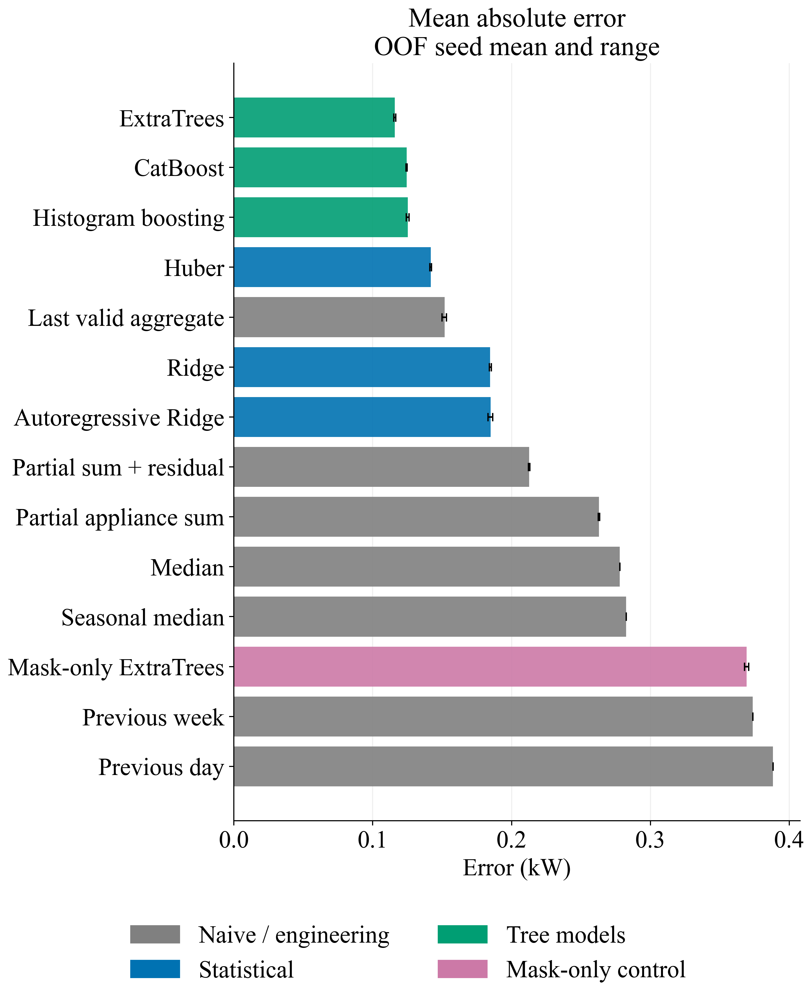

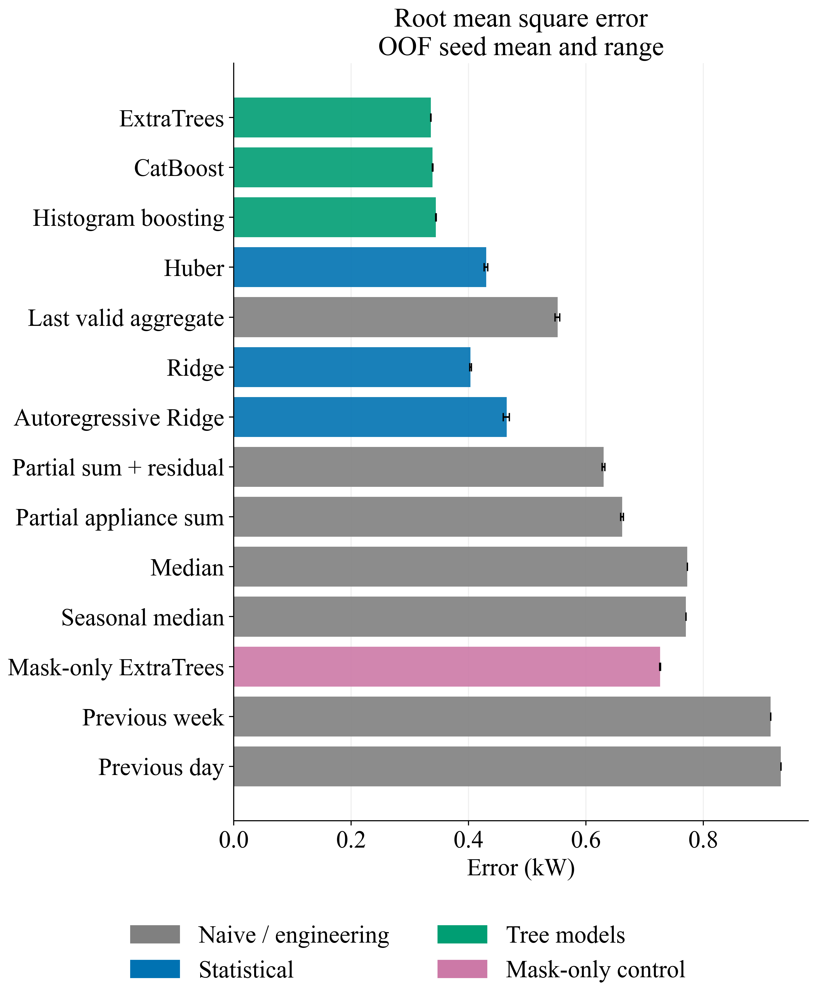

In [1]:
# Restore only a missing presentation dependency from its exact saved scientific table.
def _presentation_nb03_e598e71f_restore_summary():
    from pathlib import Path
    import hashlib
    import pandas as pd
    path = ROOT / 'Tables/guldana_n3_20261007_v01/03_baselines/all_baseline_primary_OOF.csv'
    assert hashlib.sha256(path.read_bytes()).hexdigest() == '62d00b7ae86af0423fef8b1a208291d05b750b7da0d38aebf64f9ac82be9c1be'
    frame = pd.read_csv(path, float_precision="round_trip").rename(columns={
        "Mean MAE (kW)": "MAE_mean", "Seed minimum MAE (kW)": "MAE_seed_min",
        "Seed maximum MAE (kW)": "MAE_seed_max", "Mean RMSE (kW)": "RMSE_mean",
        "Mean bias (kW)": "Bias_mean", "Negative prediction (%)": "Negative_percent"})
    assert frame.columns.tolist() == ["Model","MAE_mean","MAE_seed_min","MAE_seed_max","RMSE_mean","Bias_mean","Negative_percent"]
    assert len(frame) == 14 and frame.Model.is_unique
    return frame
if "summary" not in globals():
    summary = _presentation_nb03_e598e71f_restore_summary()

# Publication figures retain all baseline families and distinguish seed ranges from uncertainty intervals.
from matplotlib.patches import Patch
order=summary.Model.tolist()
def baseline_color(name):
    if name=="Mask_only_ExtraTrees":return "#CC79A7"
    if name in NAIVE_NAMES:return "#808080"
    if name in ["Ridge","Huber","Autoregressive_Ridge"]:return "#0072B2"
    return "#009E73"
labels=[name.replace("Autoregressive_Ridge","Autoregressive Ridge").replace("Mask_only_ExtraTrees","Mask-only ExtraTrees")
        .replace("HistGradientBoosting","Histogram boosting") for name in order]

# Isolated presentation renderer; original scientific artifacts remain immutable.
def _presentation_nb03_e598e71f():
    # Presentation only: load immutable, previously computed scientific results.
    from pathlib import Path
    import hashlib, json, textwrap
    import numpy as np
    import pandas as pd
    import matplotlib as mpl
    import matplotlib.pyplot as plt
    import matplotlib.dates as mdates
    from matplotlib import font_manager
    from matplotlib.text import Text
    from matplotlib.ticker import FuncFormatter, LogLocator
    from IPython.display import display, Image
    from PIL import Image as PILImage
    ROOT = Path.cwd().resolve()
    if ROOT.name == "Notebooks":
        ROOT = ROOT.parent
    assert ROOT.is_dir()
    INPUT_SHA256 = {'Tables/guldana_n3_20261007_v01/03_baselines/all_baseline_primary_OOF.csv': '62d00b7ae86af0423fef8b1a208291d05b750b7da0d38aebf64f9ac82be9c1be', 'Tables/guldana_n3_20261007_v01/03_baselines/all_baseline_seed_17.csv': 'f15d6167aeb5d5df86a1c6d021f73364a3bd3bea10c024c63e8ba8564e3c07d9', 'Tables/guldana_n3_20261007_v01/03_baselines/all_baseline_seed_43.csv': '0c5d483379d7aa2a86d1a896bf9f3b431d5b6530a36644f60a01b3d5d62dacd9', 'Tables/guldana_n3_20261007_v01/03_baselines/all_baseline_seed_101.csv': '90ad9cecf517ed3facbe32051efd35272c32f1d5bba3b6245fddafbfd983eb32'}
    for _relative, _expected in INPUT_SHA256.items():
        assert hashlib.sha256((ROOT / _relative).read_bytes()).hexdigest() == _expected, _relative
    assert Path(font_manager.findfont("Times New Roman", fallback_to_default=False)).is_file()
    mpl.rcParams.update({"font.family": "Times New Roman", "font.size": 18,
        "axes.titlesize": 20, "axes.labelsize": 18, "xtick.labelsize": 18,
        "ytick.labelsize": 18, "legend.fontsize": 18, "figure.dpi": 350,
        "savefig.dpi": 350, "axes.unicode_minus": True, "pdf.fonttype": 42,
        "ps.fonttype": 42, "axes.formatter.use_mathtext": False})
    _PNG = ROOT / "Figures/PNG/guldana_n3_20261011_presentation/NB03"
    _PDF = ROOT / "Figures/PDF/guldana_n3_20261011_presentation/NB03"
    _PNG.mkdir(parents=True, exist_ok=True)
    _PDF.mkdir(parents=True, exist_ok=True)
    def _label(name, width=22):
        name = str(name).replace("HistGradientBoosting", "Histogram boosting").replace("Mask_only_ExtraTrees", "Mask-only ExtraTrees").replace("Autoregressive_Ridge", "Autoregressive Ridge")
        return "\n".join(textwrap.wrap(name, width=width, break_long_words=False, break_on_hyphens=False))
    def _num(value, decimals=2):
        return f"{value:.{decimals}f}".replace("-", "−")
    def _quiet_axes(ax):
        ax.grid(alpha=.20)
        ax.spines[["top", "right"]].set_visible(False)
    def _export(fig, stem):
        fig.canvas.draw()
        for artist in fig.findobj(Text):
            if artist.get_visible() and artist.get_text():
                assert 18 <= artist.get_fontsize() <= 20, (artist.get_text(), artist.get_fontsize())
                assert artist.get_fontfamily() == ["Times New Roman"], artist.get_fontfamily()
        png = _PNG / (stem + ".png")
        pdf = _PDF / (stem + ".pdf")
        fig.savefig(png, dpi=350, bbox_inches="tight", pad_inches=.08)
        fig.savefig(pdf, dpi=350, bbox_inches="tight", pad_inches=.08)
        with PILImage.open(png) as image:
            assert all(abs(d - 350) < .02 for d in image.info["dpi"])
        plt.close(fig)
        display(Image(filename=str(png)))

    summary = pd.read_csv(ROOT / "Tables/guldana_n3_20261007_v01/03_baselines/all_baseline_primary_OOF.csv")
    order = summary.Model.tolist()
    seed_metrics = pd.concat([pd.read_csv(ROOT / f"Tables/guldana_n3_20261007_v01/03_baselines/all_baseline_seed_{s}.csv") for s in [17,43,101]], ignore_index=True)
    assert len(order) == 14 and len(seed_metrics) == 42
    _naive = ["Median", "Last valid aggregate", "Seasonal median", "Previous day", "Previous week", "Partial appliance sum", "Partial sum + residual"]
    def _baseline_color(name):
        if name == "Mask_only_ExtraTrees": return "#CC79A7"
        if name in _naive: return "#808080"
        if name in ["Ridge", "Huber", "Autoregressive_Ridge"]: return "#0072B2"
        return "#009E73"
    from matplotlib.patches import Patch
    for metric, title, suffix in [("House-macro MAE (kW)", "Mean absolute error", "MAE"), ("House-macro RMSE (kW)", "Root mean square error", "RMSE")]:
        values = seed_metrics.groupby("Model")[metric].agg(["mean", "min", "max"]).reindex(order)
        fig, ax = plt.subplots(figsize=(8.8, 10.6))
        ax.barh(np.arange(len(order)), values["mean"], color=[_baseline_color(n) for n in order], alpha=.9)
        widths = np.vstack([values["mean"]-values["min"], values["max"]-values["mean"]])
        assert widths.min() >= -1e-12
        ax.errorbar(values["mean"], np.arange(len(order)), xerr=np.maximum(widths,0), fmt="none", ecolor="black", capsize=3, lw=1.2)
        ax.set_yticks(np.arange(len(order)), [_label(n) for n in order]); ax.invert_yaxis()
        ax.set(xlabel="Error (kW)", title=title + "\nOOF seed mean and range")
        ax.grid(axis="x", alpha=.2); ax.set_axisbelow(True); ax.spines[["top","right"]].set_visible(False)
        handles = [Patch(color=c,label=l) for c,l in [("#808080","Naive / engineering"),("#0072B2","Statistical"),("#009E73","Tree models"),("#CC79A7","Mask-only control")]]
        fig.legend(handles=handles, loc="lower center", bbox_to_anchor=(.5,.005), ncol=2, frameon=False)
        fig.tight_layout(rect=(0,.10,1,1))
        _export(fig, "16_baseline_OOF_comparison_" + suffix)

_presentation_nb03_e598e71f()


In [66]:
# Full house-by-model error matrix; no house is hidden by a population-weighted average.
matrix=house_errors.groupby(["Model","House"])["MAE (kW)"].mean().unstack().reindex(order)
table(matrix.reset_index(),"baseline_house_MAE","Table 17. Complete house-by-model MAE matrix; mean across seeds and three OOF periods.")


Model,1,2,3,4,5
ExtraTrees,0.0771,0.1544,0.0875,0.1024,0.2621
CatBoost,0.0940,0.1638,0.0938,0.1035,0.2735
HistGradientBoosting,0.0990,0.1668,0.0944,0.1052,0.2737
Huber,0.1139,0.1901,0.1254,0.1263,0.3128
Last valid aggregate,0.1171,0.2021,0.1399,0.1433,0.3496
Ridge,0.1919,0.2450,0.1717,0.1643,0.3575
Autoregressive_Ridge,0.1672,0.2514,0.1799,0.1654,0.3571
Partial sum + residual,0.1416,0.2995,0.1872,0.2014,0.4030
Partial appliance sum,0.1666,0.3330,0.2319,0.2739,0.4881
Median,0.2542,0.3768,0.2724,0.2797,0.5050


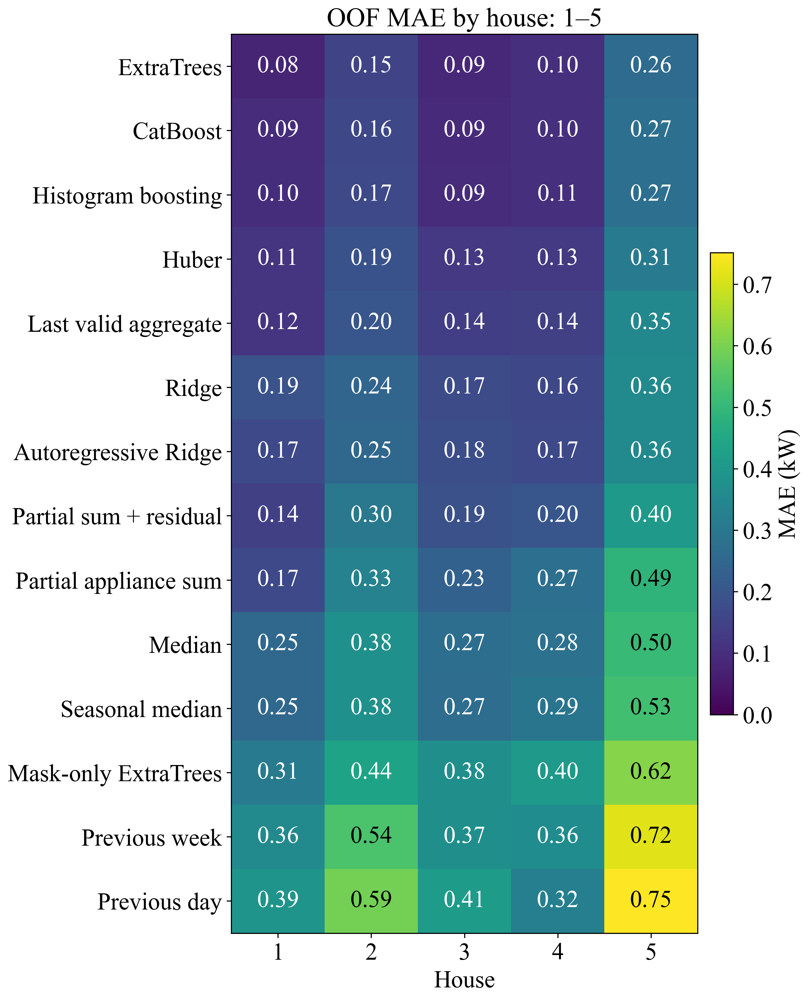

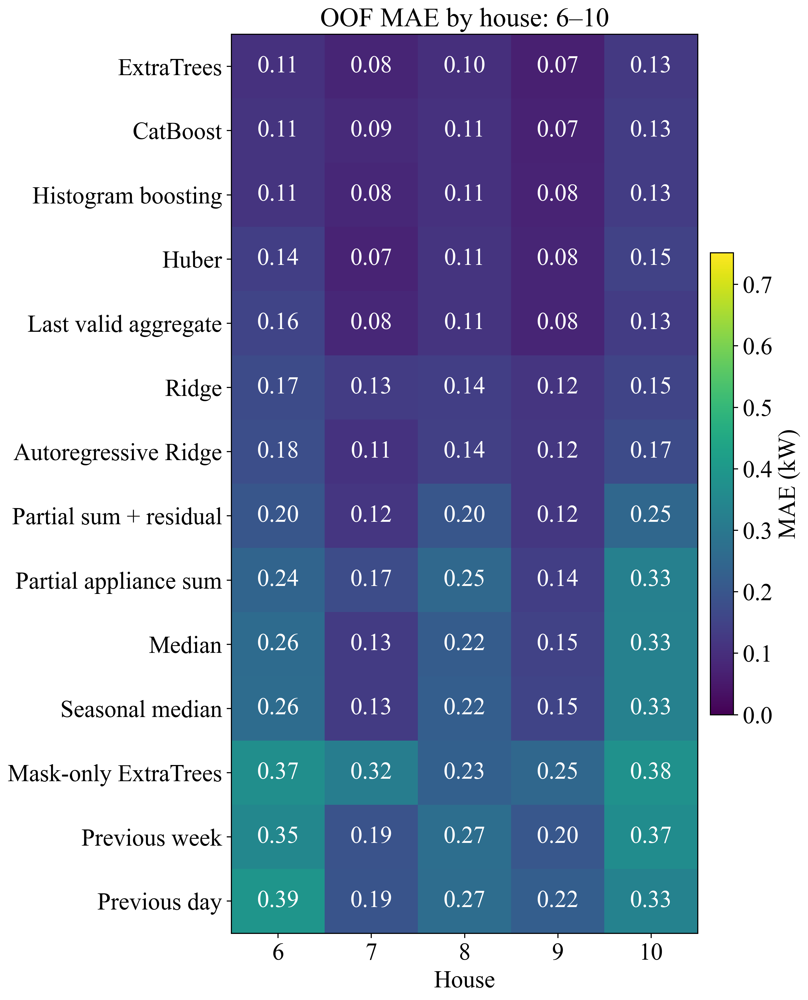

In [8]:
# Re-render archived scientific figures; this cell does not train models or recompute metrics.
def _presentation_nb03_913c170c():
    # Presentation only: load immutable, previously computed scientific results.
    from pathlib import Path
    import hashlib, json, textwrap
    import numpy as np
    import pandas as pd
    import matplotlib as mpl
    import matplotlib.pyplot as plt
    import matplotlib.dates as mdates
    from matplotlib import font_manager
    from matplotlib.text import Text
    from matplotlib.ticker import FuncFormatter, LogLocator
    from IPython.display import display, Image
    from PIL import Image as PILImage
    ROOT = Path.cwd().resolve()
    if ROOT.name == "Notebooks":
        ROOT = ROOT.parent
    assert ROOT.is_dir()
    INPUT_SHA256 = {'Tables/guldana_n3_20261007_v01/03_baselines/all_baseline_primary_OOF.csv': '62d00b7ae86af0423fef8b1a208291d05b750b7da0d38aebf64f9ac82be9c1be', 'Tables/guldana_n3_20261007_v01/03_baselines/baseline_house_MAE.csv': '63d3ba270ecbae19d015eb45eb362e31acb68c2fb989da5ae68e9eff0843b380'}
    for _relative, _expected in INPUT_SHA256.items():
        assert hashlib.sha256((ROOT / _relative).read_bytes()).hexdigest() == _expected, _relative
    assert Path(font_manager.findfont("Times New Roman", fallback_to_default=False)).is_file()
    mpl.rcParams.update({"font.family": "Times New Roman", "font.size": 18,
        "axes.titlesize": 20, "axes.labelsize": 18, "xtick.labelsize": 18,
        "ytick.labelsize": 18, "legend.fontsize": 18, "figure.dpi": 350,
        "savefig.dpi": 350, "axes.unicode_minus": True, "pdf.fonttype": 42,
        "ps.fonttype": 42, "axes.formatter.use_mathtext": False})
    _PNG = ROOT / "Figures/PNG/guldana_n3_20261011_presentation/NB03"
    _PDF = ROOT / "Figures/PDF/guldana_n3_20261011_presentation/NB03"
    _PNG.mkdir(parents=True, exist_ok=True)
    _PDF.mkdir(parents=True, exist_ok=True)
    def _label(name, width=22):
        name = str(name).replace("HistGradientBoosting", "Histogram boosting").replace("Mask_only_ExtraTrees", "Mask-only ExtraTrees").replace("Autoregressive_Ridge", "Autoregressive Ridge")
        return "\n".join(textwrap.wrap(name, width=width, break_long_words=False, break_on_hyphens=False))
    def _num(value, decimals=2):
        return f"{value:.{decimals}f}".replace("-", "−")
    def _quiet_axes(ax):
        ax.grid(alpha=.20)
        ax.spines[["top", "right"]].set_visible(False)
    def _export(fig, stem):
        fig.canvas.draw()
        for artist in fig.findobj(Text):
            if artist.get_visible() and artist.get_text():
                assert 18 <= artist.get_fontsize() <= 20, (artist.get_text(), artist.get_fontsize())
                assert artist.get_fontfamily() == ["Times New Roman"], artist.get_fontfamily()
        png = _PNG / (stem + ".png")
        pdf = _PDF / (stem + ".pdf")
        fig.savefig(png, dpi=350, bbox_inches="tight", pad_inches=.08)
        fig.savefig(pdf, dpi=350, bbox_inches="tight", pad_inches=.08)
        with PILImage.open(png) as image:
            assert all(abs(d - 350) < .02 for d in image.info["dpi"])
        plt.close(fig)
        display(Image(filename=str(png)))

    order = pd.read_csv(ROOT / "Tables/guldana_n3_20261007_v01/03_baselines/all_baseline_primary_OOF.csv").Model.tolist()
    matrix = pd.read_csv(ROOT / "Tables/guldana_n3_20261007_v01/03_baselines/baseline_house_MAE.csv").set_index("Model").reindex(order)
    matrix.columns = matrix.columns.astype(int)
    assert np.isfinite(matrix.to_numpy()).all()
    _vmax = float(matrix.max().max())
    for _cols, _ticks, _title, _stem in [([1, 2, 3, 4, 5], ['1', '2', '3', '4', '5'], 'OOF MAE by house: 1–5', '17_baseline_house_errors_1_5'), ([6, 7, 8, 9, 10], ['6', '7', '8', '9', '10'], 'OOF MAE by house: 6–10', '17_baseline_house_errors_6_10')]:
        _view = matrix.loc[:, _cols]
        fig, ax = plt.subplots(figsize=(8.8, 10.8))
        im = ax.imshow(_view.to_numpy(), aspect="auto", cmap="viridis", vmin=0, vmax=_vmax)
        ax.set_xticks(np.arange(len(_cols)), _ticks)
        ax.set_yticks(np.arange(len(order)), [_label(n) for n in order])
        ax.set_title(_title); ax.set_xlabel("House")
        for i in range(len(order)):
            for j in range(len(_cols)):
                value = _view.iloc[i,j]; rgba = im.cmap(im.norm(value))
                luminance = .2126*rgba[0] + .7152*rgba[1] + .0722*rgba[2]
                ax.text(j, i, _num(value,2), ha="center", va="center", color="black" if luminance>.55 else "white", fontsize=18)
        fig.colorbar(im, ax=ax, pad=.025, fraction=.046).set_label("MAE (kW)")
        fig.tight_layout()
        _export(fig, _stem)

_presentation_nb03_913c170c()


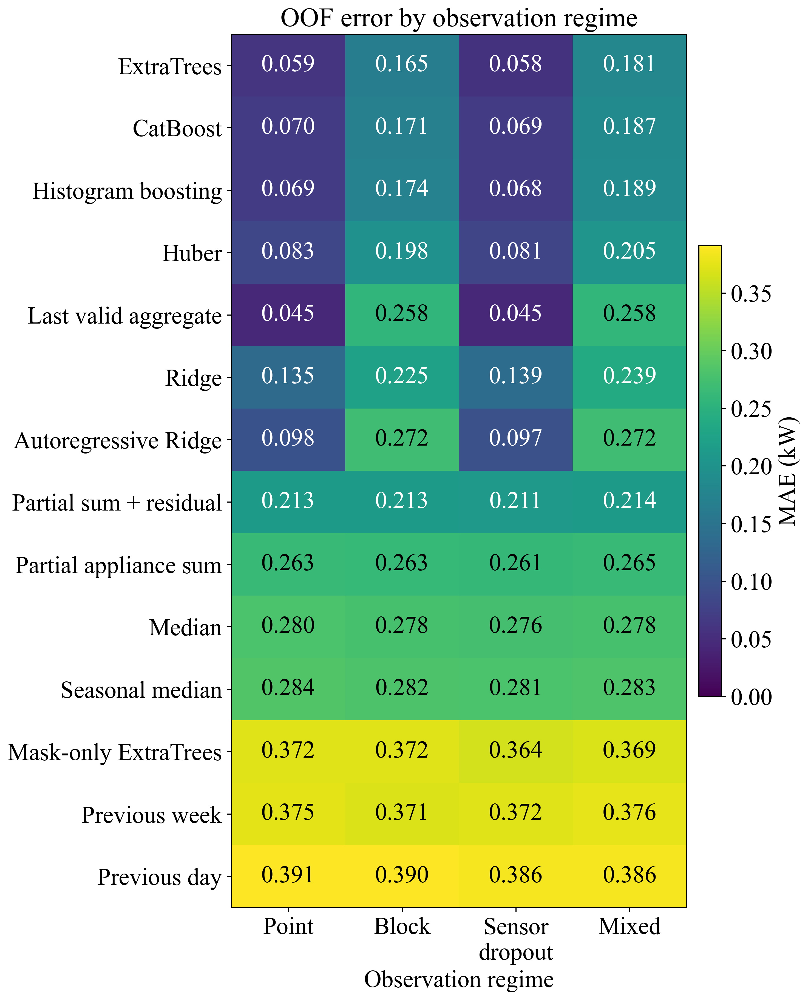

In [2]:
# Isolated presentation renderer; original scientific artifacts remain immutable.
def _presentation_nb03_0bfa59a3():
    # Presentation only: load immutable, previously computed scientific results.
    from pathlib import Path
    import hashlib, json, textwrap
    import numpy as np
    import pandas as pd
    import matplotlib as mpl
    import matplotlib.pyplot as plt
    import matplotlib.dates as mdates
    from matplotlib import font_manager
    from matplotlib.text import Text
    from matplotlib.ticker import FuncFormatter, LogLocator
    from IPython.display import display, Image
    from PIL import Image as PILImage
    ROOT = Path.cwd().resolve()
    if ROOT.name == "Notebooks":
        ROOT = ROOT.parent
    assert ROOT.is_dir()
    INPUT_SHA256 = {'Tables/guldana_n3_20261007_v01/03_baselines/all_baseline_primary_OOF.csv': '62d00b7ae86af0423fef8b1a208291d05b750b7da0d38aebf64f9ac82be9c1be', 'Tables/guldana_n3_20261007_v01/03_baselines/baseline_by_mode.csv': '81f74a7da07f6e7d434b3ba2e59d11f42b736093e2a07abd862aa82f2a504f35'}
    for _relative, _expected in INPUT_SHA256.items():
        assert hashlib.sha256((ROOT / _relative).read_bytes()).hexdigest() == _expected, _relative
    assert Path(font_manager.findfont("Times New Roman", fallback_to_default=False)).is_file()
    mpl.rcParams.update({"font.family": "Times New Roman", "font.size": 18,
        "axes.titlesize": 20, "axes.labelsize": 18, "xtick.labelsize": 18,
        "ytick.labelsize": 18, "legend.fontsize": 18, "figure.dpi": 350,
        "savefig.dpi": 350, "axes.unicode_minus": True, "pdf.fonttype": 42,
        "ps.fonttype": 42, "axes.formatter.use_mathtext": False})
    _PNG = ROOT / "Figures/PNG/guldana_n3_20261011_presentation/NB03"
    _PDF = ROOT / "Figures/PDF/guldana_n3_20261011_presentation/NB03"
    _PNG.mkdir(parents=True, exist_ok=True)
    _PDF.mkdir(parents=True, exist_ok=True)
    def _label(name, width=22):
        name = str(name).replace("HistGradientBoosting", "Histogram boosting").replace("Mask_only_ExtraTrees", "Mask-only ExtraTrees").replace("Autoregressive_Ridge", "Autoregressive Ridge")
        return "\n".join(textwrap.wrap(name, width=width, break_long_words=False, break_on_hyphens=False))
    def _num(value, decimals=2):
        return f"{value:.{decimals}f}".replace("-", "−")
    def _quiet_axes(ax):
        ax.grid(alpha=.20)
        ax.spines[["top", "right"]].set_visible(False)
    def _export(fig, stem):
        fig.canvas.draw()
        for artist in fig.findobj(Text):
            if artist.get_visible() and artist.get_text():
                assert 18 <= artist.get_fontsize() <= 20, (artist.get_text(), artist.get_fontsize())
                assert artist.get_fontfamily() == ["Times New Roman"], artist.get_fontfamily()
        png = _PNG / (stem + ".png")
        pdf = _PDF / (stem + ".pdf")
        fig.savefig(png, dpi=350, bbox_inches="tight", pad_inches=.08)
        fig.savefig(pdf, dpi=350, bbox_inches="tight", pad_inches=.08)
        with PILImage.open(png) as image:
            assert all(abs(d - 350) < .02 for d in image.info["dpi"])
        plt.close(fig)
        display(Image(filename=str(png)))

    order = pd.read_csv(ROOT / "Tables/guldana_n3_20261007_v01/03_baselines/all_baseline_primary_OOF.csv").Model.tolist()
    matrix = pd.read_csv(ROOT / "Tables/guldana_n3_20261007_v01/03_baselines/baseline_by_mode.csv").set_index("Model").reindex(order)
    matrix = matrix.reindex(columns=["point","block","sensor_dropout","mixed"])
    assert np.isfinite(matrix.to_numpy()).all()
    _vmax = float(matrix.max().max())
    for _cols, _ticks, _title, _stem in [(['point', 'block', 'sensor_dropout', 'mixed'], ['Point', 'Block', 'Sensor\ndropout', 'Mixed'], 'OOF error by observation regime', '18_baseline_observation_regimes')]:
        _view = matrix.loc[:, _cols]
        fig, ax = plt.subplots(figsize=(8.8, 10.8))
        im = ax.imshow(_view.to_numpy(), aspect="auto", cmap="viridis", vmin=0, vmax=_vmax)
        ax.set_xticks(np.arange(len(_cols)), _ticks)
        ax.set_yticks(np.arange(len(order)), [_label(n) for n in order])
        ax.set_title(_title); ax.set_xlabel("Observation regime")
        for i in range(len(order)):
            for j in range(len(_cols)):
                value = _view.iloc[i,j]; rgba = im.cmap(im.norm(value))
                luminance = .2126*rgba[0] + .7152*rgba[1] + .0722*rgba[2]
                ax.text(j, i, _num(value,3), ha="center", va="center", color="black" if luminance>.55 else "white", fontsize=18)
        fig.colorbar(im, ax=ax, pad=.025, fraction=.046).set_label("MAE (kW)")
        fig.tight_layout()
        _export(fig, _stem)

_presentation_nb03_0bfa59a3()


**Learning-history reading.** Curves show actual inner-validation MAE, including the Huber optimizer continuation described above. Histogram boosting and CatBoost retain their best inner checkpoint; the last displayed iterate need not be the saved checkpoint. Ridge and the autoregressive Ridge solve a fixed regularized linear problem, so they have no epoch learning trajectory.

In [68]:
# Inspect actual optimization histories. The vertical axis is the same inner-validation MAE for every family.
from matplotlib.lines import Line2D
def plot_baseline_learning(fold,figure_number):
    families=["Huber","ExtraTrees","HistGradientBoosting","CatBoost","Mask_only_ExtraTrees"]
    fig=plt.figure(figsize=(17,10));grid=fig.add_gridspec(2,6)
    slots=[grid[0,0:2],grid[0,2:4],grid[0,4:6],grid[1,1:3],grid[1,3:5]]
    for family,slot in zip(families,slots):
        ax=fig.add_subplot(slot)
        for seed,color,style in zip([17,43,101],["#0072B2","#D55E00","#009E73"],["-","--","-."]):
            history=pd.read_csv(HISTORY_DIR/f"{family}_fold_{fold}_seed_{seed}.csv")
            ax.plot(history.iteration,history.inner_house_macro_MAE_kW,color=color,ls=style,lw=1.7,
                marker="o" if len(history)<15 else None,markersize=4,label=f"Seed {seed}")
        ax.set_title(family.replace("HistGradientBoosting","Histogram boosting").replace("Mask_only_ExtraTrees","Mask-only ExtraTrees"))
        ax.set_xlabel("Trees" if "ExtraTrees" in family else "Optimization iterations")
        ax.set_ylabel("Inner MAE (kW)");ax.grid(alpha=.2);ax.spines[["top","right"]].set_visible(False)
    fig.legend(handles=[Line2D([0],[0],color=c,ls=l,label=f"Seed {s}") for s,c,l in zip(
        [17,43,101],["#0072B2","#D55E00","#009E73"],["-","--","-."])],
        loc="lower center",bbox_to_anchor=(.5,-.01),ncol=3,frameon=False)
    fig.tight_layout(rect=(0,.055,1,1));save_figure(fig,f"{figure_number:02d}_baseline_learning_fold_{fold}")


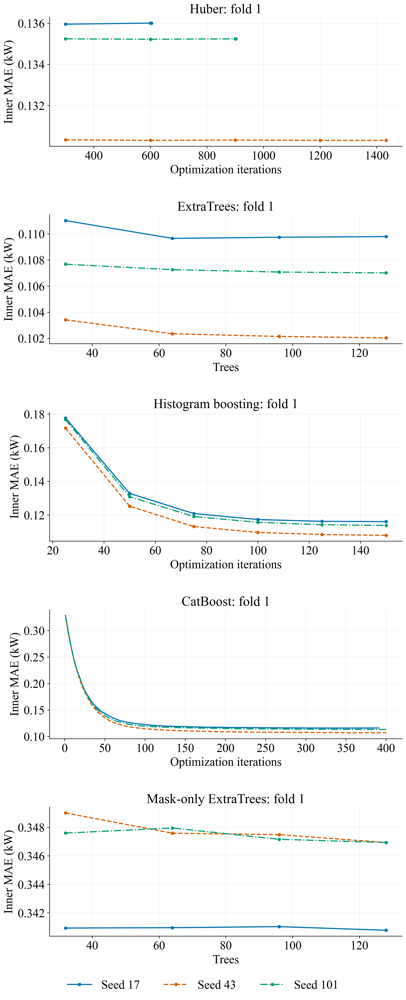

In [3]:
# Isolated presentation renderer; original scientific artifacts remain immutable.
def _presentation_nb03_fdd06c79():
    # Presentation only: load immutable, previously computed scientific results.
    from pathlib import Path
    import hashlib, json, textwrap
    import numpy as np
    import pandas as pd
    import matplotlib as mpl
    import matplotlib.pyplot as plt
    import matplotlib.dates as mdates
    from matplotlib import font_manager
    from matplotlib.text import Text
    from matplotlib.ticker import FuncFormatter, LogLocator
    from IPython.display import display, Image
    from PIL import Image as PILImage
    ROOT = Path.cwd().resolve()
    if ROOT.name == "Notebooks":
        ROOT = ROOT.parent
    assert ROOT.is_dir()
    INPUT_SHA256 = {'Models/baselines/guldana_n3_20261007_v01/histories/Huber_fold_1_seed_17.csv': 'afeb1026a6165e6050dd147dea8d445dc2496edd849b4009ad1ad9efe5179fc8', 'Models/baselines/guldana_n3_20261007_v01/histories/Huber_fold_1_seed_43.csv': 'bbc83cf46becc7b2bf3cb31fe81f63a1c71c6ae2ba0952b0d512b935394d118e', 'Models/baselines/guldana_n3_20261007_v01/histories/Huber_fold_1_seed_101.csv': '194fbc4f0c597615e6dc45d9ba45dd2b871c063c43cccf077f77d66ccc53ed94', 'Models/baselines/guldana_n3_20261007_v01/histories/ExtraTrees_fold_1_seed_17.csv': '16e2fda30be3ef420fa260dd96a59c47b08d26e956f50281c8799a22e9421c60', 'Models/baselines/guldana_n3_20261007_v01/histories/ExtraTrees_fold_1_seed_43.csv': '0a7ae80591674f409e76a180abe616c39ede841345dafbf6994535b52f83fec1', 'Models/baselines/guldana_n3_20261007_v01/histories/ExtraTrees_fold_1_seed_101.csv': 'a11cc820bfb20124204bdbd6283ad886ef1cbe8e51dc27db269c2d5a90f41ab6', 'Models/baselines/guldana_n3_20261007_v01/histories/HistGradientBoosting_fold_1_seed_17.csv': 'a337c234f787a3e04bf24b53b6d67d242570d0f225df10b311163d9c5627798e', 'Models/baselines/guldana_n3_20261007_v01/histories/HistGradientBoosting_fold_1_seed_43.csv': 'abca7966ac3764725ea5fcd1cb22267a809be1f9e7c139d9fc603f5e6300622f', 'Models/baselines/guldana_n3_20261007_v01/histories/HistGradientBoosting_fold_1_seed_101.csv': '2090b3867ddcb793ff04b733d52a842f468a59141365c6be1d26b85edda0a61b', 'Models/baselines/guldana_n3_20261007_v01/histories/CatBoost_fold_1_seed_17.csv': '5442460cf4649a8d96b553cb79e7f279b54b39385b75c73e68ac0c071258a0be', 'Models/baselines/guldana_n3_20261007_v01/histories/CatBoost_fold_1_seed_43.csv': 'a01b8c17b907f17e4100ee9a778beff162934b70a5528c55788329eb7667ee6b', 'Models/baselines/guldana_n3_20261007_v01/histories/CatBoost_fold_1_seed_101.csv': '5632d6f3a5818c2f5d853b56293a2dfea365a38d2a78bf247472e488df4fa710', 'Models/baselines/guldana_n3_20261007_v01/histories/Mask_only_ExtraTrees_fold_1_seed_17.csv': 'f819876dda2a53f2c17073a83ceda55b923c0dc98882f1735892ce8a438c7c9b', 'Models/baselines/guldana_n3_20261007_v01/histories/Mask_only_ExtraTrees_fold_1_seed_43.csv': 'bf41c1df2bee5053cf9e5ff00796ddb1d5e18a3a581184d08371fe4deb9569a6', 'Models/baselines/guldana_n3_20261007_v01/histories/Mask_only_ExtraTrees_fold_1_seed_101.csv': '0eb14e0eb4a0c166c5781c0c8aed083319e869b819b29117c0b83b3533f8c985'}
    for _relative, _expected in INPUT_SHA256.items():
        assert hashlib.sha256((ROOT / _relative).read_bytes()).hexdigest() == _expected, _relative
    assert Path(font_manager.findfont("Times New Roman", fallback_to_default=False)).is_file()
    mpl.rcParams.update({"font.family": "Times New Roman", "font.size": 18,
        "axes.titlesize": 20, "axes.labelsize": 18, "xtick.labelsize": 18,
        "ytick.labelsize": 18, "legend.fontsize": 18, "figure.dpi": 350,
        "savefig.dpi": 350, "axes.unicode_minus": True, "pdf.fonttype": 42,
        "ps.fonttype": 42, "axes.formatter.use_mathtext": False})
    _PNG = ROOT / "Figures/PNG/guldana_n3_20261011_presentation/NB03"
    _PDF = ROOT / "Figures/PDF/guldana_n3_20261011_presentation/NB03"
    _PNG.mkdir(parents=True, exist_ok=True)
    _PDF.mkdir(parents=True, exist_ok=True)
    def _label(name, width=22):
        name = str(name).replace("HistGradientBoosting", "Histogram boosting").replace("Mask_only_ExtraTrees", "Mask-only ExtraTrees").replace("Autoregressive_Ridge", "Autoregressive Ridge")
        return "\n".join(textwrap.wrap(name, width=width, break_long_words=False, break_on_hyphens=False))
    def _num(value, decimals=2):
        return f"{value:.{decimals}f}".replace("-", "−")
    def _quiet_axes(ax):
        ax.grid(alpha=.20)
        ax.spines[["top", "right"]].set_visible(False)
    def _export(fig, stem):
        fig.canvas.draw()
        for artist in fig.findobj(Text):
            if artist.get_visible() and artist.get_text():
                assert 18 <= artist.get_fontsize() <= 20, (artist.get_text(), artist.get_fontsize())
                assert artist.get_fontfamily() == ["Times New Roman"], artist.get_fontfamily()
        png = _PNG / (stem + ".png")
        pdf = _PDF / (stem + ".pdf")
        fig.savefig(png, dpi=350, bbox_inches="tight", pad_inches=.08)
        fig.savefig(pdf, dpi=350, bbox_inches="tight", pad_inches=.08)
        with PILImage.open(png) as image:
            assert all(abs(d - 350) < .02 for d in image.info["dpi"])
        plt.close(fig)
        display(Image(filename=str(png)))

    from matplotlib.lines import Line2D
    fold = 1
    families = ['Huber', 'ExtraTrees', 'HistGradientBoosting', 'CatBoost', 'Mask_only_ExtraTrees']
    fig, axes = plt.subplots(len(families), 1, figsize=(8.8, 21.0))
    for ax, family in zip(axes, families):
        for seed, color, style in zip([17,43,101], ["#0072B2","#D55E00","#009E73"], ["-","--","-."]):
            history = pd.read_csv(ROOT / f"Models/baselines/guldana_n3_20261007_v01/histories/{family}_fold_{fold}_seed_{seed}.csv")
            assert np.isfinite(history[["iteration","inner_house_macro_MAE_kW"]]).all().all()
            ax.plot(history.iteration, history.inner_house_macro_MAE_kW, color=color, ls=style, lw=1.7, marker="o" if len(history)<15 else None, markersize=4, label=f"Seed {seed}")
        ax.set(title=_label(family,40) + f": fold {fold}", xlabel="Trees" if "ExtraTrees" in family else "Optimization iterations", ylabel="Inner MAE (kW)")
        _quiet_axes(ax)
    handles, names = axes[0].get_legend_handles_labels()
    fig.legend(handles,names,loc="lower center",bbox_to_anchor=(.5,.002),ncol=3,frameon=False)
    fig.tight_layout(rect=(0,.025,1,1), h_pad=2.1)
    _export(fig, "19_baseline_learning_fold_1")

_presentation_nb03_fdd06c79()


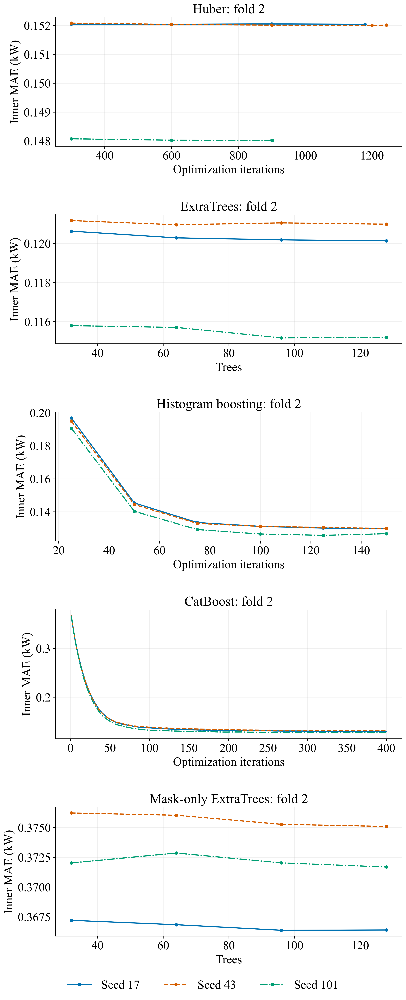

In [4]:
# Isolated presentation renderer; original scientific artifacts remain immutable.
def _presentation_nb03_59c42f3d():
    # Presentation only: load immutable, previously computed scientific results.
    from pathlib import Path
    import hashlib, json, textwrap
    import numpy as np
    import pandas as pd
    import matplotlib as mpl
    import matplotlib.pyplot as plt
    import matplotlib.dates as mdates
    from matplotlib import font_manager
    from matplotlib.text import Text
    from matplotlib.ticker import FuncFormatter, LogLocator
    from IPython.display import display, Image
    from PIL import Image as PILImage
    ROOT = Path.cwd().resolve()
    if ROOT.name == "Notebooks":
        ROOT = ROOT.parent
    assert ROOT.is_dir()
    INPUT_SHA256 = {'Models/baselines/guldana_n3_20261007_v01/histories/Huber_fold_2_seed_17.csv': 'a84492f6cc479ea5d1ccc0b566960c6a7f3173d60cf74c664316d51f2489107d', 'Models/baselines/guldana_n3_20261007_v01/histories/Huber_fold_2_seed_43.csv': '9814c4e024eeb9c2f248c9aad19955540e7ac4df08b762dcdec957bd17fd3abf', 'Models/baselines/guldana_n3_20261007_v01/histories/Huber_fold_2_seed_101.csv': '0dff57884d55dc60585ed00146ec1c6360e5a82d546db791babcb9262a24b518', 'Models/baselines/guldana_n3_20261007_v01/histories/ExtraTrees_fold_2_seed_17.csv': '2adc66d756945da36c21ea03ebc324973d5c5f78c657a809bf4f4e93c5dac310', 'Models/baselines/guldana_n3_20261007_v01/histories/ExtraTrees_fold_2_seed_43.csv': '19479d9d64e6529cc971f8ebd083bdbfe27667842221452cfd71063b6523f290', 'Models/baselines/guldana_n3_20261007_v01/histories/ExtraTrees_fold_2_seed_101.csv': 'caf4a8d24799c0a51799cd115add864458e6e6bb5a14a8dc8383e38f43a121ec', 'Models/baselines/guldana_n3_20261007_v01/histories/HistGradientBoosting_fold_2_seed_17.csv': 'b899663e4463d1db8200bd4b2df9b85368ae9063d26f49b2801c9b5fced13671', 'Models/baselines/guldana_n3_20261007_v01/histories/HistGradientBoosting_fold_2_seed_43.csv': '4f30d7e17ccfd10aae81fdf8138bbe3d9e701371b204595ed49ad3d330a5e7dc', 'Models/baselines/guldana_n3_20261007_v01/histories/HistGradientBoosting_fold_2_seed_101.csv': '4c43c502c0ad4f9ff8428849474efe12dcb7c5dce4d4564384b5378e448fb551', 'Models/baselines/guldana_n3_20261007_v01/histories/CatBoost_fold_2_seed_17.csv': '0a6e9280b99ad3ec679d528872fe6f926d0c5ea30e6733872ce0721650f9f6a2', 'Models/baselines/guldana_n3_20261007_v01/histories/CatBoost_fold_2_seed_43.csv': '2245e9d2535f524443d69cd13cfb31660b2dbbb3c6ec3fdfe8f29d6ab10b7d2b', 'Models/baselines/guldana_n3_20261007_v01/histories/CatBoost_fold_2_seed_101.csv': 'e0aecc4be192aaf6644273cf251c24f43e1ad0d67ef6188e7135d50a5bfd9226', 'Models/baselines/guldana_n3_20261007_v01/histories/Mask_only_ExtraTrees_fold_2_seed_17.csv': '1918a56ea85d3c5e6314b46ffa6742a154f4448de82b13b413c206629d870692', 'Models/baselines/guldana_n3_20261007_v01/histories/Mask_only_ExtraTrees_fold_2_seed_43.csv': 'a9b7f9b6c99c8d6b818017c58d3692cc1fc81b9e540a0fed07b13fe6edd6ccba', 'Models/baselines/guldana_n3_20261007_v01/histories/Mask_only_ExtraTrees_fold_2_seed_101.csv': '6a66ea0197999d12559c2c7cd51fb437abe88322f3dea8020d38086017010cc2'}
    for _relative, _expected in INPUT_SHA256.items():
        assert hashlib.sha256((ROOT / _relative).read_bytes()).hexdigest() == _expected, _relative
    assert Path(font_manager.findfont("Times New Roman", fallback_to_default=False)).is_file()
    mpl.rcParams.update({"font.family": "Times New Roman", "font.size": 18,
        "axes.titlesize": 20, "axes.labelsize": 18, "xtick.labelsize": 18,
        "ytick.labelsize": 18, "legend.fontsize": 18, "figure.dpi": 350,
        "savefig.dpi": 350, "axes.unicode_minus": True, "pdf.fonttype": 42,
        "ps.fonttype": 42, "axes.formatter.use_mathtext": False})
    _PNG = ROOT / "Figures/PNG/guldana_n3_20261011_presentation/NB03"
    _PDF = ROOT / "Figures/PDF/guldana_n3_20261011_presentation/NB03"
    _PNG.mkdir(parents=True, exist_ok=True)
    _PDF.mkdir(parents=True, exist_ok=True)
    def _label(name, width=22):
        name = str(name).replace("HistGradientBoosting", "Histogram boosting").replace("Mask_only_ExtraTrees", "Mask-only ExtraTrees").replace("Autoregressive_Ridge", "Autoregressive Ridge")
        return "\n".join(textwrap.wrap(name, width=width, break_long_words=False, break_on_hyphens=False))
    def _num(value, decimals=2):
        return f"{value:.{decimals}f}".replace("-", "−")
    def _quiet_axes(ax):
        ax.grid(alpha=.20)
        ax.spines[["top", "right"]].set_visible(False)
    def _export(fig, stem):
        fig.canvas.draw()
        for artist in fig.findobj(Text):
            if artist.get_visible() and artist.get_text():
                assert 18 <= artist.get_fontsize() <= 20, (artist.get_text(), artist.get_fontsize())
                assert artist.get_fontfamily() == ["Times New Roman"], artist.get_fontfamily()
        png = _PNG / (stem + ".png")
        pdf = _PDF / (stem + ".pdf")
        fig.savefig(png, dpi=350, bbox_inches="tight", pad_inches=.08)
        fig.savefig(pdf, dpi=350, bbox_inches="tight", pad_inches=.08)
        with PILImage.open(png) as image:
            assert all(abs(d - 350) < .02 for d in image.info["dpi"])
        plt.close(fig)
        display(Image(filename=str(png)))

    from matplotlib.lines import Line2D
    fold = 2
    families = ['Huber', 'ExtraTrees', 'HistGradientBoosting', 'CatBoost', 'Mask_only_ExtraTrees']
    fig, axes = plt.subplots(len(families), 1, figsize=(8.8, 21.0))
    for ax, family in zip(axes, families):
        for seed, color, style in zip([17,43,101], ["#0072B2","#D55E00","#009E73"], ["-","--","-."]):
            history = pd.read_csv(ROOT / f"Models/baselines/guldana_n3_20261007_v01/histories/{family}_fold_{fold}_seed_{seed}.csv")
            assert np.isfinite(history[["iteration","inner_house_macro_MAE_kW"]]).all().all()
            ax.plot(history.iteration, history.inner_house_macro_MAE_kW, color=color, ls=style, lw=1.7, marker="o" if len(history)<15 else None, markersize=4, label=f"Seed {seed}")
        ax.set(title=_label(family,40) + f": fold {fold}", xlabel="Trees" if "ExtraTrees" in family else "Optimization iterations", ylabel="Inner MAE (kW)")
        _quiet_axes(ax)
    handles, names = axes[0].get_legend_handles_labels()
    fig.legend(handles,names,loc="lower center",bbox_to_anchor=(.5,.002),ncol=3,frameon=False)
    fig.tight_layout(rect=(0,.025,1,1), h_pad=2.1)
    _export(fig, "20_baseline_learning_fold_2")

_presentation_nb03_59c42f3d()


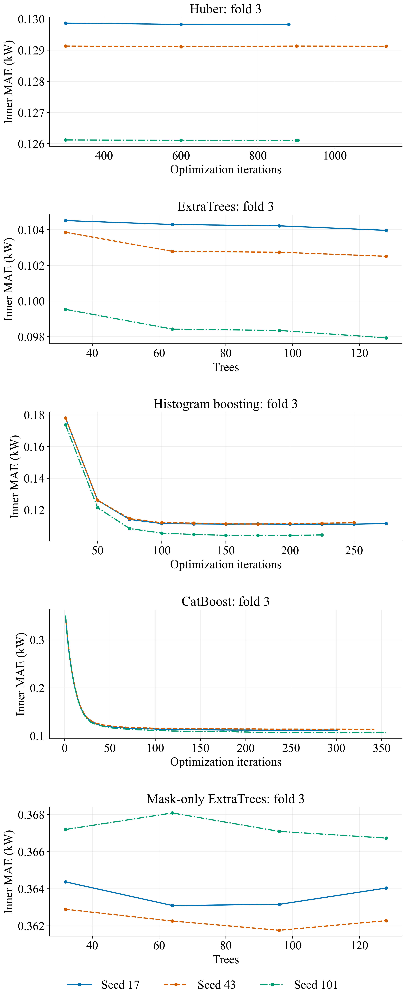

In [5]:
# Isolated presentation renderer; original scientific artifacts remain immutable.
def _presentation_nb03_dc7edcd0():
    # Presentation only: load immutable, previously computed scientific results.
    from pathlib import Path
    import hashlib, json, textwrap
    import numpy as np
    import pandas as pd
    import matplotlib as mpl
    import matplotlib.pyplot as plt
    import matplotlib.dates as mdates
    from matplotlib import font_manager
    from matplotlib.text import Text
    from matplotlib.ticker import FuncFormatter, LogLocator
    from IPython.display import display, Image
    from PIL import Image as PILImage
    ROOT = Path.cwd().resolve()
    if ROOT.name == "Notebooks":
        ROOT = ROOT.parent
    assert ROOT.is_dir()
    INPUT_SHA256 = {'Models/baselines/guldana_n3_20261007_v01/histories/Huber_fold_3_seed_17.csv': '3fb7dda7da34efed590100aed27db700c73580723f47678d2add6d623d2ead54', 'Models/baselines/guldana_n3_20261007_v01/histories/Huber_fold_3_seed_43.csv': '81e3c3df8dd6ae385387d6017b0666f0a5a572235b0544db9b11c70b78a3d394', 'Models/baselines/guldana_n3_20261007_v01/histories/Huber_fold_3_seed_101.csv': '04d07e249cc457e3bd4334f8c978b78c26729e7b3e56390fa38ea516d29a6e37', 'Models/baselines/guldana_n3_20261007_v01/histories/ExtraTrees_fold_3_seed_17.csv': 'b8c3c27a5178dde862b1284992fc8ea5d25a6056fff9fbea94ec4909de6a245d', 'Models/baselines/guldana_n3_20261007_v01/histories/ExtraTrees_fold_3_seed_43.csv': '3433889151b65e05577463146f36c3adb91b0297827563c976dfa32a096ff74f', 'Models/baselines/guldana_n3_20261007_v01/histories/ExtraTrees_fold_3_seed_101.csv': 'd86273dc4b0b2663a28faa38fa2e296a771c31a222d73920ff9354980c024776', 'Models/baselines/guldana_n3_20261007_v01/histories/HistGradientBoosting_fold_3_seed_17.csv': 'ab5651f683707b605633416cbe691f23debc429fc8e8b1d4378666c7c9fa99f0', 'Models/baselines/guldana_n3_20261007_v01/histories/HistGradientBoosting_fold_3_seed_43.csv': 'd44552078fd71d3d785dbba701e287cff2e63a48ff7567067b39249c43796cd8', 'Models/baselines/guldana_n3_20261007_v01/histories/HistGradientBoosting_fold_3_seed_101.csv': '42ec9f09fa79c79040009f951cfdc677efc8bd175ec5811afd0d208469a69667', 'Models/baselines/guldana_n3_20261007_v01/histories/CatBoost_fold_3_seed_17.csv': '1861b2feca7f9cfab5a5fe0c157df67939f1be6cc2bfe0c6c8ff7f14c770f7d5', 'Models/baselines/guldana_n3_20261007_v01/histories/CatBoost_fold_3_seed_43.csv': 'ec278f79453357a6b1e46398eb79d58d3cdeb265679d01f6312681ae0a0b4cb1', 'Models/baselines/guldana_n3_20261007_v01/histories/CatBoost_fold_3_seed_101.csv': '1418911f63e447c681ed42cddb59ad4cca46cede089765f97665eb31b3c0690f', 'Models/baselines/guldana_n3_20261007_v01/histories/Mask_only_ExtraTrees_fold_3_seed_17.csv': '1017a29275a7e017d35738c88d0eb4945e7cb6d6e842fb9785c79e46d98ace09', 'Models/baselines/guldana_n3_20261007_v01/histories/Mask_only_ExtraTrees_fold_3_seed_43.csv': '4a030760b6406d3472e169c8c5f5fd5375ffca490e2756cdf2f8f63306bf428e', 'Models/baselines/guldana_n3_20261007_v01/histories/Mask_only_ExtraTrees_fold_3_seed_101.csv': '5fd6d8e65aecd545243bd88602237c14ba592d50000d78a20d0d9239c2eb1fd7'}
    for _relative, _expected in INPUT_SHA256.items():
        assert hashlib.sha256((ROOT / _relative).read_bytes()).hexdigest() == _expected, _relative
    assert Path(font_manager.findfont("Times New Roman", fallback_to_default=False)).is_file()
    mpl.rcParams.update({"font.family": "Times New Roman", "font.size": 18,
        "axes.titlesize": 20, "axes.labelsize": 18, "xtick.labelsize": 18,
        "ytick.labelsize": 18, "legend.fontsize": 18, "figure.dpi": 350,
        "savefig.dpi": 350, "axes.unicode_minus": True, "pdf.fonttype": 42,
        "ps.fonttype": 42, "axes.formatter.use_mathtext": False})
    _PNG = ROOT / "Figures/PNG/guldana_n3_20261011_presentation/NB03"
    _PDF = ROOT / "Figures/PDF/guldana_n3_20261011_presentation/NB03"
    _PNG.mkdir(parents=True, exist_ok=True)
    _PDF.mkdir(parents=True, exist_ok=True)
    def _label(name, width=22):
        name = str(name).replace("HistGradientBoosting", "Histogram boosting").replace("Mask_only_ExtraTrees", "Mask-only ExtraTrees").replace("Autoregressive_Ridge", "Autoregressive Ridge")
        return "\n".join(textwrap.wrap(name, width=width, break_long_words=False, break_on_hyphens=False))
    def _num(value, decimals=2):
        return f"{value:.{decimals}f}".replace("-", "−")
    def _quiet_axes(ax):
        ax.grid(alpha=.20)
        ax.spines[["top", "right"]].set_visible(False)
    def _export(fig, stem):
        fig.canvas.draw()
        for artist in fig.findobj(Text):
            if artist.get_visible() and artist.get_text():
                assert 18 <= artist.get_fontsize() <= 20, (artist.get_text(), artist.get_fontsize())
                assert artist.get_fontfamily() == ["Times New Roman"], artist.get_fontfamily()
        png = _PNG / (stem + ".png")
        pdf = _PDF / (stem + ".pdf")
        fig.savefig(png, dpi=350, bbox_inches="tight", pad_inches=.08)
        fig.savefig(pdf, dpi=350, bbox_inches="tight", pad_inches=.08)
        with PILImage.open(png) as image:
            assert all(abs(d - 350) < .02 for d in image.info["dpi"])
        plt.close(fig)
        display(Image(filename=str(png)))

    from matplotlib.lines import Line2D
    fold = 3
    families = ['Huber', 'ExtraTrees', 'HistGradientBoosting', 'CatBoost', 'Mask_only_ExtraTrees']
    fig, axes = plt.subplots(len(families), 1, figsize=(8.8, 21.0))
    for ax, family in zip(axes, families):
        for seed, color, style in zip([17,43,101], ["#0072B2","#D55E00","#009E73"], ["-","--","-."]):
            history = pd.read_csv(ROOT / f"Models/baselines/guldana_n3_20261007_v01/histories/{family}_fold_{fold}_seed_{seed}.csv")
            assert np.isfinite(history[["iteration","inner_house_macro_MAE_kW"]]).all().all()
            ax.plot(history.iteration, history.inner_house_macro_MAE_kW, color=color, ls=style, lw=1.7, marker="o" if len(history)<15 else None, markersize=4, label=f"Seed {seed}")
        ax.set(title=_label(family,40) + f": fold {fold}", xlabel="Trees" if "ExtraTrees" in family else "Optimization iterations", ylabel="Inner MAE (kW)")
        _quiet_axes(ax)
    handles, names = axes[0].get_legend_handles_labels()
    fig.legend(handles,names,loc="lower center",bbox_to_anchor=(.5,.002),ncol=3,frameon=False)
    fig.tight_layout(rect=(0,.025,1,1), h_pad=2.1)
    _export(fig, "21_baseline_learning_fold_3")

_presentation_nb03_dc7edcd0()


## 9. Development error dependence and the later resampling protocol

Before computing these correlations, fix the rule: use paired observed errors only, at least 100 pairs per lag, up to 1,440 minutes. For each house/fold and signed/absolute error series, average absolute correlations over 30 consecutive lags and record the first window ending below 0.1. No crossing is conservatively recorded at 1,440 minutes. Select the 90th percentile of those decay lags, round upward to 30 minutes, and bound the primary block at 120–1,440 minutes. The 120-minute floor covers the longest controlled aggregate outage. Half/double-length sensitivity is retained. This development-selected heuristic is not proof of independence after the selected lag.

Errors are averaged across seeds by observation ID, not treated as three independent samples. The subsequent locked comparison will use paired hierarchical resampling of houses and contiguous calendar-time blocks, 10,000 replicates and Holm correction. Original missing targets remain unscored; no missing residual is interpolated.


In [72]:
# Choose a dependence-aware resampling block from development errors only, before locked evaluation.
from scipy.signal import correlate
MAX_ACF_LAG=1440
MIN_PAIRED_ERRORS=100
ACF_SMOOTH_LAGS=30
ACF_DECAY_THRESHOLD=.1
def observed_pair_acf(series,max_lag=1440):
    values=series.to_numpy(dtype=np.float64);mask=np.isfinite(values).astype(float)
    x=np.where(mask>0,values,0.)
    def cross(a,b):
        result=correlate(a,b,mode="full",method="fft")
        return result[len(x)-1:len(x)+max_lag]
    count=np.rint(cross(mask,mask)).astype(int)
    current=cross(x,mask);previous=cross(mask,x);product=cross(x,x)
    current_square=cross(x*x,mask);previous_square=cross(mask,x*x)
    safe=np.maximum(count,1)
    covariance=product-current*previous/safe
    variance_current=np.maximum(current_square-current**2/safe,0)
    variance_previous=np.maximum(previous_square-previous**2/safe,0)
    denominator=np.sqrt(variance_current*variance_previous)
    result=np.divide(covariance,denominator,out=np.full_like(covariance,np.nan),
        where=(count>=MIN_PAIRED_ERRORS)&(denominator>1e-12))
    return np.clip(result,-1,1),count
acf_rows=[];decay_rows=[]
errors=oof_all[["house","fold","timestamp","observation_id","y_kW",BEST_BASELINE]].copy()
errors["Signed error"]=errors[BEST_BASELINE]-errors.y_kW
errors["Absolute error"]=errors["Signed error"].abs()
errors=errors.groupby(["house","fold","timestamp","observation_id"],as_index=False)[["Signed error","Absolute error"]].mean()
for (house,fold),part in errors.groupby(["house","fold"]):
    index=pd.date_range(part.timestamp.min(),part.timestamp.max(),freq="min")
    for kind in ["Signed error","Absolute error"]:
        sequence=part.set_index("timestamp")[kind].reindex(index)
        acf,count=observed_pair_acf(sequence,MAX_ACF_LAG)
        for lag in range(1,len(acf)):
            acf_rows.append({"House":house,"Fold":fold,"Error":kind,"Lag":lag,
                "Correlation":float(acf[lag]),"Observed pairs":int(count[lag])})
        smoothed=pd.Series(np.abs(acf[1:])).rolling(ACF_SMOOTH_LAGS,min_periods=ACF_SMOOTH_LAGS).mean()
        crossing=np.flatnonzero(smoothed.le(ACF_DECAY_THRESHOLD).to_numpy())
        decay=int(crossing[0]+1) if len(crossing) else MAX_ACF_LAG
        decay_rows.append({"House":house,"Fold":fold,"Error":kind,"Decay lag (minutes)":decay,
            "No crossing within one day":not bool(len(crossing))})
acf_frame=pd.DataFrame(acf_rows);decay_frame=pd.DataFrame(decay_rows)
acf_frame.to_parquet(TABLES/"development_error_ACF.parquet",index=False,compression="zstd")
BLOCK_MINUTES=int(min(1440,max(120,np.ceil(decay_frame["Decay lag (minutes)"].quantile(.9)/30)*30)))
statistics_protocol={"status":"development_error_rule_fixed_before_locked_targets","reference_model":BEST_BASELINE,
    "error_aggregation":"mean signed/absolute prediction error across seeds for each observation ID",
    "minimum_observed_pairs":MIN_PAIRED_ERRORS,"maximum_lag_minutes":MAX_ACF_LAG,
    "smoothing_lags":ACF_SMOOTH_LAGS,"mean_absolute_correlation_threshold":ACF_DECAY_THRESHOLD,
    "block_rule":"90th percentile of first decay lags across house/fold and signed/absolute errors, rounded upward to 30 min, bounded 120..1440",
    "block_minutes":BLOCK_MINUTES,"sensitivity_block_minutes":sorted(set([max(60,BLOCK_MINUTES//2),BLOCK_MINUTES,min(2880,BLOCK_MINUTES*2)])),
    "bootstrap_replicates":10000,"confidence_level":.95,"paired":True,
    "primary_resampling_units":"house, then contiguous calendar-time blocks within each house",
    "seeds_are_not_independent_units":True,"multiple_comparison_correction":"Holm"}
(ROOT/"Configs/statistics_protocol.json").write_text(json.dumps(statistics_protocol,indent=2)+"\n")
for kind in ["Signed error","Absolute error"]:
    table(decay_frame.loc[decay_frame.Error.eq(kind)].drop(columns="Error"),
        "error_decay_"+kind.lower().replace(" ","_"),
        f"Table 18. {kind} dependence across all development house/fold groups; only observed pairs are used.",precision=0)
table(pd.DataFrame([{"Reference model":BEST_BASELINE,"Primary block (minutes)":BLOCK_MINUTES,
    "Sensitivity blocks (minutes)":", ".join(map(str,statistics_protocol["sensitivity_block_minutes"])),
    "Groups without decay crossing":int(decay_frame["No crossing within one day"].sum())}]),
    "development_selected_bootstrap_block","Table 19. Development-selected temporal block for the later frozen paired bootstrap.",precision=0)


House,Fold,Decay lag (minutes),No crossing within one day
1,1,64,False
1,2,62,False
1,3,44,False
2,1,217,False
2,2,60,False
2,3,68,False
3,1,127,False
3,2,137,False
3,3,122,False
4,1,162,False


House,Fold,Decay lag (minutes),No crossing within one day
1,1,84,False
1,2,81,False
1,3,79,False
2,1,315,False
2,2,232,False
2,3,162,False
3,1,129,False
3,2,280,False
3,3,132,False
4,1,826,False


Reference model,Primary block (minutes),Sensitivity blocks (minutes),Groups without decay crossing
ExtraTrees,240,"120, 240, 480",0


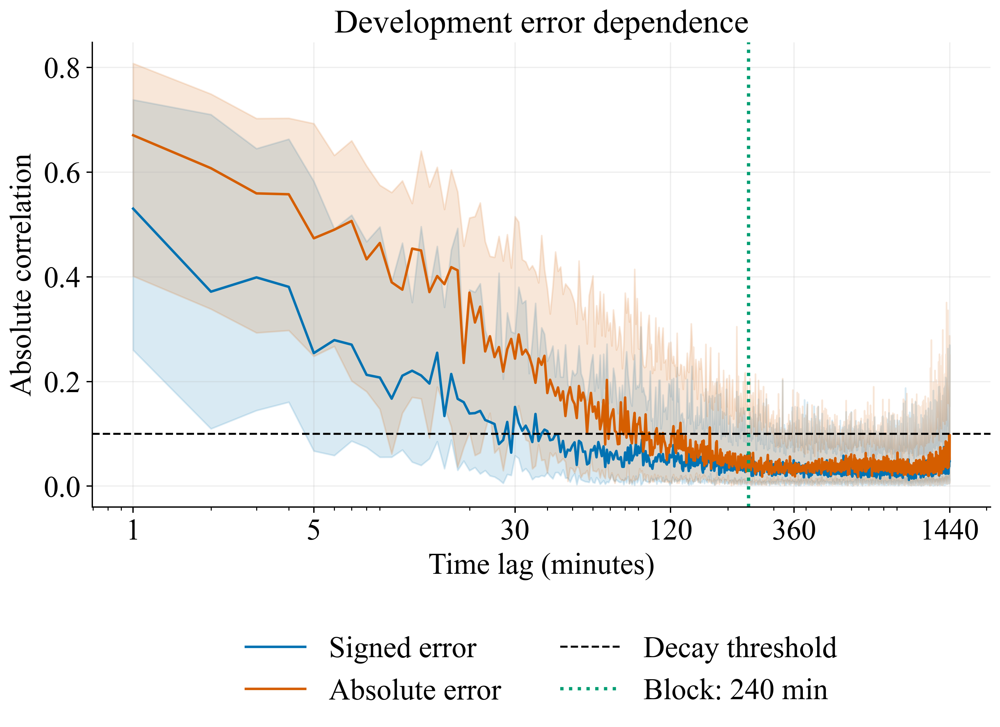

In [6]:
# Isolated presentation renderer; original scientific artifacts remain immutable.
def _presentation_nb03_350b176d():
    # Presentation only: load immutable, previously computed scientific results.
    from pathlib import Path
    import hashlib, json, textwrap
    import numpy as np
    import pandas as pd
    import matplotlib as mpl
    import matplotlib.pyplot as plt
    import matplotlib.dates as mdates
    from matplotlib import font_manager
    from matplotlib.text import Text
    from matplotlib.ticker import FuncFormatter, LogLocator
    from IPython.display import display, Image
    from PIL import Image as PILImage
    ROOT = Path.cwd().resolve()
    if ROOT.name == "Notebooks":
        ROOT = ROOT.parent
    assert ROOT.is_dir()
    INPUT_SHA256 = {'Tables/guldana_n3_20261007_v01/03_baselines/development_error_ACF.parquet': '66ed22997c8ff9df789d5f86686248141f53963af787b4ef41d31e0174d9f713', 'Configs/statistics_protocol.json': '8188b670d11543cf066550b5a751cbf305655bfc1789a9dbce97da31004abcf2'}
    for _relative, _expected in INPUT_SHA256.items():
        assert hashlib.sha256((ROOT / _relative).read_bytes()).hexdigest() == _expected, _relative
    assert Path(font_manager.findfont("Times New Roman", fallback_to_default=False)).is_file()
    mpl.rcParams.update({"font.family": "Times New Roman", "font.size": 18,
        "axes.titlesize": 20, "axes.labelsize": 18, "xtick.labelsize": 18,
        "ytick.labelsize": 18, "legend.fontsize": 18, "figure.dpi": 350,
        "savefig.dpi": 350, "axes.unicode_minus": True, "pdf.fonttype": 42,
        "ps.fonttype": 42, "axes.formatter.use_mathtext": False})
    _PNG = ROOT / "Figures/PNG/guldana_n3_20261011_presentation/NB03"
    _PDF = ROOT / "Figures/PDF/guldana_n3_20261011_presentation/NB03"
    _PNG.mkdir(parents=True, exist_ok=True)
    _PDF.mkdir(parents=True, exist_ok=True)
    def _label(name, width=22):
        name = str(name).replace("HistGradientBoosting", "Histogram boosting").replace("Mask_only_ExtraTrees", "Mask-only ExtraTrees").replace("Autoregressive_Ridge", "Autoregressive Ridge")
        return "\n".join(textwrap.wrap(name, width=width, break_long_words=False, break_on_hyphens=False))
    def _num(value, decimals=2):
        return f"{value:.{decimals}f}".replace("-", "−")
    def _quiet_axes(ax):
        ax.grid(alpha=.20)
        ax.spines[["top", "right"]].set_visible(False)
    def _export(fig, stem):
        fig.canvas.draw()
        for artist in fig.findobj(Text):
            if artist.get_visible() and artist.get_text():
                assert 18 <= artist.get_fontsize() <= 20, (artist.get_text(), artist.get_fontsize())
                assert artist.get_fontfamily() == ["Times New Roman"], artist.get_fontfamily()
        png = _PNG / (stem + ".png")
        pdf = _PDF / (stem + ".pdf")
        fig.savefig(png, dpi=350, bbox_inches="tight", pad_inches=.08)
        fig.savefig(pdf, dpi=350, bbox_inches="tight", pad_inches=.08)
        with PILImage.open(png) as image:
            assert all(abs(d - 350) < .02 for d in image.info["dpi"])
        plt.close(fig)
        display(Image(filename=str(png)))

    acf_frame = pd.read_parquet(ROOT / "Tables/guldana_n3_20261007_v01/03_baselines/development_error_ACF.parquet")
    BLOCK_MINUTES = json.loads((ROOT / "Configs/statistics_protocol.json").read_text())["block_minutes"]
    fig, ax = plt.subplots(figsize=(8.8,6.8))
    for kind,color in [("Signed error","#0072B2"),("Absolute error","#D55E00")]:
        sub = acf_frame.loc[acf_frame.Error.eq(kind)].copy()
        sub["Magnitude"] = sub.Correlation.abs()
        grouped = sub.groupby("Lag").Magnitude
        median, low, high = grouped.median(), grouped.quantile(.1), grouped.quantile(.9)
        ax.plot(median.index,median,color=color,lw=1.5,label=kind)
        ax.fill_between(median.index,low,high,color=color,alpha=.15)
    ax.axhline(.1,color="black",ls="--",lw=1.2,label="Decay threshold")
    ax.axvline(BLOCK_MINUTES,color="#009E73",ls=":",lw=2,label=f"Block: {BLOCK_MINUTES} min")
    ax.set_xscale("log"); ax.set_xticks([1,5,30,120,360,1440],["1","5","30","120","360","1440"])
    ax.set(xlabel="Time lag (minutes)",ylabel="Absolute correlation",title="Development error dependence")
    _quiet_axes(ax)
    ax.legend(loc="upper center",bbox_to_anchor=(.5,-.22),ncol=2,frameon=False)
    fig.tight_layout()
    _export(fig,"22_development_error_dependence")

_presentation_nb03_350b176d()


**Interpretation.** Every inspected signed/absolute error group crosses the prespecified threshold within the inspected day. The computed selection fixes a 240-minute primary block and 120/480-minute sensitivity in the downstream protocol. House 4, fold 1 has a substantially longer absolute-error decay; the quantile rule is not an independence guarantee for every group. Figure 22 displays median correlation magnitude and the 10th–90th percentile spread across groups, not confidence bands.

## 10. Fixed illustrative telemetry outages

Use houses 1, 8 and 10 at the temporal midpoint of their third OOF partition, with no selection by prediction error or load magnitude. Hide aggregate telemetry for a continuous 120-minute interval while preserving naturally available auxiliary measurements. Unlike the independent primary query scenarios, this illustration maintains one consistent missing interval across consecutive queries. Only originally observed reference targets are scored. These illustrative windows are not used to redefine the primary comparison.


In [74]:
# Fixed illustrative outage cases: predefined houses, temporal midpoints, no error-based selection.
case_outputs=[];case_metrics=[]
case_fold=3;case_seed=17
for house in [1,8,10]:
    info=houses[house];mapping=duplicate_maps[case_fold][house];prep=preprocessors[case_fold]
    pool=np.flatnonzero(info["ids"][f"fold_{case_fold}"].eq("outer_validation").to_numpy())
    start=int(pool[len(pool)//2]);stop=start+120;queries=np.arange(start-60,stop+60)
    assert info["ids"].iloc[queries][f"fold_{case_fold}"].eq("outer_validation").all()
    store=prepare_sensor_store(info,mapping,prep.state["target_scale"],case_fold)
    store={**store,"available":store["available"].copy()}
    store["available"][start:stop,store["sensors"].index("P_agg")]=False
    batch=fast_sensor_batch(store,queries,seed=case_seed,aggregate_gap=1,auxiliary_retention=1.,mode="point")
    raw=masked_tabular_rows(house_features(house,case_fold).iloc[queries],batch,mapping).reset_index(drop=True)
    meta=pd.DataFrame({"house":house,"timestamp":info["values"].index[queries],
        "observed_auxiliary_count":batch["current_mask"].sum(axis=1)})
    naive_state=json.loads((MODEL_DIR/f"naive_fold_{case_fold}_seed_{case_seed}.json").read_text())
    naive=predict_naive(naive_state,raw,meta)
    if BEST_BASELINE in CLASSICAL_NAMES:
        bundle=joblib.load(MODEL_DIR/f"{BEST_BASELINE}_fold_{case_fold}_seed_{case_seed}.joblib")
        transformed=prep.transform(raw)[bundle["feature_columns"]].to_numpy()
        estimate=bundle["model"].predict(transformed)
    else:estimate=naive[:,NAIVE_NAMES.index(BEST_BASELINE)]
    truth=info["values"].P_agg.where(info["available"].P_agg).iloc[queries].to_numpy(dtype=np.float64)
    during=(queries>=start)&(queries<stop)
    valid=during & np.isfinite(truth)
    assert valid.any()
    output=meta.copy();output["truth_kW"]=truth;output["best_baseline_kW"]=estimate
    output["last_valid_kW"]=naive[:,1];output["simulated_outage"]=during
    case_outputs.append(output)
    output.to_parquet(PRED_DIR/f"illustrative_outage_house_{house:02d}.parquet",index=False)
    case_metrics.append({"House":house,"Start":str(info["values"].index[start]),"Outage minutes":120,
        "Observed labels within outage":int(valid.sum()),"Best-baseline MAE (kW)":float(np.abs(estimate[valid]-truth[valid]).mean()),
        "Last-valid MAE (kW)":float(np.abs(naive[valid,1]-truth[valid]).mean())})
    del store,batch
table(pd.DataFrame(case_metrics),"illustrative_outage_cases",
    "Table 20. Fixed illustrative 120-minute aggregate outages with naturally available auxiliary sensors; these are not primary-score cohorts.")


House,Start,Outage minutes,Observed labels within outage,Best-baseline MAE (kW),Last-valid MAE (kW)
1,2023-04-20 02:09:00,120,119,0.0776,0.0638
8,2023-07-13 19:40:00,120,114,0.1446,0.1235
10,2023-08-01 19:30:00,120,119,0.0907,0.0302


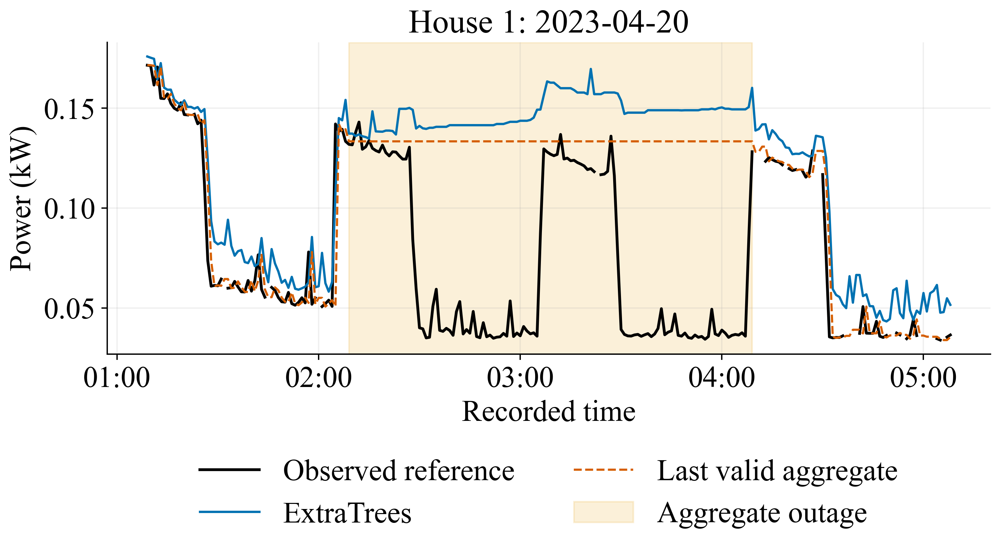

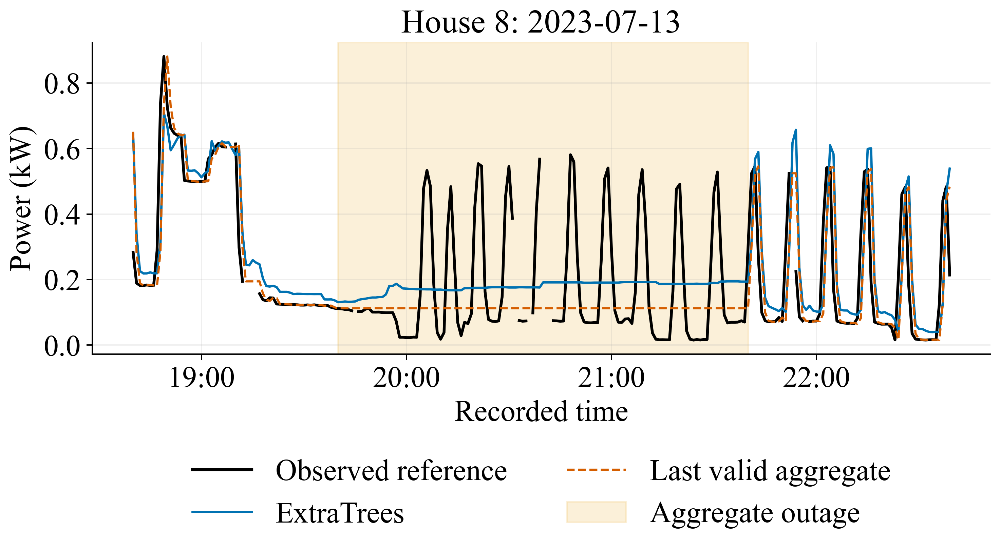

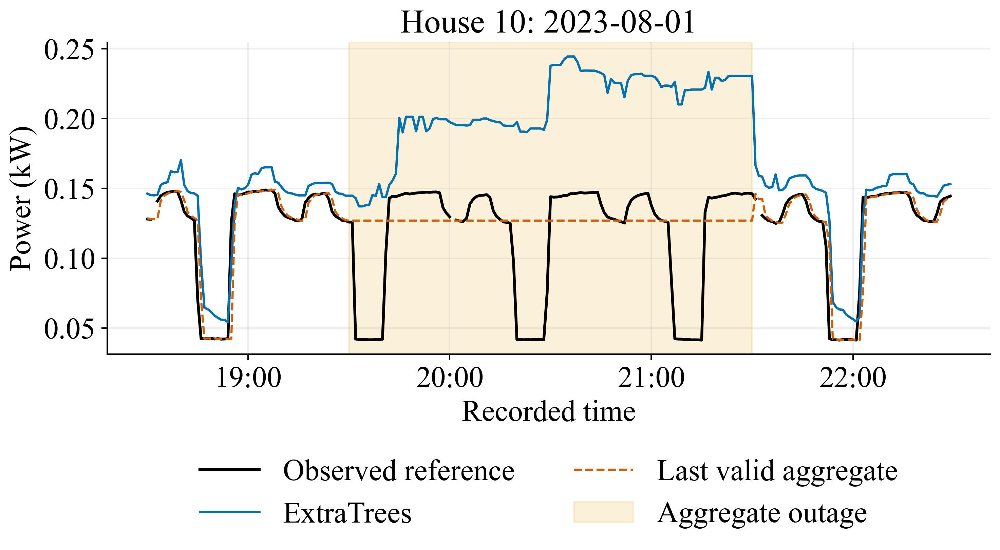

In [9]:
# Re-render archived scientific figures; this cell does not train models or recompute metrics.
def _presentation_nb03_d9dffbe0():
    # Presentation only: load immutable, previously computed scientific results.
    from pathlib import Path
    import hashlib, json, textwrap
    import numpy as np
    import pandas as pd
    import matplotlib as mpl
    import matplotlib.pyplot as plt
    import matplotlib.dates as mdates
    from matplotlib import font_manager
    from matplotlib.text import Text
    from matplotlib.ticker import FuncFormatter, LogLocator
    from IPython.display import display, Image
    from PIL import Image as PILImage
    ROOT = Path.cwd().resolve()
    if ROOT.name == "Notebooks":
        ROOT = ROOT.parent
    assert ROOT.is_dir()
    INPUT_SHA256 = {'Tables/guldana_n3_20261007_v01/03_baselines/all_baseline_primary_OOF.csv': '62d00b7ae86af0423fef8b1a208291d05b750b7da0d38aebf64f9ac82be9c1be', 'Predictions/development/guldana_n3_20261007_v01/illustrative_outage_house_01.parquet': 'd40e94caaef75e841d8ef6a5bcc8a21a4f287e64460393bea54164a8798b5523', 'Predictions/development/guldana_n3_20261007_v01/illustrative_outage_house_08.parquet': '8d71e70149a73510d8ca05e61d0dee28e312feb6ef76612c1602ce2de4bbde39', 'Predictions/development/guldana_n3_20261007_v01/illustrative_outage_house_10.parquet': '1f3a8e38427031d99e642d7ea74c575149f683c3e3f839e9a798a913d46fc5e0'}
    for _relative, _expected in INPUT_SHA256.items():
        assert hashlib.sha256((ROOT / _relative).read_bytes()).hexdigest() == _expected, _relative
    assert Path(font_manager.findfont("Times New Roman", fallback_to_default=False)).is_file()
    mpl.rcParams.update({"font.family": "Times New Roman", "font.size": 18,
        "axes.titlesize": 20, "axes.labelsize": 18, "xtick.labelsize": 18,
        "ytick.labelsize": 18, "legend.fontsize": 18, "figure.dpi": 350,
        "savefig.dpi": 350, "axes.unicode_minus": True, "pdf.fonttype": 42,
        "ps.fonttype": 42, "axes.formatter.use_mathtext": False})
    _PNG = ROOT / "Figures/PNG/guldana_n3_20261011_presentation/NB03"
    _PDF = ROOT / "Figures/PDF/guldana_n3_20261011_presentation/NB03"
    _PNG.mkdir(parents=True, exist_ok=True)
    _PDF.mkdir(parents=True, exist_ok=True)
    def _label(name, width=22):
        name = str(name).replace("HistGradientBoosting", "Histogram boosting").replace("Mask_only_ExtraTrees", "Mask-only ExtraTrees").replace("Autoregressive_Ridge", "Autoregressive Ridge")
        return "\n".join(textwrap.wrap(name, width=width, break_long_words=False, break_on_hyphens=False))
    def _num(value, decimals=2):
        return f"{value:.{decimals}f}".replace("-", "−")
    def _quiet_axes(ax):
        ax.grid(alpha=.20)
        ax.spines[["top", "right"]].set_visible(False)
    def _export(fig, stem):
        fig.canvas.draw()
        for artist in fig.findobj(Text):
            if artist.get_visible() and artist.get_text():
                assert 18 <= artist.get_fontsize() <= 20, (artist.get_text(), artist.get_fontsize())
                assert artist.get_fontfamily() == ["Times New Roman"], artist.get_fontfamily()
        png = _PNG / (stem + ".png")
        pdf = _PDF / (stem + ".pdf")
        fig.savefig(png, dpi=350, bbox_inches="tight", pad_inches=.08)
        fig.savefig(pdf, dpi=350, bbox_inches="tight", pad_inches=.08)
        with PILImage.open(png) as image:
            assert all(abs(d - 350) < .02 for d in image.info["dpi"])
        plt.close(fig)
        display(Image(filename=str(png)))

    BEST_BASELINE = pd.read_csv(ROOT / "Tables/guldana_n3_20261007_v01/03_baselines/all_baseline_primary_OOF.csv").iloc[0].Model
    for house in [1,8,10]:
        frame = pd.read_parquet(ROOT / f"Predictions/development/guldana_n3_20261007_v01/illustrative_outage_house_{house:02d}.parquet")
        assert frame.house.eq(house).all()
        fig, ax = plt.subplots(figsize=(8.8,5.4))
        ax.plot(frame.timestamp,frame.truth_kW,color="black",lw=1.7,label="Observed reference")
        ax.plot(frame.timestamp,frame.best_baseline_kW,color="#0072B2",lw=1.4,label=_label(BEST_BASELINE))
        ax.plot(frame.timestamp,frame.last_valid_kW,color="#D55E00",ls="--",lw=1.3,label="Last valid aggregate")
        event=frame.loc[frame.simulated_outage,"timestamp"]
        ax.axvspan(event.min(),event.max()+pd.Timedelta(minutes=1),color="#E69F00",alpha=.15,label="Aggregate outage")
        ax.set(title=f"House {house}: {frame.timestamp.iloc[0].date()}",ylabel="Power (kW)",xlabel="Recorded time")
        ax.xaxis.set_major_locator(mdates.HourLocator(interval=1))
        ax.xaxis.set_major_formatter(mdates.DateFormatter("%H:%M"))
        _quiet_axes(ax)
        ax.legend(loc="upper center",bbox_to_anchor=(.5,-.25),ncol=2,frameon=False)
        fig.tight_layout()
        _export(fig,f"23_illustrative_aggregate_outage_house_{house:02d}")

_presentation_nb03_d9dffbe0()


**Interpretation of the fixed episodes.** Last-valid MAE is lower than ExtraTrees in every predefined illustrative outage; the full paired values are calculated in the preceding episode table. The plots retain these unfavorable examples. Neither method recovers all hidden appliance cycles. These three midpoint windows do not overturn the full OOF comparison, but they demonstrate that its average gain is not an episode-level guarantee.

## 11. Secondary accuracy and fitted-state complexity

All quantities below use the saved OOF predictions. Normalized MAE divides each absolute error by the population standard deviation of that house's 6,553 training labels in the corresponding fold, then averages within house and across houses. The scale never uses OOF labels. R² is reported both pooled and averaged over the ten house-specific values (three periods pooled within house). Median and tail absolute errors are pooled; maximum error and worst-house MAE are first calculated for each seed, then averaged. Equal cohort sizes make pooled MAE equal the primary house-macro MAE. These are secondary diagnostics; none changes the primary ranking or retunes a model.

In [75]:
# Complete the prespecified secondary metrics using training-only target scales.
from sklearn.metrics import r2_score
scale_rows=[]
for fold in [1,2,3]:
    metadata=pd.read_parquet(CACHE/f"fold_{fold}_seed_17.parquet")
    for house,part in metadata.loc[metadata.role.eq("train")].groupby("house"):
        scale=float(part.y_kW.std(ddof=0));assert scale>0
        scale_rows.append({"fold":fold,"house":house,"Training target SD (kW)":scale,"Training n":len(part)})
training_scales=pd.DataFrame(scale_rows)
table(training_scales,"secondary_metric_training_scales",
      "Table 21. Target standard deviations fitted only on the common training cohort in each house and fold.")
scaled_oof=oof_all.merge(training_scales[["fold","house","Training target SD (kW)"]],on=["fold","house"],validate="many_to_one")
secondary_rows=[];normalized_house_rows=[]
for name in ALL_BASELINES:
    for seed,part in scaled_oof.groupby("seed"):
        truth=part.y_kW.to_numpy();prediction=part[name].to_numpy()
        error=prediction-truth;absolute=np.abs(error)
        temporary=part[["house"]].copy()
        temporary["AE"]=absolute
        temporary["Normalized AE"]=absolute/part["Training target SD (kW)"].to_numpy()
        grouped=temporary.groupby("house").mean()
        r2_by_house=[r2_score(g.y_kW,g[name],force_finite=False) for _,g in part.groupby("house")]
        assert np.isfinite(r2_by_house).all()
        secondary_rows.append({"Model":name,"Seed":seed,"Pooled MAE (kW)":float(absolute.mean()),
            "Pooled RMSE (kW)":float(np.sqrt(np.mean(error**2))),"Median AE (kW)":float(np.median(absolute)),
            "House-macro normalized MAE":float(grouped["Normalized AE"].mean()),
            "Pooled R2":float(r2_score(truth,prediction,force_finite=False)),
            "House-macro R2":float(np.mean(r2_by_house)),
            "Q90 AE (kW)":float(np.quantile(absolute,.9)),"Q95 AE (kW)":float(np.quantile(absolute,.95)),
            "Q99 AE (kW)":float(np.quantile(absolute,.99)),"Maximum AE (kW)":float(absolute.max()),
            "Worst-house MAE (kW)":float(grouped.AE.max()),"Worst house":int(grouped.AE.idxmax())})
        for house,row in grouped.iterrows():
            normalized_house_rows.append({"Model":name,"Seed":seed,"House":house,
                "Normalized MAE":float(row["Normalized AE"])})
secondary_metrics=pd.DataFrame(secondary_rows)
secondary_metrics.to_csv(TABLES/"secondary_metrics_by_seed.csv",index=False)
secondary_summary=secondary_metrics.drop(columns=["Seed","Worst house"]).groupby("Model",sort=False).mean().reindex(order).reset_index()
table(secondary_summary[["Model","Pooled MAE (kW)","Pooled RMSE (kW)","Median AE (kW)",
    "House-macro normalized MAE","Pooled R2","House-macro R2"]],"secondary_central_metrics",
    "Table 22. Secondary accuracy metrics, computed separately per seed and then averaged; normalization uses training-only house/fold SD.")
table(secondary_summary[["Model","Q90 AE (kW)","Q95 AE (kW)","Q99 AE (kW)","Maximum AE (kW)","Worst-house MAE (kW)"]],
    "secondary_tail_metrics","Table 23. Error tails and worst-house MAE; columns are averages of the three seed-specific statistics.")
normalized_house=pd.DataFrame(normalized_house_rows).groupby(["Model","House"])["Normalized MAE"].mean().unstack().reindex(order)
table(normalized_house.reset_index(),"normalized_error_by_house",
    "Table 24. Dimensionless house-specific MAE divided by each fold's training target SD, averaged over seeds.")
# Exactly balanced house and fold sizes make pooled MAE equal the primary house-macro MAE.
np.testing.assert_allclose(secondary_summary.set_index("Model")["Pooled MAE (kW)"],
    summary.set_index("Model").loc[order,"MAE_mean"],rtol=0,atol=1e-12)


fold,house,Training target SD (kW),Training n
1,1,0.6345,6553
1,2,0.3740,6553
1,3,0.5338,6553
1,4,0.5991,6553
1,5,0.8847,6553
1,6,0.7074,6553
1,7,0.7126,6553
1,8,0.4325,6553
1,9,0.7609,6553
1,10,0.5596,6553


Model,Pooled MAE (kW),Pooled RMSE (kW),Median AE (kW),House-macro normalized MAE,Pooled R2,House-macro R2
ExtraTrees,0.1158,0.3542,0.0242,0.1799,0.7892,0.7752
CatBoost,0.1244,0.3570,0.0318,0.1930,0.7859,0.7718
HistGradientBoosting,0.1252,0.3622,0.0310,0.1946,0.7796,0.7649
Huber,0.1419,0.4494,0.0196,0.2203,0.6606,0.6500
Last valid aggregate,0.1518,0.5768,0.0062,0.2329,0.4410,0.4264
Ridge,0.1846,0.4215,0.0790,0.2860,0.7015,0.6874
Autoregressive_Ridge,0.1849,0.4852,0.0654,0.2878,0.6044,0.5942
Partial sum + residual,0.2126,0.6547,0.0387,0.3378,0.2799,0.2432
Partial appliance sum,0.2629,0.6871,0.0759,0.4158,0.2070,0.1598
Median,0.2779,0.8035,0.0455,0.4395,−0.0847,−0.1045


Model,Q90 AE (kW),Q95 AE (kW),Q99 AE (kW),Maximum AE (kW),Worst-house MAE (kW)
ExtraTrees,0.2105,0.4797,1.8678,9.1646,0.2621
CatBoost,0.2430,0.5161,1.8608,9.1273,0.2735
HistGradientBoosting,0.2580,0.5324,1.8912,9.1049,0.2737
Huber,0.3172,0.8005,2.3187,9.3497,0.3128
Last valid aggregate,0.1676,0.8463,3.3164,9.2724,0.3496
Ridge,0.3767,0.8186,2.0266,9.1096,0.3575
Autoregressive_Ridge,0.3218,0.7850,2.5570,9.1087,0.3571
Partial sum + residual,0.3891,1.3071,3.3755,9.5852,0.4030
Partial appliance sum,0.4840,1.3806,3.4864,9.6798,0.4881
Median,0.6333,1.9243,3.8872,9.6220,0.5050


Model,1,2,3,4,5
ExtraTrees,0.1136,0.3011,0.1501,0.1495,0.2792
CatBoost,0.1388,0.3172,0.1608,0.1519,0.2912
HistGradientBoosting,0.1466,0.3239,0.1622,0.1548,0.2913
Huber,0.1678,0.3659,0.2134,0.1893,0.3330
Last valid aggregate,0.1719,0.3865,0.2375,0.2122,0.3720
Ridge,0.2833,0.4795,0.2930,0.2379,0.3807
Autoregressive_Ridge,0.2456,0.4906,0.3054,0.2419,0.3798
Partial sum + residual,0.2090,0.5795,0.3209,0.3039,0.4290
Partial appliance sum,0.2453,0.6473,0.3966,0.4012,0.5187
Median,0.3760,0.7261,0.4656,0.4275,0.5371


**Counting convention.** A tree does not have the same notion of a trainable parameter as a neural network. We therefore retain exact family-specific fitted scalar counts, tree/node/leaf counts, and serialized bytes separately. Linear counts include coefficients and intercept (plus Huber residual scale), with the additional StandardScaler mean/scale listed separately. ExtraTrees counts one threshold per internal node and one value per leaf. Histogram boosting adds its baseline intercept. CatBoost counts leaf values, unique retained numerical borders, scale and bias. Discrete routing structure and training diagnostics are excluded; these numbers must not be interpreted as equivalent neural parameter budgets. Naive counts include the fallbacks actually required by each rule. All methods also share the separately saved fold preprocessing state.

In [76]:
# Count fitted numerical state and structural complexity from every saved checkpoint.
complexity_rows=[]
for family in CLASSICAL_NAMES:
    for fold in [1,2,3]:
        for seed in [17,43,101]:
            stem=f"{family}_fold_{fold}_seed_{seed}"
            saved=joblib.load(MODEL_DIR/f"{stem}.joblib");model=saved["model"]
            trees=0;nodes=0;leaves=0;preprocessing_scalars=0
            if family in {"Ridge","Autoregressive_Ridge","Huber"}:
                estimator=model.steps[-1][1];scaler=model.steps[0][1]
                count=int(estimator.coef_.size+np.size(estimator.intercept_)+(family=="Huber"))
                preprocessing_scalars=int(scaler.mean_.size+scaler.scale_.size)
                definition="coefficients + intercept + Huber residual scale when present; scaler mean/scale counted separately"
            elif "ExtraTrees" in family:
                trees=len(model.estimators_)
                nodes=sum(t.tree_.node_count for t in model.estimators_)
                leaves=sum(int((t.tree_.children_left<0).sum()) for t in model.estimators_)
                count=nodes
                definition="one threshold per internal node + one scalar prediction per leaf; discrete feature/routing topology excluded"
            elif family=="HistGradientBoosting":
                all_trees=[t for iteration in model._predictors for t in iteration]
                trees=len(all_trees);nodes=sum(len(t.nodes) for t in all_trees)
                leaves=sum(int(t.nodes["is_leaf"].sum()) for t in all_trees)
                count=nodes+int(np.size(model._baseline_prediction))
                definition="one numerical split threshold per internal node + one leaf value + baseline intercept; bin mapper/topology excluded"
            elif family=="CatBoost":
                leaf_counts=np.asarray(model.get_tree_leaf_counts())
                trees=len(leaf_counts);leaves=int(leaf_counts.sum());nodes=int(2*leaves-trees)
                count=int(len(model.get_leaf_values())+sum(len(v) for v in model.get_borders().values())+2)
                definition="leaf values + unique retained numerical borders + scale/bias; discrete symmetric-tree splits excluded"
            record={"Model":family,"Fold":fold,"Seed":seed,"Fitted scalar count":count,
                "Additional scaler scalars":preprocessing_scalars,"Trees":trees,"Logical nodes":nodes,"Leaves":leaves}
            complexity_rows.append(record)
            (MODEL_DIR/f"{stem}_complexity.json").write_text(json.dumps({**record,"definition":definition,
                "comparable_to_neural_trainable_parameters":False},indent=2)+"\n")
            del saved,model
complexity_frame=pd.DataFrame(complexity_rows)
for family in CLASSICAL_NAMES:
    table(complexity_frame.loc[complexity_frame.Model.eq(family)],f"complexity_{family}",
        f"Table 25.{family}. Exact fitted-state counts in every saved checkpoint; definitions differ by family.")
naive_complexity=[]
for fold in [1,2,3]:
    for seed in [17,43,101]:
        state=json.loads((MODEL_DIR/f"naive_fold_{fold}_seed_{seed}.json").read_text())
        median=1+len(state["house_medians"])
        counts=[median,median,median+len(state["seasonal"])+len(state["global_seasonal"]),
                median,median,0,1+len(state["residual_house"])+len(state["residual_house_count"])]
        for name,count in zip(NAIVE_NAMES,counts):
            naive_complexity.append({"Model":name,"Fold":fold,"Seed":seed,"Fitted scalar count":count})
table(pd.DataFrame(naive_complexity).groupby("Model",sort=False)["Fitted scalar count"].agg(["min","max"]).reset_index(),
      "naive_fitted_state_counts","Table 26. Scalar summary counts required by each naive control, including its fallback statistics.",precision=0)


Model,Fold,Seed,Fitted scalar count,Additional scaler scalars,Trees,Logical nodes,Leaves
Ridge,1,17,181,360,0,0,0
Ridge,1,43,181,360,0,0,0
Ridge,1,101,181,360,0,0,0
Ridge,2,17,181,360,0,0,0
Ridge,2,43,181,360,0,0,0
Ridge,2,101,181,360,0,0,0
Ridge,3,17,181,360,0,0,0
Ridge,3,43,181,360,0,0,0
Ridge,3,101,181,360,0,0,0


Model,Fold,Seed,Fitted scalar count,Additional scaler scalars,Trees,Logical nodes,Leaves
Huber,1,17,182,360,0,0,0
Huber,1,43,182,360,0,0,0
Huber,1,101,182,360,0,0,0
Huber,2,17,182,360,0,0,0
Huber,2,43,182,360,0,0,0
Huber,2,101,182,360,0,0,0
Huber,3,17,182,360,0,0,0
Huber,3,43,182,360,0,0,0
Huber,3,101,182,360,0,0,0


Model,Fold,Seed,Fitted scalar count,Additional scaler scalars,Trees,Logical nodes,Leaves
Autoregressive_Ridge,1,17,68,134,0,0,0
Autoregressive_Ridge,1,43,68,134,0,0,0
Autoregressive_Ridge,1,101,68,134,0,0,0
Autoregressive_Ridge,2,17,68,134,0,0,0
Autoregressive_Ridge,2,43,68,134,0,0,0
Autoregressive_Ridge,2,101,68,134,0,0,0
Autoregressive_Ridge,3,17,68,134,0,0,0
Autoregressive_Ridge,3,43,68,134,0,0,0
Autoregressive_Ridge,3,101,68,134,0,0,0


Model,Fold,Seed,Fitted scalar count,Additional scaler scalars,Trees,Logical nodes,Leaves
ExtraTrees,1,17,281348,0,128,281348,140738
ExtraTrees,1,43,284402,0,128,284402,142265
ExtraTrees,1,101,295646,0,128,295646,147887
ExtraTrees,2,17,280810,0,128,280810,140469
ExtraTrees,2,43,284938,0,128,284938,142533
ExtraTrees,2,101,285522,0,128,285522,142825
ExtraTrees,3,17,287790,0,128,287790,143959
ExtraTrees,3,43,294990,0,128,294990,147559
ExtraTrees,3,101,294224,0,128,294224,147176


Model,Fold,Seed,Fitted scalar count,Additional scaler scalars,Trees,Logical nodes,Leaves
HistGradientBoosting,1,17,4351,0,150,4350,2250
HistGradientBoosting,1,43,4351,0,150,4350,2250
HistGradientBoosting,1,101,4351,0,150,4350,2250
HistGradientBoosting,2,17,4351,0,150,4350,2250
HistGradientBoosting,2,43,4351,0,150,4350,2250
HistGradientBoosting,2,101,3626,0,125,3625,1875
HistGradientBoosting,3,17,12201,0,200,12200,6200
HistGradientBoosting,3,43,10676,0,175,10675,5425
HistGradientBoosting,3,101,9151,0,150,9150,4650


Model,Fold,Seed,Fitted scalar count,Additional scaler scalars,Trees,Logical nodes,Leaves
CatBoost,1,17,22922,0,341,43307,21824
CatBoost,1,43,25699,0,383,48641,24512
CatBoost,1,101,25896,0,386,49022,24704
CatBoost,2,17,26799,0,400,50800,25600
CatBoost,2,43,25568,0,382,48514,24448
CatBoost,2,101,25643,0,384,48512,24448
CatBoost,3,17,16925,0,251,31877,16064
CatBoost,3,43,19658,0,292,37084,18688
CatBoost,3,101,20495,0,305,38735,19520


Model,Fold,Seed,Fitted scalar count,Additional scaler scalars,Trees,Logical nodes,Leaves
Mask_only_ExtraTrees,1,17,410276,0,128,410276,205202
Mask_only_ExtraTrees,1,43,393622,0,128,393622,196875
Mask_only_ExtraTrees,1,101,395884,0,128,395884,198006
Mask_only_ExtraTrees,2,17,476322,0,128,476322,238225
Mask_only_ExtraTrees,2,43,463672,0,128,463672,231900
Mask_only_ExtraTrees,2,101,472148,0,128,472148,236138
Mask_only_ExtraTrees,3,17,665974,0,128,665974,333051
Mask_only_ExtraTrees,3,43,668252,0,128,668252,334190
Mask_only_ExtraTrees,3,101,667724,0,128,667724,333926


Model,min,max
Median,11,11
Last valid aggregate,11,11
Seasonal median,1859,1859
Previous day,11,11
Previous week,11,11
Partial appliance sum,0,0
Partial sum + residual,64,66


## 12. Representative measured memory and prediction latency

The training records contain elapsed time and checkpoint size, but not each fit's peak RSS. The following resource-only repeats use the already selected fold-1 parameters, seed 17, the same 65,530 training labels and the same inner cohort. They do not overwrite trained comparison checkpoints, predictions, or selections, and are excluded from hyperparameter-search accounting.

A 20 ms sampler measures the live notebook process after input arrays are allocated. Baseline RSS, sampled peak RSS and their nonnegative difference describe this shared process, including loaded datasets and allocator reuse; they are not isolated model RAM or exact hardware peaks. Each family's fit includes the same inner-diagnostic work as its original training routine. Prediction timings exclude preprocessing, use 5 warmups and 30 measured calls, and report batch sizes 1 and 32. ExtraTrees inference uses one thread for deterministic reduction; CatBoost and BLAS explicitly use four. Earlier bulk CatBoost inference did not explicitly limit its prediction threads, so these new timings provide the thread-controlled latency comparison.

In [77]:
# Profile representative full-cohort refits without replacing any OOF model or prediction.
import gc, threading, psutil
PROFILE_DIR=MODEL_DIR/"resource_profiles";PROFILE_DIR.mkdir(exist_ok=True)
profile_x,profile_raw,profile_meta,profile_columns=load_modeling_inputs(1,17)
profile_train=profile_meta.role.eq("train").to_numpy()
profile_inner=profile_meta.role.eq("inner_validation").to_numpy()
profile_inner_meta=profile_meta.loc[profile_inner].reset_index(drop=True)
profile_y=profile_meta.loc[profile_train,"y_kW"].to_numpy(dtype=np.float64)
profile_rows=[]
def profile_classical_resources(family):
    selected=family_columns(family,profile_columns)
    train_x=profile_x[profile_train][:,selected];inner_x=profile_x[profile_inner][:,selected]
    params=json.loads((MODEL_DIR/f"selection_fold_1_{family}.json").read_text())["parameters"]
    protected=MODEL_DIR/f"{family}_fold_1_seed_17.joblib"
    protected_hash=hashlib.sha256(protected.read_bytes()).hexdigest()
    gc.collect();process=psutil.Process();samples=[];stop=threading.Event()
    start=time.perf_counter();baseline=process.memory_info().rss
    def sample_memory():
        while not stop.is_set():
            samples.append((time.perf_counter()-start,process.memory_info().rss))
            stop.wait(.02)
    sampler=threading.Thread(target=sample_memory,daemon=True);sampler.start()
    try:
        model,history,record=fit_classical(family,params,17,train_x,profile_y,inner_x,profile_inner_meta,
            compute_protocol["final_training_seconds"])
    finally:
        samples.append((time.perf_counter()-start,process.memory_info().rss));stop.set();sampler.join()
    trace=pd.DataFrame(samples,columns=["Seconds","Process RSS bytes"])
    trace.to_csv(PROFILE_DIR/f"{family}_fold_1_seed_17_RSS.csv",index=False)
    history.to_csv(PROFILE_DIR/f"{family}_refit_history.csv",index=False)
    if isinstance(model,ExtraTreesRegressor):model.set_params(n_jobs=1)
    def predict(batch):
        return model.predict(batch,thread_count=4) if family=="CatBoost" else model.predict(batch)
    latencies={}
    with threadpool_limits(limits=4):
        for size in [1,32]:
            batch=inner_x[:size]
            for _ in range(5):predict(batch)
            timed=[]
            for _ in range(30):
                tick=time.perf_counter();predict(batch);timed.append(time.perf_counter()-tick)
            latencies[f"Batch {size} median ms"]=float(np.median(timed)*1000)
    peak=max([baseline,*trace["Process RSS bytes"]])
    output={"Model":family,"Fold":1,"Seed":17,"Training targets":len(profile_y),
        "Resource refit seconds":record["fit_seconds"],"Baseline process GiB":baseline/2**30,
        "Sampled peak process GiB":peak/2**30,"Sampled RSS increment MiB":(peak-baseline)/2**20,
        **latencies,"Status":record["status"]}
    assert hashlib.sha256(protected.read_bytes()).hexdigest()==protected_hash
    details={**output,"sampling_interval_seconds":.02,"RSS_scope":"shared live notebook kernel; inputs allocated before baseline",
        "historical_original_training_peak":False,"refit_only_for_resource_measurement":True,
        "prediction_threads":"ExtraTrees one; CatBoost and BLAS four; no preprocessing in latency",
        "hardware":platform.platform(),"fit_diagnostics":record}
    (PROFILE_DIR/f"{family}_fold_1_seed_17.json").write_text(json.dumps(details,indent=2,allow_nan=False)+"\n")
    profile_rows.append(output)
    table(pd.DataFrame([output]),f"resource_profile_{family}",
        f"Table 27.{family}. Observed resource-only refit on fold 1, seed 17; sampled RSS is the whole notebook process.")
    del model,train_x,inner_x;gc.collect()
    return output


In [78]:
# Measure actual representative resources: Ridge.
profile_Ridge=profile_classical_resources("Ridge")

In [79]:
# Measure actual representative resources: Huber.
profile_Huber=profile_classical_resources("Huber")

In [80]:
# Measure actual representative resources: Autoregressive_Ridge.
profile_Autoregressive_Ridge=profile_classical_resources("Autoregressive_Ridge")

In [81]:
# Measure actual representative resources: ExtraTrees.
profile_ExtraTrees=profile_classical_resources("ExtraTrees")

In [82]:
# Measure actual representative resources: HistGradientBoosting.
profile_HistGradientBoosting=profile_classical_resources("HistGradientBoosting")

In [83]:
# Measure actual representative resources: CatBoost.
profile_CatBoost=profile_classical_resources("CatBoost")

In [84]:
# Measure actual representative resources: Mask_only_ExtraTrees.
profile_Mask_only_ExtraTrees=profile_classical_resources("Mask_only_ExtraTrees")

**Interpretation of secondary accuracy.** ExtraTrees has the lowest average MAE and pooled RMSE in this development comparison. Last-valid reconstruction has a smaller median absolute error but a much heavier upper-tail error. Normalized error is highest in House 2 for ExtraTrees, while absolute error is highest in House 5. The preceding computed tables retain every metric. Thus neither one metric nor one house provides a complete account of difficulty.

**Resource interpretation.** Resource-only repeats completed for all seven fitted families. The mask-only model has a very small sampled RSS increment because the shared process can reuse already allocated memory; that increment is not the model's RAM requirement. The plot therefore displays the sampled whole-process peak, while the tables retain baseline and increment. CatBoost's small checkpoint and faster single-query inference provide a useful accuracy/cost trade-off to examine alongside ExtraTrees. Hardware, process state, threading and preprocessing exclusions limit portability of these timings.

In [86]:
# Complete per-seed secondary reporting and summarize actual resource profiles.
for seed in [17,43,101]:
    part=secondary_metrics.loc[secondary_metrics.Seed.eq(seed)].set_index("Model").loc[order].reset_index()
    table(part[["Model","Seed","Pooled MAE (kW)","Pooled RMSE (kW)","Median AE (kW)",
        "House-macro normalized MAE","Pooled R2","House-macro R2"]],f"secondary_central_seed_{seed}",
        f"Table 28.{seed}. Complete secondary central metrics for seed {seed}.")
    table(part[["Model","Seed","Q90 AE (kW)","Q95 AE (kW)","Q99 AE (kW)","Maximum AE (kW)",
        "Worst-house MAE (kW)","Worst house"]],f"secondary_tail_seed_{seed}",
        f"Table 29.{seed}. Complete secondary tail metrics for seed {seed}.")
profiles=pd.DataFrame(profile_rows)
assert len(profiles)==7 and profiles.Status.eq("completed").all()
table(profiles,"representative_resource_profiles","Table 30. All representative resource-only refits; process RSS includes shared notebook state.")


Model,Seed,Pooled MAE (kW),Pooled RMSE (kW),Median AE (kW),House-macro normalized MAE,Pooled R2,House-macro R2
ExtraTrees,17,0.1165,0.3545,0.0250,0.1808,0.7889,0.7748
CatBoost,17,0.1247,0.3567,0.0319,0.1934,0.7862,0.7717
HistGradientBoosting,17,0.1260,0.3623,0.0309,0.1959,0.7795,0.7645
Huber,17,0.1423,0.4505,0.0194,0.2210,0.6590,0.6481
Last valid aggregate,17,0.1530,0.5805,0.0062,0.2350,0.4339,0.4213
Ridge,17,0.1853,0.4214,0.0799,0.2871,0.7016,0.6876
Autoregressive_Ridge,17,0.1864,0.4889,0.0660,0.2901,0.5984,0.5878
Partial sum + residual,17,0.2131,0.6566,0.0387,0.3385,0.2757,0.2383
Partial appliance sum,17,0.2634,0.6889,0.0757,0.4165,0.2027,0.1546
Median,17,0.2779,0.8035,0.0455,0.4395,−0.0847,−0.1045


Model,Seed,Q90 AE (kW),Q95 AE (kW),Q99 AE (kW),Maximum AE (kW),Worst-house MAE (kW),Worst house
ExtraTrees,17,0.2132,0.4803,1.8718,9.2406,0.2653,5
CatBoost,17,0.2445,0.5160,1.8651,9.2409,0.2759,5
HistGradientBoosting,17,0.2636,0.5419,1.9091,9.2049,0.2775,5
Huber,17,0.3237,0.8025,2.3244,9.3482,0.3128,5
Last valid aggregate,17,0.1682,0.8632,3.3300,9.2724,0.3511,5
Ridge,17,0.3798,0.8194,2.0194,9.1128,0.3583,5
Autoregressive_Ridge,17,0.3237,0.7903,2.5883,9.0980,0.3576,5
Partial sum + residual,17,0.3882,1.3172,3.3775,9.5553,0.4054,5
Partial appliance sum,17,0.4837,1.3940,3.4893,9.6465,0.4901,5
Median,17,0.6333,1.9243,3.8872,9.6220,0.5050,5


Model,Seed,Pooled MAE (kW),Pooled RMSE (kW),Median AE (kW),House-macro normalized MAE,Pooled R2,House-macro R2
ExtraTrees,43,0.1160,0.3546,0.0238,0.1808,0.7887,0.7733
CatBoost,43,0.1247,0.3571,0.0316,0.1936,0.7858,0.7699
HistGradientBoosting,43,0.1255,0.3616,0.0310,0.1951,0.7803,0.7637
Huber,43,0.1423,0.4514,0.0202,0.2213,0.6577,0.6444
Last valid aggregate,43,0.1525,0.5782,0.0062,0.2344,0.4384,0.4215
Ridge,43,0.1839,0.4228,0.0780,0.2854,0.6997,0.6836
Autoregressive_Ridge,43,0.1853,0.4877,0.0653,0.2889,0.6004,0.5888
Partial sum + residual,43,0.2121,0.6519,0.0389,0.3372,0.2860,0.2486
Partial appliance sum,43,0.2623,0.6843,0.0759,0.4150,0.2133,0.1654
Median,43,0.2779,0.8035,0.0455,0.4395,−0.0847,−0.1045


Model,Seed,Q90 AE (kW),Q95 AE (kW),Q99 AE (kW),Maximum AE (kW),Worst-house MAE (kW),Worst house
ExtraTrees,43,0.2104,0.4799,1.8768,9.1357,0.2616,5
CatBoost,43,0.2450,0.5187,1.8653,9.1471,0.2748,5
HistGradientBoosting,43,0.2598,0.5318,1.8787,9.1212,0.2757,5
Huber,43,0.3135,0.7968,2.3164,9.3541,0.3129,5
Last valid aggregate,43,0.1699,0.8455,3.3185,9.2724,0.3517,5
Ridge,43,0.3766,0.8146,2.0310,9.1409,0.3572,5
Autoregressive_Ridge,43,0.3230,0.7882,2.5856,9.1369,0.3595,5
Partial sum + residual,43,0.3921,1.3001,3.3652,9.5533,0.4015,5
Partial appliance sum,43,0.4860,1.3664,3.4806,9.6465,0.4866,5
Median,43,0.6333,1.9243,3.8872,9.6220,0.5050,5


Model,Seed,Pooled MAE (kW),Pooled RMSE (kW),Median AE (kW),House-macro normalized MAE,Pooled R2,House-macro R2
ExtraTrees,101,0.1150,0.3535,0.0237,0.1782,0.7900,0.7776
CatBoost,101,0.1240,0.3573,0.0318,0.1921,0.7856,0.7739
HistGradientBoosting,101,0.1241,0.3626,0.0312,0.1927,0.7791,0.7666
Huber,101,0.1411,0.4464,0.0192,0.2184,0.6652,0.6573
Last valid aggregate,101,0.1499,0.5719,0.0061,0.2293,0.4506,0.4363
Ridge,101,0.1845,0.4203,0.0790,0.2854,0.7033,0.6911
Autoregressive_Ridge,101,0.1830,0.4791,0.0649,0.2843,0.6144,0.6060
Partial sum + residual,101,0.2126,0.6556,0.0385,0.3376,0.2779,0.2427
Partial appliance sum,101,0.2630,0.6880,0.0760,0.4158,0.2049,0.1593
Median,101,0.2779,0.8035,0.0455,0.4395,−0.0847,−0.1045


Model,Seed,Q90 AE (kW),Q95 AE (kW),Q99 AE (kW),Maximum AE (kW),Worst-house MAE (kW),Worst house
ExtraTrees,101,0.2080,0.4788,1.8548,9.1176,0.2594,5
CatBoost,101,0.2396,0.5135,1.8521,8.9940,0.2698,5
HistGradientBoosting,101,0.2506,0.5235,1.8856,8.9887,0.2678,5
Huber,101,0.3145,0.8020,2.3154,9.3467,0.3127,5
Last valid aggregate,101,0.1648,0.8301,3.3009,9.2724,0.3459,5
Ridge,101,0.3736,0.8218,2.0295,9.0751,0.3571,5
Autoregressive_Ridge,101,0.3186,0.7766,2.4970,9.0912,0.3541,5
Partial sum + residual,101,0.3869,1.3041,3.3836,9.6472,0.4022,5
Partial appliance sum,101,0.4824,1.3813,3.4893,9.7462,0.4877,5
Median,101,0.6333,1.9243,3.8872,9.6220,0.5050,5


Model,Fold,Seed,Training targets,Resource refit seconds,Batch 1 median ms,Batch 32 median ms
Ridge,1,17,65530,0.2416,0.0744,0.0908
Huber,1,17,65530,39.3319,0.0753,0.0915
Autoregressive_Ridge,1,17,65530,0.0932,0.0743,0.0752
ExtraTrees,1,17,65530,22.0591,4.4693,4.7548
HistGradientBoosting,1,17,65530,4.7395,1.0413,1.4743
CatBoost,1,17,65530,4.9770,0.2846,0.3117
Mask_only_ExtraTrees,1,17,65530,6.3538,4.4372,4.7357
Model,Fold,Seed,Baseline process GiB,Sampled peak process GiB,Sampled RSS increment MiB,Status
Ridge,1,17,0.7079,0.9294,226.7656,completed
Huber,1,17,0.7280,1.1293,410.9688,completed


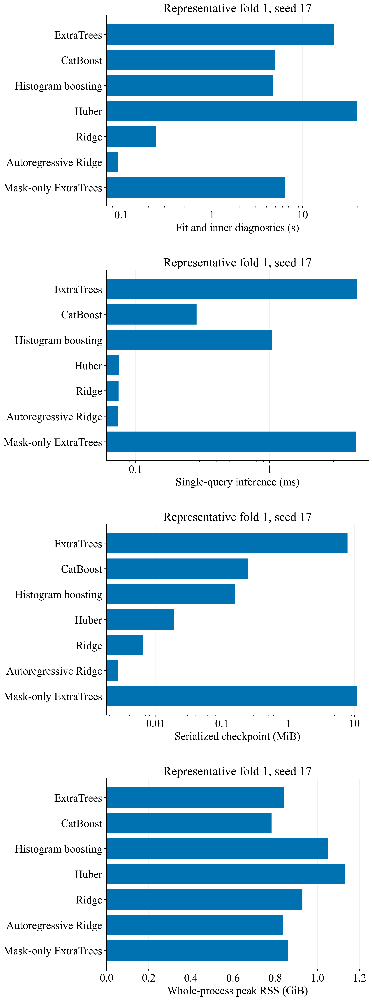

In [10]:
# Re-render archived scientific figures; this cell does not train models or recompute metrics.
def _presentation_nb03_bcec793c():
    # Presentation only: load immutable, previously computed scientific results.
    from pathlib import Path
    import hashlib, json, textwrap
    import numpy as np
    import pandas as pd
    import matplotlib as mpl
    import matplotlib.pyplot as plt
    import matplotlib.dates as mdates
    from matplotlib import font_manager
    from matplotlib.text import Text
    from matplotlib.ticker import FuncFormatter, LogLocator, NullFormatter
    from IPython.display import display, Image
    from PIL import Image as PILImage
    ROOT = Path.cwd().resolve()
    if ROOT.name == "Notebooks":
        ROOT = ROOT.parent
    assert ROOT.is_dir()
    INPUT_SHA256 = {'Tables/guldana_n3_20261007_v01/03_baselines/all_baseline_primary_OOF.csv': '62d00b7ae86af0423fef8b1a208291d05b750b7da0d38aebf64f9ac82be9c1be', 'Tables/guldana_n3_20261007_v01/03_baselines/representative_resource_profiles.csv': '2e792a004ab47ee9c846842cfd3b3807c9ae22ab00cecec2af21d662618e7152', 'Tables/guldana_n3_20261007_v01/03_baselines/resources_Ridge.csv': '22920c1d11d51d78f1e06f997404206d1066962182d5dcd04ac73b44c1ae7249', 'Tables/guldana_n3_20261007_v01/03_baselines/resources_Huber.csv': 'd4a16e6764d6392884b6ad4d9830b2e33f1ca22aed40beb6adc34006d1cc43fc', 'Tables/guldana_n3_20261007_v01/03_baselines/resources_Autoregressive_Ridge.csv': 'b35fef7b912056df04ea01d54f05670d6fd0e22332ec73c6e9f3f98c207887e7', 'Tables/guldana_n3_20261007_v01/03_baselines/resources_ExtraTrees.csv': '85f10ed29e97de4d30ac17a10f39d8f32219ef17ab54fc0b2589c2128c931c18', 'Tables/guldana_n3_20261007_v01/03_baselines/resources_HistGradientBoosting.csv': 'd2d7c513cfaf57093fe8a72249e8e417dd7e8a5c7010b6fe783fdb9d4f2c0d91', 'Tables/guldana_n3_20261007_v01/03_baselines/resources_CatBoost.csv': '8b149cc8b10265a31e63f864a71e0e9a0eb14eaee6ac0cb98b4f5ce13ba044f0', 'Tables/guldana_n3_20261007_v01/03_baselines/resources_Mask_only_ExtraTrees.csv': '8fbbb2fa0c51ed6de165bfb2de3066e96324e5951549781d220997eff99ceb5f'}
    for _relative, _expected in INPUT_SHA256.items():
        assert hashlib.sha256((ROOT / _relative).read_bytes()).hexdigest() == _expected, _relative
    assert Path(font_manager.findfont("Times New Roman", fallback_to_default=False)).is_file()
    mpl.rcParams.update({"font.family": "Times New Roman", "font.size": 18,
        "axes.titlesize": 20, "axes.labelsize": 18, "xtick.labelsize": 18,
        "ytick.labelsize": 18, "legend.fontsize": 18, "figure.dpi": 350,
        "savefig.dpi": 350, "axes.unicode_minus": True, "pdf.fonttype": 42,
        "ps.fonttype": 42, "axes.formatter.use_mathtext": False})
    _PNG = ROOT / "Figures/PNG/guldana_n3_20261011_presentation/NB03"
    _PDF = ROOT / "Figures/PDF/guldana_n3_20261011_presentation/NB03"
    _PNG.mkdir(parents=True, exist_ok=True)
    _PDF.mkdir(parents=True, exist_ok=True)
    def _label(name, width=22):
        name = str(name).replace("HistGradientBoosting", "Histogram boosting").replace("Mask_only_ExtraTrees", "Mask-only ExtraTrees").replace("Autoregressive_Ridge", "Autoregressive Ridge")
        return "\n".join(textwrap.wrap(name, width=width, break_long_words=False, break_on_hyphens=False))
    def _num(value, decimals=2):
        return f"{value:.{decimals}f}".replace("-", "−")
    def _quiet_axes(ax):
        ax.grid(alpha=.20)
        ax.spines[["top", "right"]].set_visible(False)
    def _export(fig, stem):
        fig.canvas.draw()
        for artist in fig.findobj(Text):
            if artist.get_visible() and artist.get_text():
                assert 18 <= artist.get_fontsize() <= 20, (artist.get_text(), artist.get_fontsize())
                assert artist.get_fontfamily() == ["Times New Roman"], artist.get_fontfamily()
        png = _PNG / (stem + ".png")
        pdf = _PDF / (stem + ".pdf")
        fig.savefig(png, dpi=350, bbox_inches="tight", pad_inches=.08)
        fig.savefig(pdf, dpi=350, bbox_inches="tight", pad_inches=.08)
        with PILImage.open(png) as image:
            assert all(abs(d - 350) < .02 for d in image.info["dpi"])
        plt.close(fig)
        display(Image(filename=str(png)))

    order = pd.read_csv(ROOT / "Tables/guldana_n3_20261007_v01/03_baselines/all_baseline_primary_OOF.csv").Model.tolist()
    profiles = pd.read_csv(ROOT / "Tables/guldana_n3_20261007_v01/03_baselines/representative_resource_profiles.csv")
    assert len(profiles)==7 and profiles.Status.eq("completed").all()
    resource_order = [n for n in order if n in profiles.Model.tolist()]
    measured = profiles.set_index("Model").loc[resource_order].copy()
    for name in resource_order:
        resource = pd.read_csv(ROOT / f"Tables/guldana_n3_20261007_v01/03_baselines/resources_{name}.csv")
        measured.loc[name,"Serialized checkpoint MiB"] = resource.loc[resource.Fold.eq(1)&resource.Seed.eq(17),"Model MiB"].item()
    fig, axes = plt.subplots(4,1,figsize=(8.8,23.0))
    for ax,column,title in zip(axes,["Resource refit seconds","Batch 1 median ms","Serialized checkpoint MiB","Sampled peak process GiB"],
            ["Fit and inner diagnostics (s)","Single-query inference (ms)","Serialized checkpoint (MiB)","Whole-process peak RSS (GiB)"]):
        values=measured[column].to_numpy(); assert (values>0).all()
        ax.barh(np.arange(len(resource_order)),values,color="#0072B2")
        ax.set_yticks(np.arange(len(resource_order)),[_label(n) for n in resource_order]); ax.invert_yaxis()
        if column=="Sampled peak process GiB":
            ax.set_xlim(0,float(values.max())*1.1)
        else:
            ax.set_xscale("log")
            ax.xaxis.set_major_locator(LogLocator(base=10, numticks=5))
            ax.xaxis.set_minor_formatter(NullFormatter())
            ax.xaxis.set_major_formatter(FuncFormatter(lambda value, position: f"{value:.3g}".replace("-","−")))
        ax.set(xlabel=title,title="Representative fold 1, seed 17")
        ax.grid(axis="x",alpha=.2);ax.set_axisbelow(True);ax.spines[["top","right"]].set_visible(False)
    fig.tight_layout(h_pad=2.2)
    _export(fig,"24_baseline_resource_comparison")

_presentation_nb03_bcec793c()


## 13. Conclusions and summary for the modern comparisons

The observed-value ExtraTrees baseline leads the fixed development mixture, while mask-only ExtraTrees performs poorly. Current and historical measurements carry information beyond observation masks. However, the last-valid rule remains strong for short gaps and wins the three fixed illustrative continuous outages; the tail errors remain large. Notebook 04 will therefore include a simple, prespecified observable-age selector: use the last valid aggregate when its age is at most one minute, otherwise use ExtraTrees. This is an exploratory candidate motivated by the present OOF diagnostics, not an independently validated finding or a gate trained on these same OOF labels.

Modern competitors must receive the same allowed observations, use the same target IDs and budgets, preserve method-specific mechanisms, and declare endpoint/feature-layout adaptations. Results reported in the literature will not be substituted for actual training. The proposed model, ablations, uncertainty, acquisition and external generalization are not tested at this stage.

In [87]:
# Scientific handoff: verify complete baseline evidence and preserve checkpoint lineage.
assert len(ALL_BASELINES)==14 and len(oof_all)==368640
assert len(complexity_frame)==63 and len(profiles)==7
trial_records=[]
for fold in [1,2,3]:
    for family in CLASSICAL_NAMES:
        for trial in range(1,5):
            trial_records.append(json.loads((TRIAL_DIR/f"fold_{fold}_{family}"/f"trial_{trial}.json").read_text()))
assert len(trial_records)==84 and all(r["status"]=="completed" for r in trial_records)
checkpoint_evidence=[]
for fold in [1,2,3]:
    for seed in [17,43,101]:
        for family in CLASSICAL_NAMES:
            stem=f"{family}_fold_{fold}_seed_{seed}"
            paths={"checkpoint":MODEL_DIR/f"{stem}.joblib","prediction":PRED_DIR/f"{stem}.parquet",
                "history":HISTORY_DIR/f"{stem}.csv","resource":MODEL_DIR/f"{stem}_resources.json",
                "complexity":MODEL_DIR/f"{stem}_complexity.json"}
            resources=json.loads(paths["resource"].read_text())
            assert resources["status"]=="completed" and resources["reload_max_absolute_difference"]==0
            assert hashlib.sha256(paths["checkpoint"].read_bytes()).hexdigest()==resources["model_sha256"]
            assert hashlib.sha256(paths["prediction"].read_bytes()).hexdigest()==resources["prediction_sha256"]
            checkpoint_evidence.append({"model":family,"fold":fold,"seed":seed,"files":{
                kind:{"path":str(path.relative_to(ROOT)),"sha256":hashlib.sha256(path.read_bytes()).hexdigest()}
                for kind,path in paths.items()}})
(ROOT/"Manifests/baseline_checkpoints.json").write_text(json.dumps(checkpoint_evidence,indent=2)+"\n")
pd.DataFrame(figure_qa).drop_duplicates("Figure",keep="last").to_csv(ROOT/"Manifests/nb03_figure_qa.csv",index=False)
baseline_gate={"status":"baseline_development_complete_pending_next_kernel_reload",
    "models":ALL_BASELINES,"outer_folds":3,"seeds":[17,43,101],"unique_OOF_targets":122880,
    "seed_specific_OOF_rows":len(oof_all),"classical_final_checkpoints":63,"classical_trials":84,
    "naive_fitted_states":9,"representative_resource_profiles":7,
    "primary_OOF_leader":BEST_BASELINE,"leader_MAE_kW":float(summary.iloc[0].MAE_mean),
    "statistics_block_minutes":BLOCK_MINUTES,"protected_targets_accessed":False,
    "modeling_id_sha256":compute_protocol["modeling_id_sha256"],
    "checkpoint_manifest_sha256":hashlib.sha256((ROOT/"Manifests/baseline_checkpoints.json").read_bytes()).hexdigest(),
    "prediction_file":str((PRED_DIR/"all_baselines_OOF.parquet").relative_to(ROOT)),
    "prediction_sha256":hashlib.sha256((PRED_DIR/"all_baselines_OOF.parquet").read_bytes()).hexdigest(),
    "next_required_check":"Fresh Notebook 04 kernel must reproduce all baseline OOF predictions and all preprocessing fixtures before modern training.",
    "limitations":["controlled query-mask mixture and observed-target cohort","bounded common training subsample",
        "OOF development ranking is not locked-test evidence","RSS profiles are representative shared-process repeats",
        "REFIT endpoint compatibility unresolved; no external results"]}
(ROOT/"Manifests/nb03_gate.json").write_text(json.dumps(baseline_gate,indent=2)+"\n")
handoff=pd.DataFrame([
    {"Question":"Primary development leader","Evidence":f"{BEST_BASELINE}: {summary.iloc[0].MAE_mean:.4f} kW house-macro MAE"},
    {"Question":"Does the leader dominate every regime?","Evidence":"No: last valid is better at one-minute gaps; fixed midpoint cases also favor last valid."},
    {"Question":"Do masks alone explain the gain?","Evidence":"Mask-only ExtraTrees MAE 0.3693 kW versus 0.1158 kW with measured values."},
    {"Question":"Are large errors resolved?","Evidence":"No: ExtraTrees Q99 absolute error 1.8678 kW and mean seed maximum 9.1646 kW."},
    {"Question":"Are future evaluations protected?","Evidence":"Calibration, temporal/group locked and external target values remain unused."}
])
table(handoff,"baseline_scientific_handoff","Table 31. Evidence-supported baseline conclusions and unresolved scientific questions.")


Question,Evidence
Primary development leader,ExtraTrees: 0.1158 kW house-macro MAE
Does the leader dominate every regime?,No: last valid is better at one-minute gaps; fixed midpoint cases also favor last valid.
Do masks alone explain the gain?,Mask-only ExtraTrees MAE 0.3693 kW versus 0.1158 kW with measured values.
Are large errors resolved?,No: ExtraTrees Q99 absolute error 1.8678 kW and mean seed maximum 9.1646 kW.
Are future evaluations protected?,"Calibration, temporal/group locked and external target values remain unused."


## Extended analysis: learned selection against the strong engineering baseline

This extension tests two prespecified, fitted selectors against the saved ExtraTrees and observable-age predictions, without hand-adjusted prediction weights. Each household's training rows are ordered chronologically: the first third trains experts for the middle third, and the first two thirds train experts for the last third. Prefix-only normalization and training-median fallback prevent a pseudo-held target from fitting its own expert. The gate uses these honest errors; inner validation selects one of four candidate complexities. Outer folds are the unchanged, previously inspected development folds and therefore exploratory. Expert schemas and ExtraTrees hyperparameters are carried over unchanged from the baseline analysis above, not newly chosen from pseudo-held or outer targets.

For losses $L_0=|y-\hat y_{last}|$ and $L_1=|y-\hat y_{ET}|$, the regret of a wrong hard choice is $|L_1-L_0|$. Cost-sensitive classification weights each training choice by this observed crossfit regret. The second gate learns $\mathbb E[L_1-L_0\mid x]$ under squared loss and selects ExtraTrees when its prediction is negative. Both are known statistical decision rules used as controls. All expert and gate costs are recorded separately.

In [1]:
# Independent extension setup: immutable historical inputs, separate output namespace.
from pathlib import Path
import hashlib, json, os, gc
import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib import font_manager
from matplotlib.text import Text
from IPython.display import display, Image, Markdown, clear_output
from PIL import Image as PILImage
ROOT=Path.cwd()
if ROOT.name=="Notebooks":ROOT=ROOT.parent
assert ROOT.is_dir()
V2_RUN="guldana_n3_20261009_v02"
V2_RECORD=ROOT/"Manifests/Runs"/V2_RUN
V2_TABLES=ROOT/"Tables"/V2_RUN/"03_learned_selectors"
V2_DATA=ROOT/"Data/Processed"/V2_RUN/"selector_crossfit"
for folder in [V2_TABLES,V2_DATA,ROOT/"Figures/PNG"/V2_RUN,ROOT/"Figures/PDF"/V2_RUN]:folder.mkdir(parents=True,exist_ok=True)
def v2_sha(path):
    digest=hashlib.sha256()
    with open(path,"rb") as stream:
        for chunk in iter(lambda:stream.read(8*1024*1024),b""):digest.update(chunk)
    return digest.hexdigest()
V2_PROTOCOL=json.loads((ROOT/"Configs/strengthening_v2.json").read_text())
V2_OLD_LOCK=json.loads((V2_RECORD/"historical_artifact_lock.json").read_text())
V2_SPLIT=json.loads((ROOT/"Manifests/split_freeze.json").read_text())
for relative,digest in V2_SPLIT["files"].items():assert v2_sha(ROOT/relative)==digest,relative
assert len(list((ROOT/"Notebooks").glob("*.ipynb")))==6
font=font_manager.findfont("Times New Roman",fallback_to_default=False)
assert Path(font).is_file()
mpl.rcParams.update({"font.family":"Times New Roman","font.size":18,"axes.titlesize":20,
    "axes.labelsize":18,"xtick.labelsize":18,"ytick.labelsize":18,"legend.fontsize":18,
    "figure.dpi":350,"savefig.dpi":350,"axes.unicode_minus":True,"pdf.fonttype":42})
def v2_table(frame,name,caption,precision=4):
    frame.to_csv(V2_TABLES/f"{name}.csv",index=False)
    frame.to_latex(V2_TABLES/f"{name}.tex",index=False,caption=caption,float_format=lambda x:f"{x:.{precision}f}")
    display(frame.style.format(precision=precision,na_rep="Not identifiable").hide(axis="index").set_caption(caption))
def v2_figure(fig,name):
    fig.canvas.draw()
    for text in fig.findobj(Text):
        if text.get_visible() and text.get_text().strip():
            assert 18<=text.get_fontsize()<=20
            assert font_manager.FontProperties(fname=font_manager.findfont(text.get_fontproperties(),fallback_to_default=False)).get_name()=="Times New Roman"
    png=ROOT/"Figures/PNG"/V2_RUN/f"{name}.png";pdf=ROOT/"Figures/PDF"/V2_RUN/f"{name}.pdf"
    fig.savefig(png,dpi=350,bbox_inches="tight",pad_inches=.06)
    fig.savefig(pdf,dpi=350,bbox_inches="tight",pad_inches=.06)
    with PILImage.open(png) as im:assert all(abs(d-350)<.02 for d in im.info["dpi"])
    plt.close(fig);display(Image(filename=str(png)))

import time,copy,joblib
from sklearn.ensemble import ExtraTreesRegressor,HistGradientBoostingClassifier,HistGradientBoostingRegressor
from threadpoolctl import threadpool_limits
OLD_RUN="guldana_n3_20261007_v01"
OLD_MODEL=ROOT/"Models/baselines"/OLD_RUN
OLD_PRED=ROOT/"Predictions/development"/OLD_RUN
OLD_PREP=ROOT/"Models/preprocessing"/OLD_RUN
CACHE=ROOT/"Data/Processed"/OLD_RUN/"modeling_inputs"
V2_MODELS=ROOT/"Models/baselines"/V2_RUN
V2_PRED=ROOT/"Predictions/development"/V2_RUN
for folder in [V2_MODELS,V2_PRED]:folder.mkdir(parents=True,exist_ok=True)
SELECTOR_PROTOCOL=json.loads((ROOT/"Configs/learned_selectors_v2.json").read_text())
assert json.loads((V2_RECORD/"nb02_sensitivity_gate.json").read_text())["status"]=="new_causal_paths_verified"


In [2]:
# Immutable shared inputs are reconstructed upstream; validate them before each new fit.
def selector_inputs(fold,seed):
    record=json.loads((CACHE/f"fold_{fold}_seed_{seed}.json").read_text())
    assert record["modeling_id_sha256"]==v2_sha(ROOT/"Manifests/modeling_cohort.parquet")
    for kind in ["array","metadata"]:assert v2_sha(ROOT/record[f"{kind}_file"])==record[f"{kind}_sha256"]
    with np.load(ROOT/record["array_file"],allow_pickle=False) as arrays:
        x=arrays["x"].copy();raw=pd.DataFrame(arrays["raw"],columns=arrays["input_columns"])
    meta=pd.read_parquet(ROOT/record["metadata_file"])
    assert meta.observation_id.is_unique
    return x,raw,meta

def macro_metrics(meta,prediction):
    error=np.asarray(prediction,dtype=float)-meta.y_kW.to_numpy()
    by_house=pd.DataFrame({"house":meta.house.to_numpy(),"absolute":abs(error),"squared":error**2,
        "bias":error,"negative":np.asarray(prediction)<0}).groupby("house").mean()
    return {"MAE (kW)":float(by_house.absolute.mean()),"RMSE (kW)":float(np.sqrt(by_house.squared).mean()),
        "Bias (kW)":float(by_house.bias.mean()),"Negative (%)":float(100*by_house.negative.mean())}

def fit_prefix_transform(raw,training,state):
    cols=state["value_columns"];a=raw.loc[training,cols].to_numpy(dtype=float)
    valid=np.isfinite(a).any(axis=0);median=np.zeros(a.shape[1]);scale=np.ones(a.shape[1])
    median[valid]=np.nanmedian(a[:,valid],axis=0)
    q=np.nanquantile(a[:,valid],[.25,.75],axis=0);iqr=q[1]-q[0]
    scale[valid]=np.where(iqr>1e-8,iqr,1.)
    numeric=raw[cols].to_numpy(dtype=float)
    numeric=(np.where(np.isfinite(numeric),numeric,median)-median)/scale
    missing=raw[state["missing_columns"]].isna().to_numpy(dtype=float)
    return np.column_stack([numeric,missing]).astype(np.float32),{"value_columns":cols,"missing_columns":state["missing_columns"],"median":median.tolist(),"scale":scale.tolist()}

def fallback_prediction(raw,meta,train):
    medians=meta.loc[train].groupby("house").y_kW.median();global_median=float(meta.loc[train,"y_kW"].median())
    fallback=meta.house.map(medians).fillna(global_median).to_numpy()
    last=raw.aggregate_last.to_numpy(dtype=float)
    return np.where(np.isfinite(last),last,fallback)

def gate_features(raw,expert):
    cols=["hour_sin","hour_cos","weekday_sin","weekday_cos","year_sin","year_cos",
        "aggregate_age","aggregate_last","aggregate_mean_15","aggregate_mean_60","aggregate_mean_240",
        "aggregate_std_60","aggregate_std_240","aggregate_coverage_15","aggregate_coverage_60","aggregate_coverage_240",
        "aggregate_lag_1440","aggregate_lag_10080","current_aux_count","installed_aux_count","current_aux_sum"]
    features=raw[cols].copy().reset_index(drop=True)
    features["last_expert"]=expert[:,0];features["tree_expert"]=expert[:,1]
    features["expert_disagreement"]=np.abs(expert[:,0]-expert[:,1])
    assert not np.isinf(features.to_numpy()).any()
    return features

def prepare_honest_selector_training(fold,seed):
    started=time.perf_counter();x,raw,meta=selector_inputs(fold,seed)
    train=meta.role.eq("train").to_numpy();state=json.loads((OLD_PREP/f"fold_{fold}_preprocessing.json").read_text())
    parameters=json.loads((OLD_MODEL/f"selection_fold_{fold}_ExtraTrees.json").read_text())["parameters"]
    rank=np.full(len(meta),-1,dtype=int);size=np.zeros(len(meta),dtype=int)
    for house,part in meta.loc[train].groupby("house"):
        indices=part.sort_values("timestamp").index.to_numpy();rank[indices]=np.arange(len(indices));size[indices]=len(indices)
    pseudo=[];resources=[]
    for stage in [1,2]:
        prefix=train&(rank<size*stage//3)
        held=train&(rank>=size*stage//3)&(rank<size*(stage+1)//3)
        assert not (prefix&held).any()
        for house in range(1,11):
            assert meta.loc[prefix&meta.house.eq(house),"timestamp"].max()<meta.loc[held&meta.house.eq(house),"timestamp"].min()
        transformed,prefix_state=fit_prefix_transform(raw,prefix,state)
        model=ExtraTreesRegressor(**parameters,random_state=seed,n_jobs=4)
        t=time.perf_counter()
        with threadpool_limits(limits=4):model.fit(transformed[prefix],meta.loc[prefix,"y_kW"])
        fit_seconds=time.perf_counter()-t;model.set_params(n_jobs=1)
        t=time.perf_counter();tree=model.predict(transformed[held]);predict_seconds=time.perf_counter()-t
        last=fallback_prediction(raw,meta,prefix)[held]
        output=meta.loc[held].copy();output["last_prediction_kW"]=last;output["tree_prediction_kW"]=tree;output["prefix_stage"]=stage
        pseudo.append(output)
        dest=V2_MODELS/f"crossfit_fold_{fold}_seed_{seed}_stage_{stage}.joblib"
        joblib.dump({"model":model,"preprocessing":prefix_state,"training_ids":meta.loc[prefix,"observation_id"].tolist(),
            "held_ids":meta.loc[held,"observation_id"].tolist(),"parameters":parameters},dest,compress=3)
        np.testing.assert_array_equal(tree,joblib.load(dest)["model"].predict(transformed[held]))
        resources.append({"Stage":stage,"Train rows":int(prefix.sum()),"Held rows":int(held.sum()),"Fit seconds":fit_seconds,
            "Prediction seconds":predict_seconds,"Checkpoint":str(dest.relative_to(ROOT)),"SHA256":v2_sha(dest)})
        del model,transformed;gc.collect()
    pseudo=pd.concat(pseudo).sort_index();assert pseudo.observation_id.is_unique and pseudo.role.eq("train").all()
    pseudo.to_parquet(V2_DATA/f"pseudo_OOF_fold_{fold}_seed_{seed}.parquet",index=False)
    pd.DataFrame(resources).to_csv(V2_TABLES/f"crossfit_resources_fold_{fold}_seed_{seed}.csv",index=False)
    record={"fold":fold,"seed":seed,"elapsed_seconds":time.perf_counter()-started,"stage_resources":resources,
        "pseudo_OOF_rows":len(pseudo),"input_protocol_sha256":v2_sha(ROOT/"Configs/learned_selectors_v2.json")}
    (V2_MODELS/f"crossfit_fold_{fold}_seed_{seed}.json").write_text(json.dumps(record,indent=2)+"\n")
    return record


In [3]:
# Two fitted decision rules minimize crossfit selection loss; no hand-adjusted prediction weight.
def fit_gate(family,params,features,pseudo,seed):
    last_error=np.abs(pseudo.last_prediction_kW.to_numpy()-pseudo.y_kW.to_numpy())
    tree_error=np.abs(pseudo.tree_prediction_kW.to_numpy()-pseudo.y_kW.to_numpy())
    counts=pseudo.house.map(pseudo.groupby("house").size()).to_numpy(dtype=float)
    house_weight=len(pseudo)/counts/len(np.unique(pseudo.house))
    if family=="CostSensitiveClassifier":
        regret=np.abs(tree_error-last_error);weight=house_weight*regret
        assert weight.sum()>0 and np.unique(tree_error<last_error).size==2
        model=HistGradientBoostingClassifier(**params,early_stopping=False,random_state=seed)
        model.fit(features,(tree_error<last_error).astype(int),sample_weight=weight)
    else:
        model=HistGradientBoostingRegressor(**params,early_stopping=False,loss="squared_error",random_state=seed)
        model.fit(features,tree_error-last_error,sample_weight=house_weight)
    return model

def selected_prediction(model,family,features,expert):
    use_tree=model.predict_proba(features)[:,1]>.5 if family=="CostSensitiveClassifier" else model.predict(features)<0
    return np.where(use_tree,expert[:,1],expert[:,0]),use_tree

def run_selector_fold(fold):
    metric_rows=[];search_rows=[];selected={};all_records=[]
    for seed in [17,43,101]:
        clear_output(wait=True);display(Markdown(f"Learned selectors: fold {fold}, seed {seed}; chronological expert crossfit."))
        crossfit=prepare_honest_selector_training(fold,seed)
        x,raw,meta=selector_inputs(fold,seed);train=meta.role.eq("train").to_numpy();inner=meta.role.eq("inner_validation").to_numpy();outer=meta.role.eq("outer_validation").to_numpy()
        pseudo=pd.read_parquet(V2_DATA/f"pseudo_OOF_fold_{fold}_seed_{seed}.parquet")
        indices=pd.Index(meta.observation_id).get_indexer(pseudo.observation_id);assert (indices>=0).all()
        training_features=gate_features(raw.iloc[indices],pseudo[["last_prediction_kW","tree_prediction_kW"]].to_numpy())
        model_path=OLD_MODEL/f"ExtraTrees_fold_{fold}_seed_{seed}.joblib"
        assert v2_sha(model_path)==V2_OLD_LOCK["files"][str(model_path.relative_to(ROOT))]
        expert=joblib.load(model_path)["model"];expert.set_params(n_jobs=1)
        t=time.perf_counter();tree=expert.predict(x);base_predict_seconds=time.perf_counter()-t
        last=fallback_prediction(raw,meta,train);predictions=np.column_stack([last,tree]);features=gate_features(raw,predictions)
        outer_meta=meta.loc[outer].reset_index(drop=True)
        old_tree=pd.read_parquet(OLD_PRED/f"ExtraTrees_fold_{fold}_seed_{seed}.parquet")
        pd.testing.assert_series_equal(outer_meta.observation_id,old_tree.observation_id)
        np.testing.assert_array_equal(tree[outer],old_tree.prediction_kW.to_numpy())
        output=outer_meta.copy();output["ExtraTrees"]=tree[outer];output["Last valid aggregate"]=last[outer]
        output["Observable age selector"]=np.where(raw.aggregate_last.notna().to_numpy()[outer]&raw.aggregate_age.le(1).to_numpy()[outer],last[outer],tree[outer])
        for family in SELECTOR_PROTOCOL["families"]:
            if seed==17:
                for trial,params in enumerate(SELECTOR_PROTOCOL["search"],1):
                    clear_output(wait=True);display(Markdown(f"Fold {fold}, {family}: inner-only search trial {trial}/4."))
                    t=time.perf_counter()
                    with threadpool_limits(limits=4):model=fit_gate(family,params,training_features,pseudo,17)
                    fit_seconds=time.perf_counter()-t
                    prediction,_=selected_prediction(model,family,features.loc[inner],predictions[inner])
                    score=macro_metrics(meta.loc[inner].reset_index(drop=True),prediction)["MAE (kW)"]
                    dest=V2_MODELS/f"search_fold_{fold}_{family}_trial_{trial}.joblib"
                    joblib.dump({"model":model,"parameters":params,"family":family},dest,compress=3)
                    search_rows.append({"Fold":fold,"Family":family,"Trial":trial,"Inner MAE (kW)":score,"Fit seconds":fit_seconds,
                        "Budget exceeded":fit_seconds>180})
                options=[r for r in search_rows if r["Family"]==family];best=min(options,key=lambda r:(r["Inner MAE (kW)"],r["Trial"]))
                selected[family]={"trial":best["Trial"],"parameters":SELECTOR_PROTOCOL["search"][best["Trial"]-1],"inner_MAE_kW":best["Inner MAE (kW)"]}
                (V2_MODELS/f"selection_fold_{fold}_{family}.json").write_text(json.dumps(selected[family],indent=2)+"\n")
            t=time.perf_counter()
            with threadpool_limits(limits=4):model=fit_gate(family,selected[family]["parameters"],training_features,pseudo,seed)
            fit_seconds=time.perf_counter()-t
            t=time.perf_counter();prediction,use_tree=selected_prediction(model,family,features.loc[outer],predictions[outer]);prediction_seconds=time.perf_counter()-t
            dest=V2_MODELS/f"{family}_fold_{fold}_seed_{seed}.joblib"
            joblib.dump({"model":model,"parameters":selected[family]["parameters"],"family":family,"feature_columns":list(features.columns),
                "pseudo_OOF_sha256":v2_sha(V2_DATA/f"pseudo_OOF_fold_{fold}_seed_{seed}.parquet"),
                "expert_checkpoint_sha256":v2_sha(model_path)},dest,compress=3)
            np.testing.assert_array_equal(prediction,selected_prediction(joblib.load(dest)["model"],family,features.loc[outer],predictions[outer])[0])
            output[family]=prediction;output[f"{family}_used_tree"]=use_tree
            all_records.append({"Fold":fold,"Seed":seed,"Family":family,"Gate fit seconds":fit_seconds,"Gate prediction seconds":prediction_seconds,
                "Shared crossfit seconds":crossfit["elapsed_seconds"],"Shared base prediction seconds":base_predict_seconds,
                "Gate checkpoint bytes":dest.stat().st_size,"Gate checkpoint SHA256":v2_sha(dest),"Budget exceeded":fit_seconds>600})
        out_path=V2_PRED/f"learned_selectors_fold_{fold}_seed_{seed}.parquet";output.to_parquet(out_path,index=False)
        for family in [*SELECTOR_PROTOCOL["comparators"],*SELECTOR_PROTOCOL["families"]]:
            metric_rows.append({"Fold":fold,"Seed":seed,"Model":family,**macro_metrics(output,output[family].to_numpy())})
        del x,raw,expert,features,model;gc.collect()
    clear_output(wait=True)
    pd.DataFrame(search_rows).to_csv(V2_TABLES/f"all_search_fold_{fold}.csv",index=False)
    pd.DataFrame(all_records).to_csv(V2_TABLES/f"resources_fold_{fold}.csv",index=False)
    v2_table(pd.DataFrame(metric_rows),f"metrics_fold_{fold}",f"Exploratory outer-fold {fold} comparison. Each learned gate is trained on honest chronological pseudo-OOF inside training; only inner validation selects its parameters.")
    return metric_rows


In [4]:
# Preserve the completed fit record during the final ordered clean-kernel pass.
import psutil
NATIVE03_REPLAY=[]
NATIVE03_GATE_PATH=V2_RECORD/"nb03_selector_gate.json"
NATIVE03_PREVIOUS=json.loads(NATIVE03_GATE_PATH.read_text()) if NATIVE03_GATE_PATH.exists() else None
if NATIVE03_PREVIOUS is not None:
    assert NATIVE03_PREVIOUS["status"]=="new_baseline_fits_and_stress_complete"
    for relative,digest in NATIVE03_PREVIOUS["files"].items():
        if relative.startswith("Models/") or "pseudo_OOF_" in relative:assert v2_sha(ROOT/relative)==digest

def replay_native_selector_fold(fold):
    if NATIVE03_PREVIOUS is None:return run_selector_fold(fold)
    rows=[];search=pd.read_csv(V2_TABLES/f"all_search_fold_{fold}.csv",float_precision="round_trip")
    for seed in [17,43,101]:
        x,raw,meta=selector_inputs(fold,seed);train=meta.role.eq("train").to_numpy();inner=meta.role.eq("inner_validation").to_numpy();outer=meta.role.eq("outer_validation").to_numpy()
        path=V2_PRED/f"learned_selectors_fold_{fold}_seed_{seed}.parquet"
        assert v2_sha(path)==NATIVE03_PREVIOUS["files"][str(path.relative_to(ROOT))]
        saved=pd.read_parquet(path);np.testing.assert_array_equal(saved.observation_id,meta.loc[outer,"observation_id"])
        model_path=OLD_MODEL/f"ExtraTrees_fold_{fold}_seed_{seed}.joblib"
        assert v2_sha(model_path)==V2_OLD_LOCK["files"][str(model_path.relative_to(ROOT))]
        expert=joblib.load(model_path)["model"];expert.set_params(n_jobs=1)
        started=time.perf_counter();tree=expert.predict(x);last=fallback_prediction(raw,meta,train)
        experts=np.column_stack([last,tree]);features=gate_features(raw,experts)
        values={"ExtraTrees":tree[outer],"Last valid aggregate":last[outer],
            "Observable age selector":np.where(raw.aggregate_last.notna().to_numpy()[outer]&raw.aggregate_age.le(1).to_numpy()[outer],last[outer],tree[outer])}
        for family in SELECTOR_PROTOCOL["families"]:
            selected=json.loads((V2_MODELS/f"selection_fold_{fold}_{family}.json").read_text())
            if seed==17:
                actual=[]
                for trial in range(1,5):
                    checkpoint=V2_MODELS/f"search_fold_{fold}_{family}_trial_{trial}.joblib"
                    assert checkpoint.stat().st_mtime<psutil.Process().create_time()
                    bundle=joblib.load(checkpoint)
                    pred=selected_prediction(bundle["model"],family,features.loc[inner],experts[inner])[0]
                    score=macro_metrics(meta.loc[inner].reset_index(drop=True),pred)["MAE (kW)"]
                    old=search.loc[search.Family.eq(family)&search.Trial.eq(trial)].iloc[0]
                    np.testing.assert_allclose(score,old["Inner MAE (kW)"],rtol=0,atol=1e-12)
                    actual.append((score,trial))
                assert min(actual)[1]==selected["trial"]
            checkpoint=V2_MODELS/f"{family}_fold_{fold}_seed_{seed}.joblib"
            assert checkpoint.stat().st_mtime<psutil.Process().create_time()
            bundle=joblib.load(checkpoint);assert bundle["parameters"]==selected["parameters"]
            assert bundle["feature_columns"]==list(features.columns)
            assert bundle["expert_checkpoint_sha256"]==v2_sha(model_path)
            assert bundle["pseudo_OOF_sha256"]==v2_sha(V2_DATA/f"pseudo_OOF_fold_{fold}_seed_{seed}.parquet")
            values[family],used=selected_prediction(bundle["model"],family,features.loc[outer],experts[outer])
            np.testing.assert_array_equal(used,saved[f"{family}_used_tree"])
        for family,prediction in values.items():
            np.testing.assert_array_equal(prediction,saved[family])
            rows.append({"Fold":fold,"Seed":seed,"Model":family,**macro_metrics(saved,prediction)})
        NATIVE03_REPLAY.append({"Fold":fold,"Seed":seed,"OOF queries":len(saved),"Models":len(values),"Maximum difference":0.,"Replay seconds":time.perf_counter()-started,"Replay PID":os.getpid(),"Search scalar scores replayed":8 if seed==17 else 0})
        del x,raw,meta,expert,features,bundle,saved;gc.collect()
    v2_table(pd.DataFrame(rows),f"metrics_fold_{fold}",f"Exploratory outer-fold {fold} comparison. Each learned gate is trained on honest chronological pseudo-OOF inside training; only inner validation selects its parameters.")
    display(Markdown("**Saved-state verification:** every retained prediction and selector decision exactly matches the completed OOF record; all eight search scalar scores are recomputed. Checkpoints predate this clean kernel. No fit or parameter search was repeated."))
    return rows

selector_metrics_1=replay_native_selector_fold(1)


Fold,Seed,Model,MAE (kW),RMSE (kW),Bias (kW),Negative (%)
1,17,ExtraTrees,0.1231,0.3584,−0.0094,0.0000
1,17,Last valid aggregate,0.1668,0.5988,−0.0017,0.0000
1,17,Observable age selector,0.1158,0.3624,−0.0083,0.0000
1,17,CostSensitiveClassifier,0.1049,0.3641,−0.0214,0.0000
1,17,ExpectedErrorDifference,0.1055,0.3663,−0.0230,0.0000
1,43,ExtraTrees,0.1209,0.3453,−0.0084,0.0000
1,43,Last valid aggregate,0.1641,0.5892,−0.0023,0.0000
1,43,Observable age selector,0.1148,0.3510,−0.0083,0.0000
1,43,CostSensitiveClassifier,0.1035,0.3533,−0.0205,0.0000
1,43,ExpectedErrorDifference,0.1039,0.3534,−0.0204,0.0000


In [5]:
selector_metrics_2=replay_native_selector_fold(2)


Fold,Seed,Model,MAE (kW),RMSE (kW),Bias (kW),Negative (%)
2,17,ExtraTrees,0.1127,0.3134,−0.0054,0.0000
2,17,Last valid aggregate,0.1491,0.5288,−0.0002,0.0000
2,17,Observable age selector,0.1061,0.3182,−0.0045,0.0000
2,17,CostSensitiveClassifier,0.0959,0.3217,−0.0190,0.0000
2,17,ExpectedErrorDifference,0.0959,0.3221,−0.0194,0.0000
2,43,ExtraTrees,0.1154,0.3233,−0.0044,0.0000
2,43,Last valid aggregate,0.1497,0.5277,−0.0057,0.0000
2,43,Observable age selector,0.1099,0.3299,−0.0059,0.0000
2,43,CostSensitiveClassifier,0.1012,0.3359,−0.0206,0.0000
2,43,ExpectedErrorDifference,0.1005,0.3333,−0.0204,0.0000


In [6]:
selector_metrics_3=replay_native_selector_fold(3)


Fold,Seed,Model,MAE (kW),RMSE (kW),Bias (kW),Negative (%)
3,17,ExtraTrees,0.1137,0.2857,−0.0073,0.0000
3,17,Last valid aggregate,0.1432,0.4731,−0.0033,0.0000
3,17,Observable age selector,0.1067,0.2902,−0.0069,0.0000
3,17,CostSensitiveClassifier,0.0966,0.2962,−0.0212,0.0000
3,17,ExpectedErrorDifference,0.0975,0.2985,−0.0219,0.0000
3,43,ExtraTrees,0.1118,0.2914,−0.0070,0.0000
3,43,Last valid aggregate,0.1437,0.4770,0.0030,0.0000
3,43,Observable age selector,0.1053,0.2959,−0.0075,0.0000
3,43,CostSensitiveClassifier,0.0956,0.3006,−0.0205,0.0000
3,43,ExpectedErrorDifference,0.0959,0.3014,−0.0218,0.0000


### Learned-selector results and sensitivity

All nine fold/seed fits above completed. The following cells compute the paired summaries from the saved predictions, retain all strata, and quantify the accuracy/cost trade-off. The outer-development folds were previously inspected, so these results remain exploratory; statistical significance here is not confirmation on independent data.

In [7]:
# Recompute complete paired summaries from predictions, not saved aggregate metric tables.
models=[*SELECTOR_PROTOCOL["comparators"],*SELECTOR_PROTOCOL["families"]]
parts=[]
for fold in [1,2,3]:
    for seed in [17,43,101]:
        part=pd.read_parquet(V2_PRED/f"learned_selectors_fold_{fold}_seed_{seed}.parquet")
        assert len(part)==40960 and part.observation_id.is_unique and part.role.eq("outer_validation").all()
        assert part.fold.eq(fold).all() and part.seed.eq(seed).all()
        parts.append(part)
selector_oof=pd.concat(parts,ignore_index=True)
assert len(selector_oof)==368640
quality=pd.concat([pd.read_parquet(ROOT/"Data/Processed"/V2_RUN/"data_sensitivity"/f"house_{house:02d}_sensitivity.parquet",
    columns=["observation_id","Primary","Six bins","Maximum gap 10 s","No instrument allowance"]) for house in range(1,11)],ignore_index=True)
assert quality.observation_id.is_unique
selector_oof=selector_oof.merge(quality,on="observation_id",validate="many_to_one")
assert len(selector_oof)==368640 and selector_oof.Primary.all()
seed_scores=[];strata=[]
for seed,part in selector_oof.groupby("seed"):
    for model in models:seed_scores.append({"Seed":seed,"Model":model,**macro_metrics(part,part[model])})
    for variable in ["gap","retention","mode"]:
        for value,group in part.groupby(variable):
            for model in models:strata.append({"Seed":seed,"Stratum":variable,"Value":str(value),"Model":model,
                "Households":group.house.nunique(),"Queries":len(group),**macro_metrics(group,group[model])})
    for rule in ["Primary","Six bins","Maximum gap 10 s","No instrument allowance"]:
        group=part.loc[part[rule]]
        for model in models:strata.append({"Seed":seed,"Stratum":"quality","Value":rule,"Model":model,
            "Households":group.house.nunique(),"Queries":len(group),**macro_metrics(group,group[model])})
seed_scores=pd.DataFrame(seed_scores);strata=pd.DataFrame(strata)
seed_scores.to_csv(V2_TABLES/"all_seed_scores.csv",index=False);strata.to_csv(V2_TABLES/"all_gap_retention_mode_quality_scores.csv",index=False)
summary=seed_scores.groupby("Model",sort=False).agg(MAE_kW=("MAE (kW)","mean"),MAE_seed_min=("MAE (kW)","min"),
    MAE_seed_max=("MAE (kW)","max"),RMSE_kW=("RMSE (kW)","mean"),Bias_kW=("Bias (kW)","mean"),Negative_percent=("Negative (%)","mean")).reset_index()
v2_table(summary,"complete_selector_comparison","All three folds and seeds, identical OOF IDs. MAE seed ranges are descriptive variability, not confidence intervals.")
resources=pd.concat([pd.read_csv(V2_TABLES/f"resources_fold_{fold}.csv") for fold in [1,2,3]],ignore_index=True)
resource_summary=resources.groupby("Family",as_index=False).agg(Gate_fit_seconds=("Gate fit seconds","mean"),
    Gate_inference_seconds=("Gate prediction seconds","mean"),Shared_crossfit_seconds=("Shared crossfit seconds","mean"),
    Shared_expert_prediction_seconds=("Shared base prediction seconds","mean"),Gate_checkpoint_bytes=("Gate checkpoint bytes","mean"))
v2_table(resource_summary,"selector_resource_summary","Mean per fold/seed resource costs. Both selectors share the same crossfit experts; costs must not be counted twice. Original ExtraTrees training and upstream shared input preparation are additional antecedent costs.")


Model,MAE_kW,MAE_seed_min,MAE_seed_max,RMSE_kW,Bias_kW,Negative_percent
ExtraTrees,0.1158,0.1150,0.1165,0.3357,−0.0067,0.0000
Observable age selector,0.1093,0.1083,0.1100,0.3405,−0.0070,0.0000
Last valid aggregate,0.1518,0.1499,0.1530,0.5517,−0.0011,0.0000
CostSensitiveClassifier,0.0994,0.0991,0.1001,0.3459,−0.0202,0.0000
ExpectedErrorDifference,0.0998,0.0996,0.1001,0.3466,−0.0210,0.0000


Family,Gate_fit_seconds,Gate_inference_seconds,Shared_crossfit_seconds,Shared_expert_prediction_seconds,Gate_checkpoint_bytes
CostSensitiveClassifier,0.9804,0.1429,37.7047,0.8063,137766.1111
ExpectedErrorDifference,0.7302,0.1351,37.7047,0.8063,127657.7778


In [8]:
# Dependence-aware exploratory contrasts: seeds are not treated as independent households.
from itertools import product
from statsmodels.stats.multitest import multipletests
families=SELECTOR_PROTOCOL["families"];controls=["Observable age selector","ExtraTrees"]
contrast_rows=[];bootstrap_rows=[]
for family in families:
    for control in controls:
        for endpoint in ["absolute","squared"]:
            ea=(selector_oof[family]-selector_oof.y_kW).to_numpy();eb=(selector_oof[control]-selector_oof.y_kW).to_numpy()
            delta=np.abs(ea)-np.abs(eb) if endpoint=="absolute" else ea**2-eb**2
            frame=selector_oof[["house","fold","timestamp","observation_id"]].copy();frame["difference"]=delta
            paired=frame.groupby(["house","fold","timestamp","observation_id"],as_index=False).difference.mean()
            household=paired.groupby("house").difference.mean().to_numpy();observed=float(household.mean())
            signs=np.asarray(list(product([-1.,1.],repeat=len(household))))
            null=(signs*household).mean(axis=1);pvalue=float(np.mean(np.abs(null)>=abs(observed)-1e-15))
            contrast_rows.append({"Model":family,"Control":control,"Endpoint":"MAE" if endpoint=="absolute" else "MSE",
                "Difference":observed,"Households":len(household),"Households improved":int((household<0).sum()),"Exact sign-flip p":pvalue})
            if endpoint!="absolute":continue
            for minutes in [120,240,480]:
                blocks=paired.assign(block=paired.timestamp.dt.floor(f"{minutes}min")).groupby(["house","fold","block"]).difference.agg(["sum","count"]).reset_index()
                arrays=[g[["sum","count"]].to_numpy() for _,g in blocks.groupby("house")]
                rng=np.random.default_rng(20261009+minutes);reps=10000;by_house=np.empty((reps,len(arrays)))
                for j,array in enumerate(arrays):
                    for begin in range(0,reps,250):
                        indices=rng.integers(0,len(array),size=(min(250,reps-begin),len(array)))
                        selected_blocks=array[indices];by_house[begin:begin+len(indices),j]=selected_blocks[:,:,0].sum(1)/selected_blocks[:,:,1].sum(1)
                selected_houses=rng.integers(0,len(arrays),size=(reps,len(arrays)))
                distribution=by_house[np.arange(reps)[:,None],selected_houses].mean(1)
                lo,hi=np.quantile(distribution,[.025,.975])
                bootstrap_rows.append({"Model":family,"Control":control,"Block minutes":minutes,"MAE difference (kW)":observed,
                    "95% lower":float(lo),"95% upper":float(hi),"Replicates":reps})
contrasts=pd.DataFrame(contrast_rows);contrasts["Holm p"]=multipletests(contrasts["Exact sign-flip p"],method="holm")[1]
bootstrap=pd.DataFrame(bootstrap_rows)
bootstrap.to_csv(V2_TABLES/"block_bootstrap_all_windows.csv",index=False)
v2_table(contrasts,"selector_paired_statistics","Exploratory paired household sign-flip tests, Holm over all eight displayed model/control/endpoint contrasts. Negative differences favor the learned selector; squared-error tests address MSE, not an RMSE difference.",precision=6)
v2_table(bootstrap.loc[bootstrap["Block minutes"].eq(240)],"selector_primary_block_intervals","Nested household/time-block bootstrap of seed-averaged paired MAE errors; primary 240-minute blocks. Complete 120/480-minute sensitivity is exported.",precision=6)



Model,Control,Block minutes,MAE difference (kW),95% lower,95% upper,Replicates
CostSensitiveClassifier,Observable age selector,240,−0.009858,−0.011882,−0.007783,10000
CostSensitiveClassifier,ExtraTrees,240,−0.016414,−0.019715,−0.013197,10000
ExpectedErrorDifference,Observable age selector,240,−0.009511,−0.011685,−0.007322,10000
ExpectedErrorDifference,ExtraTrees,240,−0.016068,−0.019358,−0.012775,10000


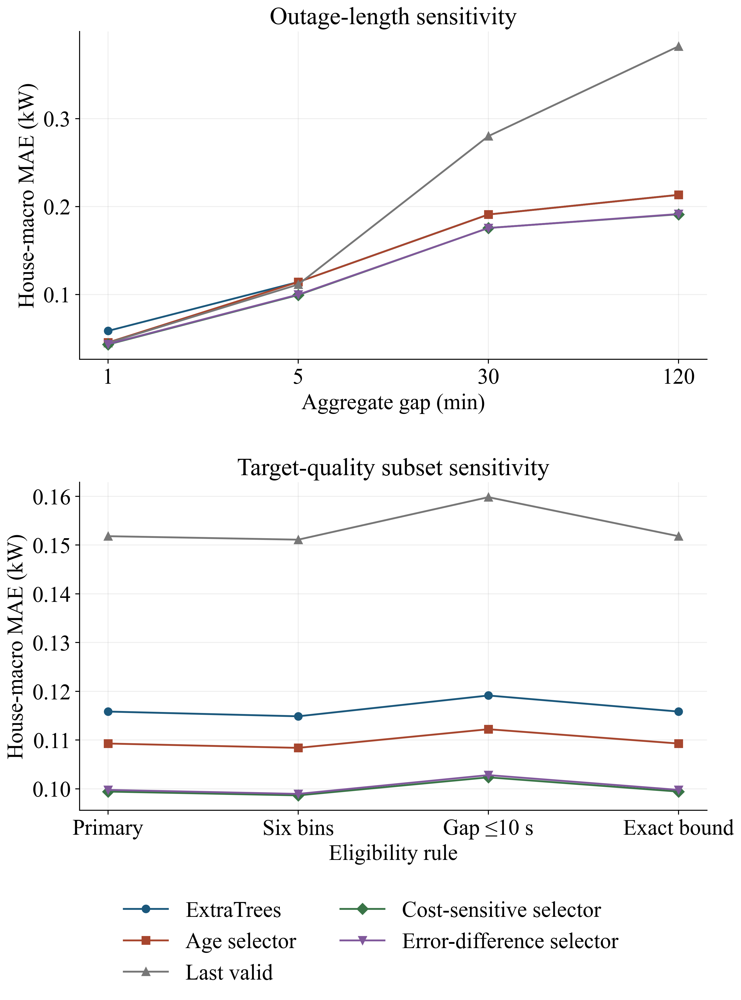

In [7]:
# Isolated presentation renderer; original scientific artifacts remain immutable.
def _presentation_nb03_v2_selector_figure():
    # Presentation only: load immutable, previously computed scientific results.
    from pathlib import Path
    import hashlib, json, textwrap
    import numpy as np
    import pandas as pd
    import matplotlib as mpl
    import matplotlib.pyplot as plt
    import matplotlib.dates as mdates
    from matplotlib import font_manager
    from matplotlib.text import Text
    from matplotlib.ticker import FuncFormatter, LogLocator
    from IPython.display import display, Image
    from PIL import Image as PILImage
    ROOT = Path.cwd().resolve()
    if ROOT.name == "Notebooks":
        ROOT = ROOT.parent
    assert ROOT.is_dir()
    INPUT_SHA256 = {'Tables/guldana_n3_20261009_v02/03_learned_selectors/all_gap_retention_mode_quality_scores.csv': '5877b5ce5e4e44bbb5cbfc6fc0812db9f9ee082649f8692b77ea9572c46f7d27'}
    for _relative, _expected in INPUT_SHA256.items():
        assert hashlib.sha256((ROOT / _relative).read_bytes()).hexdigest() == _expected, _relative
    assert Path(font_manager.findfont("Times New Roman", fallback_to_default=False)).is_file()
    mpl.rcParams.update({"font.family": "Times New Roman", "font.size": 18,
        "axes.titlesize": 20, "axes.labelsize": 18, "xtick.labelsize": 18,
        "ytick.labelsize": 18, "legend.fontsize": 18, "figure.dpi": 350,
        "savefig.dpi": 350, "axes.unicode_minus": True, "pdf.fonttype": 42,
        "ps.fonttype": 42, "axes.formatter.use_mathtext": False})
    _PNG = ROOT / "Figures/PNG/guldana_n3_20261011_presentation/NB03"
    _PDF = ROOT / "Figures/PDF/guldana_n3_20261011_presentation/NB03"
    _PNG.mkdir(parents=True, exist_ok=True)
    _PDF.mkdir(parents=True, exist_ok=True)
    def _label(name, width=22):
        name = str(name).replace("HistGradientBoosting", "Histogram boosting").replace("Mask_only_ExtraTrees", "Mask-only ExtraTrees").replace("Autoregressive_Ridge", "Autoregressive Ridge")
        return "\n".join(textwrap.wrap(name, width=width, break_long_words=False, break_on_hyphens=False))
    def _num(value, decimals=2):
        return f"{value:.{decimals}f}".replace("-", "−")
    def _quiet_axes(ax):
        ax.grid(alpha=.20)
        ax.spines[["top", "right"]].set_visible(False)
    def _export(fig, stem):
        fig.canvas.draw()
        for artist in fig.findobj(Text):
            if artist.get_visible() and artist.get_text():
                assert 18 <= artist.get_fontsize() <= 20, (artist.get_text(), artist.get_fontsize())
                assert artist.get_fontfamily() == ["Times New Roman"], artist.get_fontfamily()
        png = _PNG / (stem + ".png")
        pdf = _PDF / (stem + ".pdf")
        fig.savefig(png, dpi=350, bbox_inches="tight", pad_inches=.08)
        fig.savefig(pdf, dpi=350, bbox_inches="tight", pad_inches=.08)
        with PILImage.open(png) as image:
            assert all(abs(d - 350) < .02 for d in image.info["dpi"])
        plt.close(fig)
        display(Image(filename=str(png)))

    strata = pd.read_csv(ROOT / "Tables/guldana_n3_20261009_v02/03_learned_selectors/all_gap_retention_mode_quality_scores.csv")
    models=["ExtraTrees","Observable age selector","Last valid aggregate","CostSensitiveClassifier","ExpectedErrorDifference"]
    labels={"ExtraTrees":"ExtraTrees","Observable age selector":"Age selector","Last valid aggregate":"Last valid", "CostSensitiveClassifier":"Cost-sensitive selector","ExpectedErrorDifference":"Error-difference selector"}
    colors={"ExtraTrees":"#1B587C","Observable age selector":"#A7462E","Last valid aggregate":"#777777","CostSensitiveClassifier":"#397447","ExpectedErrorDifference":"#80589B"}
    fig, axes=plt.subplots(2,1,figsize=(8.8,11.6))
    gaps=sorted(strata.loc[strata.Stratum.eq("gap"),"Value"].astype(int).unique())
    quality_order=["Primary","Six bins","Maximum gap 10 s","No instrument allowance"]
    for index, model in enumerate(models):
        values=strata.loc[strata.Stratum.eq("gap")&strata.Model.eq(model)].assign(Gap=lambda d:d.Value.astype(int)).groupby("Gap")["MAE (kW)"].mean().reindex(gaps)
        assert values.notna().all()
        axes[0].plot(range(len(gaps)),values,marker=["o","s","^","D","v"][index],color=colors[model],label=labels[model])
        values=strata.loc[strata.Stratum.eq("quality")&strata.Model.eq(model)].groupby("Value")["MAE (kW)"].mean().reindex(quality_order)
        assert values.notna().all()
        axes[1].plot(range(4),values,marker=["o","s","^","D","v"][index],color=colors[model])
    axes[0].set_xticks(range(len(gaps)),[str(x) for x in gaps]); axes[0].set(title="Outage-length sensitivity",xlabel="Aggregate gap (min)",ylabel="House-macro MAE (kW)")
    axes[1].set_xticks(range(4),["Primary","Six bins","Gap ≤10 s","Exact bound"]); axes[1].set(title="Target-quality subset sensitivity",xlabel="Eligibility rule",ylabel="House-macro MAE (kW)")
    for ax in axes: _quiet_axes(ax)
    handles,names=axes[0].get_legend_handles_labels()
    fig.legend(handles,names,loc="lower center",bbox_to_anchor=(.5,.002),ncol=2,frameon=False)
    fig.tight_layout(rect=(0,.115,1,1),h_pad=2)
    _export(fig,"Figure_45_learned_selector_sensitivity")

_presentation_nb03_v2_selector_figure()


### Shared causal observation stress

The following prespecified robustness comparison uses the same 1,024 target-blind selected outer IDs per household/fold for all methods and all seeds. It tests delayed auxiliary telemetry, additional incomplete sensor sets, complete exclusion of the ambiguous deduplicated channel and longer minimum aggregate outages. Targets and locked partitions do not change. Previously removed historical observations are never restored. The unchanged-input case checks correspondence with the tabular inputs before stress effects are interpreted.

In [10]:
def keyed_uniform(*parts):
    key="|".join(map(str,parts)).encode()
    return int.from_bytes(hashlib.sha256(key).digest()[:8],"little")/2**64

def masked_tabular_rows(base_rows,batch,mapping):
    x=base_rows.copy()
    history=batch["history"]
    assert history.shape[2]==360
    mask=history[:,:,:,1].astype(bool)
    values=np.where(mask,history[:,:,:,0].astype(np.float64)*batch["target_scale"],np.nan)
    current=np.where(batch["current_mask"],batch["current_values"].astype(np.float64)*batch["target_scale"],np.nan)
    sensors=batch["sensor_names"];agg=sensors.index("P_agg")
    def summarize(a,width,stat):
        a=a[:,-width:];valid=np.isfinite(a);count=valid.sum(axis=1);filled=np.where(valid,a,0)
        if stat=="mean":return np.divide(filled.sum(axis=1),count,out=np.full(len(a),np.nan),where=count>0)
        if stat=="std":
            mean=np.divide(filled.sum(axis=1),count,out=np.zeros(len(a)),where=count>0)
            squares=np.where(valid,(a-mean[:,None])**2,0).sum(axis=1)
            return np.sqrt(np.divide(squares,count-1,out=np.full(len(a),np.nan),where=count>1))
        if stat=="min":return np.where(count>0,np.where(valid,a,np.inf).min(axis=1),np.nan)
        if stat=="max":return np.where(count>0,np.where(valid,a,-np.inf).max(axis=1),np.nan)
    def last_value(a):
        valid=np.isfinite(a);last=np.where(valid,np.arange(a.shape[1]),-1).max(axis=1)
        return np.where(last>=0,a[np.arange(len(a)),np.maximum(0,last)],np.nan),np.where(last>=0,a.shape[1]-last,a.shape[1]+1)
    for lag in [1,2,5,15,30,60,120,240,360]:x[f"aggregate_lag_{lag}"]=values[:,agg,-lag]
    for width in [15,60,240,360]:
        for stat in ["mean","std","min","max"]:x[f"aggregate_{stat}_{width}"]=summarize(values[:,agg,:],width,stat)
        x[f"aggregate_coverage_{width}"]=mask[:,agg,-width:].mean(axis=1)
    x["aggregate_last"],x["aggregate_age"]=last_value(values[:,agg,:])
    # Day/week retrieval is supplied by the same label-free context, with explicit presence bits.
    for j,lag in [(6,1440),(8,10080)]:
        x[f"aggregate_lag_{lag}"]=np.where(batch["context"][:,j+1]>0,batch["context"][:,j]*batch["target_scale"],np.nan)
    aux=[j for j,s in enumerate(sensors) if s!="P_agg"]
    x["current_aux_count"]=np.isfinite(current[:,aux]).sum(axis=1)
    x["current_aux_sum"]=np.where(x.current_aux_count>0,np.nansum(current[:,aux],axis=1),np.nan)
    for canonical in POWER_TYPES:
        idx=[sensors.index(s) for s in mapping if mapping[s]["type"]==canonical]
        tag=canonical.replace("/","_")
        if not idx:continue
        c=current[:,idx];cnt=np.isfinite(c).sum(axis=1)
        x[f"current_{tag}_sum"]=np.where(cnt>0,np.nansum(c,axis=1),np.nan)
        x[f"current_{tag}_count"]=cnt
        hv=values[:,idx,:]
        summed=np.where(np.isfinite(hv).any(axis=1),np.nansum(hv,axis=1),np.nan)
        for width in [15,60,240]:x[f"past_{tag}_mean_{width}"]=summarize(summed,width,"mean")
        x[f"past_{tag}_std_240"]=summarize(summed,240,"std")
        x[f"past_{tag}_last"]=last_value(summed)[0]
        x[f"past_{tag}_coverage_240"]=mask[:,idx,-240:].mean(axis=(1,2))
    return x.astype(np.float32)
# Shared observation interventions; no hidden historical value is restored.
schema=json.loads((ROOT/"Configs/sensor_schema.json").read_text())
POWER_TYPES=[t for t in schema["power_types"] if t!="aggregate"]
STRESS_PROTOCOL=json.loads((ROOT/"Configs/observation_stress_v2.json").read_text())
STRESS_SCENARIOS=STRESS_PROTOCOL["scenarios"]
def transform_frozen_state(raw,state):
    values=state["value_columns"];missing=state["missing_columns"]
    median=pd.Series(state["median"]);scale=pd.Series(state["scale"])
    numeric=((raw[values].fillna(median)-median[values])/scale[values]).astype(np.float32)
    result=np.column_stack([numeric.to_numpy(),raw[missing].isna().to_numpy(dtype=np.float32)])
    assert np.isfinite(result).all();return result

def observed_stress_batch(batch,metadata,mapping,scenario):
    result={k:(v.copy() if isinstance(v,np.ndarray) else v) for k,v in batch.items()}
    history=result["history"];current=result["current_values"];mask=result["current_mask"]
    names=result["sensor_names"];delay=scenario["delay"];retention=scenario["retention"]
    for j,sensor in enumerate(names):
        if sensor=="P_agg":continue
        if delay:
            current[:,j]=history[:,j,-delay,0]
            mask[:,j]=history[:,j,-delay,1].astype(bool)
            original_keep=np.array([keyed_uniform(identity,seed,sensor)<keep for identity,seed,keep in
                zip(metadata.observation_id,metadata.seed,metadata.retention)])
            mask[:,j]&=original_keep
            old_history=history[:,j].copy();history[:,j]=0;history[:,j,delay:]=old_history[:,:-delay]
        additional=np.array([keyed_uniform(identity,seed,sensor,"v2_stress")<retention for identity,seed in zip(metadata.observation_id,metadata.seed)])
        mask[:,j]&=additional;history[~additional,j]=0
    agg=names.index("P_agg");gap=scenario["minimum_gap"]
    if gap>1:history[:,agg,-(gap-1):,:3]=0
    visible=history[:,:,:,1].astype(bool);positions=np.arange(360)[None,None,:]
    last=np.maximum.accumulate(np.where(visible,positions,-361),axis=-1)
    history[:,:,:,3]=np.minimum(positions-last,361)/361
    history[:,:,:,0]=np.where(visible,history[:,:,:,0],0);history[:,:,:,2]=np.where(visible,history[:,:,:,2],0)
    current[:]=np.where(mask,current,0)
    selected={s:m for s,m in mapping.items() if not(scenario["exclude_ambiguous"] and len(m["members"])>1)}
    keep=[names.index(s) for s in ["P_agg",*sorted(selected)]]
    for key in ["history","current_values","current_mask"]:result[key]=result[key][:,keep]
    for key in ["type_ids","role_ids"]:result[key]=result[key][keep]
    result["sensor_names"]=[names[j] for j in keep]
    assert not result["current_mask"][:,0].any()
    return result,selected

def stress_raw_rows(raw,batch,mapping):
    base=raw.copy();base["installed_aux_count"]=len(mapping)
    for canonical in POWER_TYPES:
        tag=canonical.replace("/","_");members=[s for s in mapping if mapping[s]["type"]==canonical]
        base[f"installed_{tag}_count"]=len(members)
        if not members:
            for key in [f"current_{tag}_sum",f"past_{tag}_std_240",f"past_{tag}_last",*[f"past_{tag}_mean_{w}" for w in [15,60,240]]]:base[key]=np.nan
            base[f"current_{tag}_count"]=0;base[f"past_{tag}_coverage_240"]=0
    return masked_tabular_rows(base,batch,mapping)

def run_observation_stress(fold,seed):
    started=time.perf_counter();x,raw,meta=selector_inputs(fold,seed)
    state=json.loads((OLD_PREP/f"fold_{fold}_preprocessing.json").read_text())
    folder=ROOT/"Data/Processed"/OLD_RUN/"neural_inputs_v1"/f"fold_{fold}_seed_{seed}"
    manifest=json.loads((folder/"manifest.json").read_text())
    assert manifest["metadata_sha256"]==v2_sha(CACHE/f"fold_{fold}_seed_{seed}.parquet")
    arrays={item["name"][:-4]:np.load(folder/item["name"],mmap_mode="r",allow_pickle=False) for item in manifest["arrays"]}
    chosen=[]
    for house,part in meta.loc[meta.role.eq("outer_validation")].groupby("house"):
        rank=part.observation_id.map(lambda identity:hashlib.sha256(f"{identity}|v2_stress".encode()).hexdigest())
        chosen.extend(rank.nsmallest(1024).index if rank.dtype!='object' else rank.sort_values().index[:1024])
    chosen=np.asarray(sorted(chosen),dtype=int);selected_meta=meta.iloc[chosen].reset_index(drop=True)
    assert len(chosen)==10240 and selected_meta.groupby("house").size().eq(1024).all()
    selected_meta[["observation_id","fold","house"]].to_parquet(V2_DATA/f"stress_ids_fold_{fold}_seed_{seed}.parquet",index=False)
    alternatives={scenario["name"]:np.empty((len(chosen),len(raw.columns)),dtype=np.float32) for scenario in STRESS_SCENARIOS}
    input_progress=display(pd.DataFrame(columns=["Fold","Seed","House","Phase"]),display_id=True)
    for house in range(1,11):
        positions=np.flatnonzero(selected_meta.house.eq(house));mapping=state["duplicate_maps"][str(house)];names=["P_agg",*sorted(mapping,key=lambda sensor:(schema["power_types"].index(mapping[sensor]["type"]),sensor))];n=len(names)
        for offset in range(0,len(positions),256):
            pos=positions[offset:offset+256];rows=chosen[pos]
            batch={"history":np.array(arrays["history"][rows,:n],copy=True),
                "current_values":np.array(arrays["current_values"][rows,:n],copy=True),"current_mask":np.array(arrays["current_mask"][rows,:n],copy=True),
                "context":np.array(arrays["context"][rows],copy=True),"type_ids":np.array(arrays["type_ids"][rows[0],:n],copy=True),
                "role_ids":np.array(arrays["role_ids"][rows[0],:n],copy=True),"sensor_names":names,"target_scale":state["target_scale"]}
            for scenario in STRESS_SCENARIOS:
                changed,selected=observed_stress_batch(batch,selected_meta.iloc[pos],mapping,scenario)
                derived=stress_raw_rows(raw.iloc[rows].reset_index(drop=True),changed,selected)
                if scenario["name"]=="Tensor replay":np.testing.assert_allclose(derived,raw.iloc[rows].to_numpy(),rtol=2e-4,atol=2e-5,equal_nan=True)
                alternatives[scenario["name"]][pos]=derived.to_numpy()
        input_progress.update(pd.DataFrame([{"Fold":fold,"Seed":seed,"House":house,"Phase":"Constructed all 12 common stress inputs"}]).style.hide(axis="index"))
    preparation_seconds=time.perf_counter()-started
    expert=joblib.load(OLD_MODEL/f"ExtraTrees_fold_{fold}_seed_{seed}.joblib")["model"];expert.set_params(n_jobs=1)
    gates={family:joblib.load(V2_MODELS/f"{family}_fold_{fold}_seed_{seed}.joblib")["model"] for family in SELECTOR_PROTOCOL["families"]}
    medians=meta.loc[meta.role.eq("train")].groupby("house").y_kW.median();fallback=selected_meta.house.map(medians).to_numpy()
    output_parts=[];scores=[];original=expert.predict(x[chosen]);replay_difference=None
    for scenario in STRESS_SCENARIOS:
        name=scenario["name"];r=pd.DataFrame(alternatives[name],columns=raw.columns)
        t=time.perf_counter();tree=expert.predict(transform_frozen_state(r,state));last=r.aggregate_last.to_numpy(dtype=float);last=np.where(np.isfinite(last),last,fallback)
        if name=="Tensor replay":replay_difference=float(np.max(abs(tree-original)))
        pair=np.column_stack([last,tree]);features=gate_features(r,pair)
        result=selected_meta.copy();result["Stress"]=name;result["ExtraTrees"]=tree
        result["Observable age selector"]=np.where(r.aggregate_last.notna().to_numpy()&r.aggregate_age.le(1).to_numpy(),last,tree)
        for family,gate in gates.items():result[family]=selected_prediction(gate,family,features,pair)[0]
        seconds=time.perf_counter()-t;output_parts.append(result)
        for model in ["ExtraTrees","Observable age selector",*gates]:scores.append({"Fold":fold,"Seed":seed,"Stress":name,"Model":model,
            **macro_metrics(result,result[model]),"Shared preparation seconds":preparation_seconds,"Joint prediction seconds":seconds})
    out=V2_PRED/f"observation_stress_fold_{fold}_seed_{seed}.parquet";pd.concat(output_parts,ignore_index=True).to_parquet(out,index=False)
    pd.DataFrame(scores).to_csv(V2_TABLES/f"observation_stress_fold_{fold}_seed_{seed}.csv",index=False)
    record={"fold":fold,"seed":seed,"source_protocol_sha256":v2_sha(ROOT/"Configs/observation_stress_v2.json"),
        "selected_ID_sha256":v2_sha(V2_DATA/f"stress_ids_fold_{fold}_seed_{seed}.parquet"),"prediction_sha256":v2_sha(out),
        "tensor_replay_maximum_tree_prediction_difference_kW":replay_difference,"elapsed_seconds":time.perf_counter()-started}
    (V2_RECORD/f"observation_stress_fold_{fold}_seed_{seed}.json").write_text(json.dumps(record,indent=2)+"\n")
    del arrays,x,raw,alternatives,output_parts,expert,gates;gc.collect()
    return record


In [11]:
stress_records=[]
for fold in [1,2,3]:
    for seed in [17,43,101]:
        clear_output(wait=True);display(Markdown(f"Paired observation stress: fold {fold}, seed {seed}."))
        stress_records.append(run_observation_stress(fold,seed))
clear_output(wait=True)
stress_scores=pd.concat([pd.read_csv(V2_TABLES/f"observation_stress_fold_{fold}_seed_{seed}.csv") for fold in [1,2,3] for seed in [17,43,101]],ignore_index=True)
stress_scores.to_csv(V2_TABLES/"all_observation_stress_scores.csv",index=False)
stress_summary=stress_scores.groupby(["Stress","Model"])["MAE (kW)"].mean().unstack().reindex([s["name"] for s in STRESS_SCENARIOS]).reset_index()
v2_table(stress_summary,"observation_stress_summary","Paired stress on 1,024 target-blind selected OOF queries per house/fold, all three seeds. Additional dropout cannot recover an already hidden value; minimum-gap scenarios can only remove more aggregate history. All compared methods receive the same altered observations.")
assert all(r["tensor_replay_maximum_tree_prediction_difference_kW"]<1e-5 for r in stress_records)

if NATIVE03_PREVIOUS is not None:
    assert len(NATIVE03_REPLAY)==9
    pd.DataFrame(NATIVE03_REPLAY).to_csv(V2_TABLES/"native_independent_replay.csv",index=False)
    verified={relative:v2_sha(ROOT/relative) for relative in NATIVE03_PREVIOUS["files"]}
    replay_path=V2_TABLES/"native_independent_replay.csv";verified[str(replay_path.relative_to(ROOT))]=v2_sha(replay_path)
    updated={**NATIVE03_PREVIOUS,"files":verified,"final_ordered_replay_pid":os.getpid(),"retained_OOF_rows_replayed":368640,
        "search_scalar_scores_replayed":24,"fits_repeated_in_final_pass":0,"verification_utc":pd.Timestamp.now(tz="UTC").isoformat()}
    NATIVE03_GATE_PATH.write_text(json.dumps(updated,indent=2)+"\n")


Stress,CostSensitiveClassifier,ExpectedErrorDifference,ExtraTrees,Observable age selector
Tensor replay,0.0995,0.0996,0.1159,0.1092
Auxiliary delay 1 min,0.1041,0.1042,0.1213,0.1129
Auxiliary delay 2 min,0.1076,0.1074,0.1248,0.1155
Additional retention 0.75,0.1073,0.1072,0.1244,0.1174
Additional retention 0.50,0.1140,0.1139,0.1320,0.1249
Additional retention 0.25,0.1210,0.1207,0.1395,0.1323
Additional retention 0.00,0.1287,0.1285,0.1475,0.1402
Exclude ambiguous token,0.0997,0.0998,0.1161,0.1093
Minimum gap 15 min,0.1715,0.1736,0.1812,0.1812
Minimum gap 60 min,0.1936,0.1938,0.2161,0.2161


**Result (development evidence).** Across the unchanged three folds and three seeds, the learned cost-sensitive selector achieved house-macro MAE 0.09943 kW versus 0.10929 for the observable-age rule and 0.11585 for ExtraTrees. Its error-difference counterpart achieved 0.09978 kW. Both improved MAE in all ten households, but worsened squared error in all ten: given the RMSE and negative bias, the selectors are not uniformly more accurate. Seed-averaged paired household tests gave Holm-adjusted p = 0.015625 across the eight displayed contrasts; the 240-minute hierarchical bootstrap interval for cost-sensitive minus age-rule MAE was [−0.01188, −0.00778] kW. Seeds are not independent experimental units.

The paired stress experiment preserved the MAE ordering under 1–2-minute auxiliary delays, additional sensor losses, removal of the ambiguous token and minimum aggregate-history gaps up to 360 minutes. At two-minute delay, cost-sensitive MAE was 0.1076 versus 0.1155 kW for the age rule; at minimum gap 360 minutes it was 0.2324 versus 0.2524 kW. These are altered-information scenarios on a fixed target-blind subset, not independent test sets or uniform-gap cohorts. Stricter measurement-quality subsets likewise remain observational sensitivity analyses, not a missing-data selection correction. Gate training took approximately 0.7–1.0 seconds after the shared cross-fit expert work; the resource table above includes that prerequisite. No manual prediction weights were introduced.

These controls set the comparison standard for Notebook 05, which must reuse the same observation-stress IDs and transformations. The proposed model has not yet demonstrated an advantage over them. Evaluation on the previously inspected test partitions is retrospective; independently acquired external measurements are not used at this stage.

## Matched observations: refitted 60-minute classical controls

The native results above remain valid for their original representations. This separate arm addresses the unequal dense-history windows across model inputs. Its features are derived solely from the tensors available to a 60-minute neural model. Semantic pooling removes channel-order dependence; current aggregate, household identity and older dense power values are excluded. Shared seasonal context and causal availability ages are retained explicitly.

ExtraTrees is selected from four prespecified leaf sizes using the complete inner cohort at seed 17. Each retained tree is fitted on the full training role. The age rule retains its original threshold without tuning. The two learned gates retain the same four candidate complexities and chronological prefix crossfit design, but every expert and feature transform is refitted for this input definition. All naive fallbacks use a training-only global target median. There are no manually chosen prediction weights. Tables from this section complement, and do not replace, the unrestricted strong baselines above.

In [12]:
# One observable representation, shared verbatim with later matched-window controls.
COMMON_OBSERVATION_KEYS=("history","current_values","current_mask","installed","type_ids","role_ids","unit_ids","context")
def common60_features(inputs,target_scale,n_types=15):
    """Pure label-free map of the same cropped sensor tensors and shared context."""
    h=np.asarray(inputs["history"],dtype=np.float64)[:,:,-60:,:]
    assert h.shape[2:]==(60,4)
    installed=np.asarray(inputs["installed"],dtype=bool)
    types=np.asarray(inputs["type_ids"],dtype=int)
    observed=(h[:,:,:,1]>0)&installed[:,:,None]
    current_mask=np.asarray(inputs["current_mask"],dtype=bool)&installed
    aggregate=installed&(types==0)
    assert np.all(aggregate.sum(axis=1)==1) and not (current_mask&aggregate).any()
    assert np.isfinite(h[:,:,:,0][observed]).all()
    current=np.asarray(inputs["current_values"],dtype=np.float64)
    assert np.isfinite(current[current_mask]).all()
    context=np.asarray(inputs["context"],dtype=np.float64)
    assert context.shape==(len(h),14) and np.isfinite(context).all()
    power=np.where(observed,h[:,:,:,0],0.)*float(target_scale)
    current=np.where(current_mask,current,0.)*float(target_scale)
    # Undo the full-training target scale before chronological prefix controls.
    # Temperature and humidity use fixed physical constants (50 C and 100 percent).
    context=context.copy();context[:,[6,8]]*=float(target_scale)
    features={f"context_{j:02d}":context[:,j] for j in range(14)}
    for semantic in range(n_types):
        selected=installed&(types==semantic);count=selected.sum(axis=1)
        visible=observed&selected[:,:,None]
        counts=visible.sum(axis=1);summed=np.where(visible,power,0.).sum(axis=1)
        valid=counts>0;values=np.where(valid,summed,np.nan)
        tag=f"type_{semantic:02d}"
        features[tag+"_installed"]=count
        features[tag+"_current_count"]=(current_mask&selected).sum(axis=1)
        features[tag+"_current_sum"]=np.where(features[tag+"_current_count"]>0,np.where(selected,current,0.).sum(axis=1),np.nan)
        for lag in [1,2,5,15,30,60]:features[tag+f"_lag_{lag}"]=values[:,-lag]
        last=np.where(valid,np.arange(60),-1).max(axis=1)
        features[tag+"_last"]=np.where(last>=0,values[np.arange(len(h)),np.maximum(0,last)],np.nan)
        features[tag+"_window_age"]=np.where(last>=0,60-last,61)
        # Availability ages are shared with the neural inputs; no associated older power is recovered.
        age=np.clip(h[:,:,-1,3]*361+1,0,361)
        features[tag+"_availability_age_min"]=np.where(count>0,np.where(selected,age,np.inf).min(axis=1),np.nan)
        features[tag+"_availability_age_max"]=np.where(count>0,np.where(selected,age,-np.inf).max(axis=1),np.nan)
        for width in [15,60]:
            v=valid[:,-width:];a=np.where(v,values[:,-width:],0.);number=v.sum(axis=1)
            mean=np.divide(a.sum(axis=1),number,out=np.zeros(len(h)),where=number>0)
            features[tag+f"_mean_{width}"]=np.where(number>0,mean,np.nan)
            square=np.where(v,(a-mean[:,None])**2,0.).sum(axis=1)
            variance=np.divide(square,number-1,out=np.zeros(len(h)),where=number>1)
            features[tag+f"_std_{width}"]=np.where(number>1,np.sqrt(np.maximum(variance,0)),np.nan)
            features[tag+f"_min_{width}"]=np.where(number>0,np.where(v,a,np.inf).min(axis=1),np.nan)
            features[tag+f"_max_{width}"]=np.where(number>0,np.where(v,a,-np.inf).max(axis=1),np.nan)
            features[tag+f"_coverage_{width}"]=np.divide(counts[:,-width:].sum(axis=1),width*count,out=np.zeros(len(h)),where=count>0)
            coverage=np.where(visible[:,:,-width:],h[:,:,-width:,2],0.).sum(axis=(1,2))
            features[tag+f"_measurement_coverage_{width}"]=np.divide(coverage,width*count,out=np.zeros(len(h)),where=count>0)
    frame=pd.DataFrame(features,dtype=np.float32)
    assert not np.isinf(frame.to_numpy()).any()
    return frame


In [13]:
COMMON60_PROTOCOL=json.loads((ROOT/"Configs/common_observation_60_v2.json").read_text())
COMMON60_PROTOCOL_HASH=v2_sha(ROOT/"Configs/common_observation_60_v2.json")
common60_gate=json.loads((V2_RECORD/"nb02_common60_observation_gate.json").read_text())
assert common60_gate["status"]=="common60_tensor_map_verified" and common60_gate["protocol_sha256"]==COMMON60_PROTOCOL_HASH
common60_local="".join(next(c for c in json.loads((ROOT/"Notebooks/03_baseline_models_and_error_diagnostics.ipynb").read_text())["cells"] if c.get("id")=="2253687d")["source"])
COMMON60_SOURCE_HASH=hashlib.sha256(common60_local.encode()).hexdigest()
assert COMMON60_SOURCE_HASH==common60_gate["source_sha256"]
C60_DATA=ROOT/"Data/Processed"/V2_RUN/"common60_classical"
C60_MODELS=ROOT/"Models/baselines"/V2_RUN/"common60"
C60_PRED=ROOT/"Predictions/development"/V2_RUN/"common60"
C60_TABLES=ROOT/"Tables"/V2_RUN/"03_common60"
for directory in [C60_DATA,C60_MODELS,C60_PRED,C60_TABLES]:directory.mkdir(parents=True,exist_ok=True)
C60_FAMILIES=COMMON60_PROTOCOL["classical"]["models"]
common60_notebook=json.loads((ROOT/"Notebooks/03_baseline_models_and_error_diagnostics.ipynb").read_text())
# The figure-only cell split changes notebook positions, not the frozen model implementation.
# The reviewed structural amendment binds exact current sources to archived original sources.
_common60_binding_path = ROOT / 'Manifests/Runs/guldana_n3_20261011_presentation/common60_structural_source_amendment.json'
_common60_binding = json.loads(_common60_binding_path.read_text())
_common60_ids = ['v2-baseline-crossfit', 'v2-baseline-runner', '2253687d', '338c59c5', '4226455c']
_common60_frozen_sha = '8b678909f4ad1fda59efcf6e09bdb79d25a469f3575671d615bf3cc00ac1e098'
assert _common60_binding["ordered_stable_ids"] == _common60_ids
assert _common60_binding["historical_implementation_sha256"] == _common60_frozen_sha
_common60_actual = {c["id"]: "".join(c["source"]) for c in common60_notebook["cells"] if c.get("id") in _common60_ids}
assert set(_common60_actual) == set(_common60_ids)
assert len([c for c in common60_notebook["cells"] if c.get("id") in _common60_ids]) == len(_common60_ids)
assert set(_common60_binding["cells"]) == set(_common60_ids)
for _common60_id in _common60_ids:
    _common60_item = _common60_binding["cells"][_common60_id]
    assert _common60_actual[_common60_id] == _common60_item["approved_current_source"], f"Unreviewed implementation change: {_common60_id}"
    assert hashlib.sha256(_common60_actual[_common60_id].encode()).hexdigest() == _common60_item["approved_current_source_sha256"]
    assert hashlib.sha256(_common60_item["historical_source"].encode()).hexdigest() == _common60_item["historical_source_sha256"]
    if _common60_id != "338c59c5":
        assert _common60_actual[_common60_id] == _common60_item["historical_source"]
COMMON60_IMPLEMENTATION_HASH = hashlib.sha256("\n".join(_common60_binding["cells"][_common60_id]["historical_source"] for _common60_id in _common60_ids).encode()).hexdigest()
assert COMMON60_IMPLEMENTATION_HASH == _common60_frozen_sha
def c60_table(frame,name,caption,precision=4):
    frame.to_csv(C60_TABLES/(name+".csv"),index=False)
    frame.to_latex(C60_TABLES/(name+".tex"),index=False,caption=caption,float_format=lambda x:f"{x:.{precision}f}")
    display(frame.style.format(precision=precision,na_rep="Not applicable").hide(axis="index").set_caption(caption))
def c60_inputs(fold,seed):
    folder=ROOT/"Data/Processed"/OLD_RUN/"neural_inputs_v1"/f"fold_{fold}_seed_{seed}"
    metadata_path=CACHE/f"fold_{fold}_seed_{seed}.parquet"
    cache_record=json.loads((folder/"manifest.json").read_text())
    assert v2_sha(metadata_path)==cache_record["metadata_sha256"]
    metadata=pd.read_parquet(metadata_path)
    state=json.loads((OLD_PREP/f"fold_{fold}_preprocessing.json").read_text())
    array_path=C60_DATA/f"features_fold_{fold}_seed_{seed}.npy"
    proof_path=C60_DATA/f"features_fold_{fold}_seed_{seed}.json"
    binding={"protocol_sha256":COMMON60_PROTOCOL_HASH,"feature_source_sha256":COMMON60_SOURCE_HASH,
        "cache_manifest_sha256":v2_sha(folder/"manifest.json"),"metadata_sha256":v2_sha(metadata_path),
        "preprocessing_sha256":v2_sha(OLD_PREP/f"fold_{fold}_preprocessing.json")}
    if proof_path.exists():
        record=json.loads(proof_path.read_text());assert record["binding"]==binding and v2_sha(array_path)==record["feature_array_sha256"]
        raw=pd.DataFrame(np.load(array_path,allow_pickle=False),columns=record["columns"])
        return raw,metadata,record
    started=time.perf_counter();parts=[]
    arrays={key:np.load(folder/(key+".npy"),mmap_mode="r",allow_pickle=False) for key in COMMON_OBSERVATION_KEYS}
    for offset in range(0,len(metadata),512):
        rows=np.arange(offset,min(offset+512,len(metadata)))
        batch={key:np.array(value[rows],copy=True) for key,value in arrays.items()}
        parts.append(common60_features(batch,state["target_scale"]))
    raw=pd.concat(parts,ignore_index=True);np.save(array_path,raw.to_numpy(dtype=np.float32),allow_pickle=False)
    record={"binding":binding,"columns":raw.columns.tolist(),"rows":len(raw),"feature_array_sha256":v2_sha(array_path),"construction_seconds":time.perf_counter()-started}
    proof_path.write_text(json.dumps(record,indent=2)+"\n")
    del arrays,parts;gc.collect()
    return raw,metadata,record

def c60_fit_transform(raw,training):
    values=raw.to_numpy(dtype=np.float32);train=values[training];valid=np.isfinite(train).any(axis=0)
    median=np.zeros(values.shape[1],dtype=np.float32)
    median[valid]=np.nanmedian(train[:,valid],axis=0)
    state={"columns":raw.columns.tolist(),"median":median.tolist(),"all_missing_on_train":(~valid).tolist()}
    return c60_transform(raw,state),state

def c60_transform(raw,state):
    assert raw.columns.tolist()==state["columns"]
    values=raw.to_numpy(dtype=np.float32);missing=~np.isfinite(values)
    result=np.column_stack([np.where(missing,np.asarray(state["median"],dtype=np.float32),values),missing.astype(np.float32)])
    assert np.isfinite(result).all();return result

def c60_last(raw,fallback):
    last=raw["type_00_last"].to_numpy(dtype=float)
    return np.where(np.isfinite(last),last,float(fallback))

def c60_gate_features(raw,experts):
    result=raw.copy();result["last_expert"]=experts[:,0];result["tree_expert"]=experts[:,1]
    result["expert_disagreement"]=abs(experts[:,0]-experts[:,1]);return result

C60_PROGRESS=None
def c60_progress(phase,queries=None,seconds=None):
    if C60_PROGRESS is not None:
        C60_PROGRESS.update(pd.DataFrame([{"Phase":phase,"Training queries":queries,"Elapsed seconds":seconds}]).style.hide(axis="index").format(precision=2,na_rep="In progress"))
def c60_fit_tree(raw,metadata,training,params,seed,stem):
    checkpoint=C60_MODELS/(stem+".joblib");record_path=C60_MODELS/(stem+".json")
    train_ids=hashlib.sha256("\n".join(metadata.loc[training,"observation_id"]).encode()).hexdigest()
    if record_path.exists():
        record=json.loads(record_path.read_text());assert record["train_ids_sha256"]==train_ids
        assert record["protocol_sha256"]==COMMON60_PROTOCOL_HASH and record["parameters"]==params
        assert record["implementation_sha256"]==COMMON60_IMPLEMENTATION_HASH
        assert v2_sha(checkpoint)==record["checkpoint_sha256"]
        bundle=joblib.load(checkpoint);return bundle,record
    t=time.perf_counter();transformed,state=c60_fit_transform(raw,training);transform_seconds=time.perf_counter()-t
    c60_progress(stem+": fitting",int(training.sum()))
    model=ExtraTreesRegressor(**params,random_state=seed,n_jobs=4)
    t=time.perf_counter()
    with threadpool_limits(limits=4):model.fit(transformed[training],metadata.loc[training,"y_kW"])
    duration=time.perf_counter()-t;model.set_params(n_jobs=1)
    c60_progress(stem+": fit complete",int(training.sum()),duration)
    bundle={"model":model,"preprocessing":state,"fallback":float(metadata.loc[training,"y_kW"].median()),
        "parameters":params,"protocol_sha256":COMMON60_PROTOCOL_HASH,"feature_source_sha256":COMMON60_SOURCE_HASH,"train_ids_sha256":train_ids}
    joblib.dump(bundle,checkpoint,compress=3)
    record={"family":"ExtraTrees","stem":stem,"parameters":params,"seed":seed,"fit_seconds":duration,"transform_seconds":transform_seconds,
        "training_queries":int(training.sum()),"tree_nodes":sum(t.tree_.node_count for t in model.estimators_),
        "train_ids_sha256":train_ids,"protocol_sha256":COMMON60_PROTOCOL_HASH,"implementation_sha256":COMMON60_IMPLEMENTATION_HASH,"checkpoint":str(checkpoint.relative_to(ROOT)),
        "checkpoint_sha256":v2_sha(checkpoint),"checkpoint_bytes":checkpoint.stat().st_size,"original_kernel_pid":os.getpid()}
    record_path.write_text(json.dumps(record,indent=2)+"\n");del transformed;gc.collect()
    return bundle,record

def c60_tree_predict(bundle,raw):
    transformed=c60_transform(raw,bundle["preprocessing"])
    with threadpool_limits(limits=4):prediction=bundle["model"].predict(transformed)
    return prediction

def c60_crossfit(raw,metadata,parameters,fold,seed):
    train=metadata.role.eq("train").to_numpy();rank=np.full(len(metadata),-1,dtype=int);size=np.zeros(len(metadata),dtype=int)
    for house,part in metadata.loc[train].groupby("house"):
        indices=part.sort_values("timestamp").index.to_numpy();rank[indices]=np.arange(len(indices));size[indices]=len(indices)
    pieces=[];resources=[]
    for stage in [1,2]:
        prefix=train&(rank<size*stage//3);held=train&(rank>=size*stage//3)&(rank<size*(stage+1)//3)
        assert not(prefix&held).any()
        for house in metadata.house.unique():assert metadata.loc[prefix&metadata.house.eq(house),"timestamp"].max()<metadata.loc[held&metadata.house.eq(house),"timestamp"].min()
        bundle,record=c60_fit_tree(raw,metadata,prefix,parameters,seed,f"crossfit_fold_{fold}_seed_{seed}_stage_{stage}")
        part=metadata.loc[held].copy();t=time.perf_counter();part["tree_prediction_kW"]=c60_tree_predict(bundle,raw.loc[held])
        part["last_prediction_kW"]=c60_last(raw.loc[held],bundle["fallback"]);part["prefix_stage"]=stage
        record={**record,"predict_seconds":time.perf_counter()-t,"held_queries":int(held.sum())}
        restored=joblib.load(ROOT/record["checkpoint"])
        np.testing.assert_array_equal(part.tree_prediction_kW,c60_tree_predict(restored,raw.loc[held]))
        pieces.append(part);resources.append(record);del bundle,restored;gc.collect()
    pseudo=pd.concat(pieces).sort_index();assert pseudo.observation_id.is_unique and pseudo.role.eq("train").all()
    pseudo.to_parquet(C60_PRED/f"pseudo_fold_{fold}_seed_{seed}.parquet",index=False)
    return pseudo,resources

def c60_fit_gate_state(family,params,features,pseudo,seed,stem,expert_sha256):
    path=C60_MODELS/(stem+".joblib");record_path=C60_MODELS/(stem+".json")
    pseudo_hash=hashlib.sha256(pd.util.hash_pandas_object(pseudo[["observation_id","y_kW","last_prediction_kW","tree_prediction_kW"]],index=False).to_numpy().tobytes()).hexdigest()
    binding={"protocol_sha256":COMMON60_PROTOCOL_HASH,"implementation_sha256":COMMON60_IMPLEMENTATION_HASH,
        "family":family,"parameters":params,"seed":seed,"pseudo_sha256":pseudo_hash,"expert_checkpoint_sha256":expert_sha256}
    if record_path.exists():
        resource=json.loads(record_path.read_text());assert resource["binding"]==binding and v2_sha(path)==resource["checkpoint_sha256"]
        return joblib.load(path)["model"],resource
    c60_progress(stem+": fitting",len(pseudo))
    t=time.perf_counter()
    with threadpool_limits(limits=4):model=fit_gate(family,params,features,pseudo,seed)
    duration=time.perf_counter()-t
    c60_progress(stem+": fit complete",len(pseudo),duration)
    joblib.dump({"model":model,"parameters":params,"family":family,"feature_columns":features.columns.tolist(),**binding},path,compress=3)
    resource={"binding":binding,"family":family,"seed":seed,"fit_seconds":duration,"checkpoint":str(path.relative_to(ROOT)),"checkpoint_sha256":v2_sha(path),"checkpoint_bytes":path.stat().st_size,"original_kernel_pid":os.getpid(),"training_pseudo_OOF_queries":len(pseudo)}
    record_path.write_text(json.dumps(resource,indent=2)+"\n")
    return model,resource


In [14]:
def run_common60_fold(fold):
    global C60_PROGRESS
    search_rows=[];all_resources=[];metric_rows=[];selections={};replay_rows=[]
    final_paths=[C60_MODELS/f"complete_fold_{fold}_seed_{seed}.json" for seed in [17,43,101]]
    if all(path.exists() for path in final_paths) and (C60_MODELS/f"selection_fold_{fold}.json").exists() and (C60_TABLES/f"resources_fold_{fold}.csv").exists():
        for path in final_paths:
            proof=json.loads(path.read_text());assert proof["protocol_sha256"]==COMMON60_PROTOCOL_HASH and proof["implementation_sha256"]==COMMON60_IMPLEMENTATION_HASH
            for item in proof["checkpoints"].values():assert v2_sha(ROOT/item["path"])==item["sha256"]
            seed=proof["seed"];prediction_path=C60_PRED/f"common60_fold_{fold}_seed_{seed}.parquet"
            assert v2_sha(prediction_path)==proof["prediction_sha256"]
            result=pd.read_parquet(prediction_path)
            for family in C60_FAMILIES:metric_rows.append({"Fold":fold,"Seed":seed,"Model":family,**macro_metrics(result,result[family].to_numpy())})
        c60_table(pd.read_csv(C60_TABLES/f"search_fold_{fold}.csv"),f"search_summary_fold_{fold}",f"Recorded complete inner-only search, fold {fold}; no refit during verified resume.")
        c60_table(pd.DataFrame(metric_rows),f"OOF_metrics_fold_{fold}",f"Recomputed metrics from verified saved common-observation predictions, fold {fold}. Fresh-state replay follows separately.")
        return metric_rows
    for seed in [17,43,101]:
        clear_output(wait=True);display(Markdown(f"Common 60-minute observations: fold {fold}, seed {seed}."))
        C60_PROGRESS=display(pd.DataFrame([{"Phase":"Constructing tensor-only features","Fold":fold,"Seed":seed}]),display_id=True)
        raw,metadata,input_record=c60_inputs(fold,seed)
        train=metadata.role.eq("train").to_numpy();inner=metadata.role.eq("inner_validation").to_numpy();outer=metadata.role.eq("outer_validation").to_numpy()
        assert train.sum()==65530 and inner.sum()==10240 and outer.sum()==40960
        if seed==17:
            search_train=train&metadata.search_train.to_numpy(dtype=bool);assert search_train.sum()==16380
            for trial,params in enumerate(COMMON60_PROTOCOL["classical"]["tree_search"],1):
                bundle,resource=c60_fit_tree(raw,metadata,search_train,params,seed,f"search_ExtraTrees_fold_{fold}_trial_{trial}")
                t=time.perf_counter();prediction=c60_tree_predict(bundle,raw.loc[inner]);pred_seconds=time.perf_counter()-t
                score=macro_metrics(metadata.loc[inner],prediction)["MAE (kW)"]
                search_rows.append({"Fold":fold,"Family":"ExtraTrees","Trial":trial,"Inner MAE (kW)":score,"Fit seconds":resource["fit_seconds"],"Inner prediction seconds":pred_seconds})
                all_resources.append({**resource,"phase":"tree_search","predict_seconds":pred_seconds});del bundle;gc.collect()
            best=min(search_rows,key=lambda r:(r["Inner MAE (kW)"],r["Trial"]))
            selections["ExtraTrees"]={"trial":best["Trial"],"parameters":COMMON60_PROTOCOL["classical"]["tree_search"][best["Trial"]-1],"inner_MAE_kW":best["Inner MAE (kW)"]}
        bundle,resource=c60_fit_tree(raw,metadata,train,selections["ExtraTrees"]["parameters"],seed,f"ExtraTrees_fold_{fold}_seed_{seed}")
        t=time.perf_counter();tree=c60_tree_predict(bundle,raw);expert_seconds=time.perf_counter()-t
        last=c60_last(raw,bundle["fallback"]);experts=np.column_stack([last,tree]);features=c60_gate_features(raw,experts)
        all_resources.append({**resource,"phase":"retained_tree","predict_seconds":expert_seconds,"feature_construction_seconds":input_record["construction_seconds"]})
        pseudo,crossfit=c60_crossfit(raw,metadata,selections["ExtraTrees"]["parameters"],fold,seed)
        all_resources.extend([{**r,"phase":"chronological_crossfit"} for r in crossfit])
        positions=pd.Index(metadata.observation_id).get_indexer(pseudo.observation_id);assert (positions>=0).all()
        training_features=c60_gate_features(raw.iloc[positions].reset_index(drop=True),pseudo[["last_prediction_kW","tree_prediction_kW"]].to_numpy())
        result=metadata.loc[outer].reset_index(drop=True).copy();result["ExtraTrees"]=tree[outer];result["Last valid aggregate"]=last[outer]
        age=np.where(raw.type_00_last.notna().to_numpy()&raw.type_00_window_age.le(1).to_numpy(),last,tree)
        result["Observable age selector"]=age[outer]
        checkpoints={"ExtraTrees":{"path":resource["checkpoint"],"sha256":resource["checkpoint_sha256"],"fit_pid":resource["original_kernel_pid"]}}
        restored=joblib.load(ROOT/resource["checkpoint"])
        np.testing.assert_array_equal(tree[outer],c60_tree_predict(restored,raw.loc[outer]));del restored
        for family in ["CostSensitiveClassifier","ExpectedErrorDifference"]:
            if seed==17:
                for trial,params in enumerate(COMMON60_PROTOCOL["classical"]["gate_search"],1):
                    gate,gate_resource=c60_fit_gate_state(family,params,training_features,pseudo,seed,f"search_{family}_fold_{fold}_trial_{trial}",resource["checkpoint_sha256"])
                    duration=gate_resource["fit_seconds"];t=time.perf_counter()
                    prediction,_=selected_prediction(gate,family,features.loc[inner],experts[inner]);pred_seconds=time.perf_counter()-t
                    score=macro_metrics(metadata.loc[inner],prediction)["MAE (kW)"]
                    search_rows.append({"Fold":fold,"Family":family,"Trial":trial,"Inner MAE (kW)":score,"Fit seconds":duration,"Inner prediction seconds":pred_seconds})
                    all_resources.append({**gate_resource,"phase":"gate_search","predict_seconds":pred_seconds})
                    del gate;gc.collect()
                best=min([r for r in search_rows if r["Family"]==family],key=lambda r:(r["Inner MAE (kW)"],r["Trial"]))
                selections[family]={"trial":best["Trial"],"parameters":COMMON60_PROTOCOL["classical"]["gate_search"][best["Trial"]-1],"inner_MAE_kW":best["Inner MAE (kW)"]}
            gate,gate_resource=c60_fit_gate_state(family,selections[family]["parameters"],training_features,pseudo,seed,f"{family}_fold_{fold}_seed_{seed}",resource["checkpoint_sha256"])
            duration=gate_resource["fit_seconds"];t=time.perf_counter();prediction,use_tree=selected_prediction(gate,family,features.loc[outer],experts[outer]);pred_seconds=time.perf_counter()-t
            path=ROOT/gate_resource["checkpoint"]
            restored=joblib.load(path)["model"];np.testing.assert_array_equal(prediction,selected_prediction(restored,family,features.loc[outer],experts[outer])[0])
            result[family]=prediction;result[family+"_used_tree"]=use_tree
            checkpoints[family]={"path":str(path.relative_to(ROOT)),"sha256":v2_sha(path),"fit_pid":gate_resource["original_kernel_pid"]}
            all_resources.append({**gate_resource,"phase":"retained_gate","predict_seconds":pred_seconds})
            del gate,restored;gc.collect()
        destination=C60_PRED/f"common60_fold_{fold}_seed_{seed}.parquet";result.to_parquet(destination,index=False)
        proof={"run_id":V2_RUN,"fold":fold,"seed":seed,"protocol_sha256":COMMON60_PROTOCOL_HASH,"feature_source_sha256":COMMON60_SOURCE_HASH,"implementation_sha256":COMMON60_IMPLEMENTATION_HASH,"input_record":input_record,"checkpoints":checkpoints,"prediction_sha256":v2_sha(destination),"OOF_queries":40960,"same_process_replay_maximum_difference":0.,"fresh_kernel_replay":"pending"}
        (C60_MODELS/f"complete_fold_{fold}_seed_{seed}.json").write_text(json.dumps(proof,indent=2)+"\n")
        for family in C60_FAMILIES:metric_rows.append({"Fold":fold,"Seed":seed,"Model":family,**macro_metrics(result,result[family].to_numpy())})
        del raw,metadata,features,training_features,pseudo,bundle,result;gc.collect()
    (C60_MODELS/f"selection_fold_{fold}.json").write_text(json.dumps({"protocol_sha256":COMMON60_PROTOCOL_HASH,"models":selections,"outer_targets_used":False},indent=2)+"\n")
    pd.DataFrame(search_rows).to_csv(C60_TABLES/f"search_fold_{fold}.csv",index=False)
    pd.DataFrame(all_resources).to_csv(C60_TABLES/f"resources_fold_{fold}.csv",index=False)
    clear_output(wait=True)
    c60_table(pd.DataFrame(search_rows),f"search_summary_fold_{fold}",f"All 12 registered inner-only classical trials for the common-observation arm, fold {fold}.")
    c60_table(pd.DataFrame(metric_rows),f"OOF_metrics_fold_{fold}",f"Complete common-observation OOF at fold {fold}, all seeds. The native unrestricted baselines remain separate.")
    return metric_rows


In [15]:
common60_metrics_1=run_common60_fold(1)


Fold,Family,Trial,Inner MAE (kW),Fit seconds,Inner prediction seconds
1,ExtraTrees,1,0.1204,16.1234,0.0943
1,ExtraTrees,2,0.1209,15.4457,0.0941
1,ExtraTrees,3,0.1210,14.9573,0.0970
1,ExtraTrees,4,0.1223,14.3410,0.1000
1,CostSensitiveClassifier,1,0.0963,2.8174,0.0305
1,CostSensitiveClassifier,2,0.0958,3.5824,0.0362
1,CostSensitiveClassifier,3,0.0960,5.0944,0.0435
1,CostSensitiveClassifier,4,0.0955,6.4179,0.0778
1,ExpectedErrorDifference,1,0.0962,2.2341,0.0260
1,ExpectedErrorDifference,2,0.0962,2.6250,0.0234


Fold,Seed,Model,MAE (kW),RMSE (kW),Bias (kW),Negative (%)
1,17,ExtraTrees,0.1249,0.3575,−0.0089,0.0000
1,17,Observable age selector,0.1168,0.3606,−0.0078,0.0000
1,17,Last valid aggregate,0.1451,0.5378,−0.0430,0.0000
1,17,CostSensitiveClassifier,0.1047,0.3597,−0.0230,0.0000
1,17,ExpectedErrorDifference,0.1050,0.3618,−0.0245,0.0000
1,43,ExtraTrees,0.1225,0.3484,−0.0101,0.0000
1,43,Observable age selector,0.1149,0.3516,−0.0106,0.0000
1,43,Last valid aggregate,0.1434,0.5323,−0.0424,0.0000
1,43,CostSensitiveClassifier,0.1027,0.3488,−0.0247,0.0000
1,43,ExpectedErrorDifference,0.1036,0.3515,−0.0251,0.0000


In [16]:
common60_metrics_2=run_common60_fold(2)


Fold,Family,Trial,Inner MAE (kW),Fit seconds,Inner prediction seconds
2,ExtraTrees,1,0.1252,16.2706,0.0893
2,ExtraTrees,2,0.1255,15.7715,0.0921
2,ExtraTrees,3,0.1302,15.0776,0.0891
2,ExtraTrees,4,0.1320,14.6392,0.0980
2,CostSensitiveClassifier,1,0.1042,2.8204,0.0283
2,CostSensitiveClassifier,2,0.1037,3.6141,0.0361
2,CostSensitiveClassifier,3,0.1042,5.2418,0.0359
2,CostSensitiveClassifier,4,0.1041,6.7490,0.0604
2,ExpectedErrorDifference,1,0.1058,2.2872,0.0344
2,ExpectedErrorDifference,2,0.1046,2.7038,0.0218


Fold,Seed,Model,MAE (kW),RMSE (kW),Bias (kW),Negative (%)
2,17,ExtraTrees,0.1173,0.3109,−0.0003,0.0000
2,17,Observable age selector,0.1088,0.3148,−0.0010,0.0000
2,17,Last valid aggregate,0.1359,0.4886,−0.0414,0.0000
2,17,CostSensitiveClassifier,0.0942,0.3174,−0.0207,0.0000
2,17,ExpectedErrorDifference,0.0947,0.3178,−0.0206,0.0000
2,43,ExtraTrees,0.1188,0.3220,−0.0042,0.0000
2,43,Observable age selector,0.1110,0.3269,−0.0056,0.0000
2,43,Last valid aggregate,0.1375,0.4907,−0.0480,0.0000
2,43,CostSensitiveClassifier,0.0969,0.3281,−0.0243,0.0000
2,43,ExpectedErrorDifference,0.0982,0.3308,−0.0228,0.0000


In [17]:
common60_metrics_3=run_common60_fold(3)


Fold,Family,Trial,Inner MAE (kW),Fit seconds,Inner prediction seconds
3,ExtraTrees,1,0.1073,16.0301,0.0841
3,ExtraTrees,2,0.1081,15.3785,0.0848
3,ExtraTrees,3,0.1097,15.0081,0.0895
3,ExtraTrees,4,0.1116,14.8192,0.0908
3,CostSensitiveClassifier,1,0.0873,2.7606,0.0297
3,CostSensitiveClassifier,2,0.0871,3.5232,0.0275
3,CostSensitiveClassifier,3,0.0869,5.2070,0.0523
3,CostSensitiveClassifier,4,0.0866,6.8411,0.1409
3,ExpectedErrorDifference,1,0.0900,2.2470,0.0282
3,ExpectedErrorDifference,2,0.0881,2.6710,0.0357


Fold,Seed,Model,MAE (kW),RMSE (kW),Bias (kW),Negative (%)
3,17,ExtraTrees,0.1177,0.2883,−0.0070,0.0000
3,17,Observable age selector,0.1083,0.2918,−0.0078,0.0000
3,17,Last valid aggregate,0.1284,0.4388,−0.0381,0.0000
3,17,CostSensitiveClassifier,0.0960,0.2935,−0.0224,0.0000
3,17,ExpectedErrorDifference,0.0975,0.2981,−0.0239,0.0000
3,43,ExtraTrees,0.1140,0.2914,−0.0077,0.0000
3,43,Observable age selector,0.1054,0.2951,−0.0093,0.0000
3,43,Last valid aggregate,0.1270,0.4398,−0.0359,0.0000
3,43,CostSensitiveClassifier,0.0942,0.2998,−0.0222,0.0000
3,43,ExpectedErrorDifference,0.0947,0.2999,−0.0221,0.0000


In [18]:
common60_parts=[]
for fold in [1,2,3]:
    for seed in [17,43,101]:
        path=C60_PRED/f"common60_fold_{fold}_seed_{seed}.parquet";proof=json.loads((C60_MODELS/f"complete_fold_{fold}_seed_{seed}.json").read_text())
        assert v2_sha(path)==proof["prediction_sha256"] and proof["protocol_sha256"]==COMMON60_PROTOCOL_HASH
        frame=pd.read_parquet(path);assert len(frame)==40960 and frame.observation_id.is_unique
        common60_parts.append(frame)
common60_oof=pd.concat(common60_parts,ignore_index=True)
assert len(common60_oof)==368640 and common60_oof.groupby("seed").observation_id.nunique().eq(122880).all()
common60_rows=[]
for family in C60_FAMILIES:
    seed_scores=pd.DataFrame([macro_metrics(part,part[family].to_numpy()) for seed,part in common60_oof.groupby("seed")])
    common60_rows.append({"Model":family,**seed_scores.mean().to_dict(),"Seed SD of MAE (kW)":float(seed_scores["MAE (kW)"].std(ddof=1))})
c60_table(pd.DataFrame(common60_rows),"complete_common60_classical_metrics","House-macro errors averaged over the three completed seeds, on 122,880 unique unchanged development queries per seed. Common-window evidence remains exploratory.")
common60_gap=[]
assert "gap" in common60_oof.columns or "aggregate_gap" in common60_oof.columns or "gap_minutes" in common60_oof.columns
common60_gap_column=next(c for c in ["gap","aggregate_gap","gap_minutes"] if c in common60_oof.columns)
for gap,part in common60_oof.groupby(common60_gap_column):
    for family in C60_FAMILIES:
        scores=pd.DataFrame([macro_metrics(seed_part,seed_part[family].to_numpy()) for seed,seed_part in part.groupby("seed")])
        common60_gap.append({"Gap (min)":gap,"Model":family,"Rows across seeds":len(part),**scores.mean().to_dict()})
c60_table(pd.DataFrame(common60_gap),"common60_gap_metrics","Observed gap-specific errors under the common dense-history window. Long gaps can exhaust the allowed aggregate history; shared day/week context remains available.")
common60_resources=pd.concat([pd.read_csv(C60_TABLES/f"resources_fold_{fold}.csv") for fold in [1,2,3]],ignore_index=True)
c60_table(common60_resources.groupby("phase",as_index=False).agg(Fits=("fit_seconds","size"),**{"Total fit seconds":("fit_seconds","sum"),"Mean fit seconds":("fit_seconds","mean"),"Prediction seconds":("predict_seconds","sum")}),"common60_resources","Actual costs of all registered common-window classical fits. Tree transforms and feature cache construction are separately recorded per run; no convergence claim follows from elapsed time.")
(V2_RECORD/"nb03_common60_fit_gate.json").write_text(json.dumps({"status":"all_common60_classical_fits_and_OOF_complete_pending_fresh_replay","run_id":V2_RUN,"protocol_sha256":COMMON60_PROTOCOL_HASH,"feature_source_sha256":COMMON60_SOURCE_HASH,"prediction_files":{str((C60_PRED/f"common60_fold_{f}_seed_{s}.parquet").relative_to(ROOT)):v2_sha(C60_PRED/f"common60_fold_{f}_seed_{s}.parquet") for f in [1,2,3] for s in [17,43,101]},"unrestricted_historical_results_preserved":True},indent=2)+"\n");
display(Markdown("**Interpretation boundary.** These fitted controls now obey the common 60-minute dense-power input budget. Their empirical metrics and gap dependence are shown in full above. Neural and proposed-model comparisons must use the same arm; the native unrestricted controls remain an additional operational benchmark, and their negative results cannot be removed. Fresh-process replay and the paired all-model tests in Notebook 04 remain required."))

common60_summary=pd.DataFrame(common60_rows).set_index("Model")
common60_statements=[]
for family in ["CostSensitiveClassifier","ExpectedErrorDifference"]:
    a=common60_summary.loc[family];b=common60_summary.loc["ExtraTrees"]
    common60_statements.append(f"{family}: MAE {a['MAE (kW)']:.6f} kW (difference from ExtraTrees {a['MAE (kW)']-b['MAE (kW)']:+.6f}); RMSE {a['RMSE (kW)']:.6f} kW (difference {a['RMSE (kW)']-b['RMSE (kW)']:+.6f}); signed bias {a['Bias (kW)']:+.6f} kW.")
display(Markdown("**Observed accuracy trade-off.** "+" ".join(common60_statements)+" Lower mean absolute error alone does not establish improved tail-error robustness or calibration. No confirmatory independent-data claim follows from these development results."))
common60_repair_path=V2_RECORD/"implementation_repairs/common60_001_scale/decision_and_cost.json"
common60_repair=json.loads(common60_repair_path.read_text())
c60_table(pd.DataFrame([{"Scope":"Corrected registered fits","Completed fit records":len(common60_resources),"Recorded fit seconds":float(common60_resources.fit_seconds.sum())},{"Scope":"Superseded scale-repair attempts (lower bound)","Completed fit records":len(common60_repair["completed_fit_records"]),"Recorded fit seconds":common60_repair["completed_fit_seconds_lower_bound"]}]),"common60_attempt_cost_accounting","Recorded fitting costs, including superseded implementation attempts. The repair row excludes the interrupted partial fit, feature preparation, inference and IO; neither row is total end-to-end runtime.",precision=2)


Model,MAE (kW),RMSE (kW),Bias (kW),Negative (%),Seed SD of MAE (kW)
ExtraTrees,0.1190,0.3361,−0.0061,0.0000,0.0009
Observable age selector,0.1105,0.3395,−0.0070,0.0000,0.0008
Last valid aggregate,0.1353,0.5061,−0.0410,0.0000,0.0015
CostSensitiveClassifier,0.0980,0.3424,−0.0225,0.0000,0.0003
ExpectedErrorDifference,0.0988,0.3442,−0.0234,0.0000,0.0003


Gap (min),Model,Rows across seeds,MAE (kW),RMSE (kW),Bias (kW),Negative (%)
1,ExtraTrees,183598,0.0625,0.1961,0.0002,0.0000
1,Observable age selector,183598,0.0454,0.2060,−0.0016,0.0000
1,Last valid aggregate,183598,0.0449,0.2063,−0.0013,0.0000
1,CostSensitiveClassifier,183598,0.0439,0.1982,−0.0010,0.0000
1,ExpectedErrorDifference,183598,0.0443,0.1982,−0.0005,0.0000
5,ExtraTrees,61463,0.1151,0.3291,−0.0064,0.0000
5,Observable age selector,61463,0.1151,0.3291,−0.0064,0.0000
5,Last valid aggregate,61463,0.1112,0.4136,−0.0021,0.0000
5,CostSensitiveClassifier,61463,0.0978,0.3427,−0.0031,0.0000
5,ExpectedErrorDifference,61463,0.0989,0.3468,−0.0010,0.0000


phase,Fits,Total fit seconds,Mean fit seconds,Prediction seconds
chronological_crossfit,18,699.7663,38.8759,3.5204
gate_search,24,97.8030,4.0751,1.0019
retained_gate,18,84.8135,4.7119,2.0229
retained_tree,9,816.8968,90.7663,9.1500
tree_search,12,183.8623,15.3219,1.1031


**Interpretation.** These fitted controls obey the common 60-minute dense-power input budget. Their empirical metrics and gap dependence are shown in full above. Neural and proposed-model comparisons must use the same arm; the native unrestricted controls remain an additional operational benchmark, including their unfavorable results. The paired all-model tests in Notebook 04 are still required for comparative conclusions.

**Observed accuracy trade-off.** CostSensitiveClassifier: MAE 0.097994 kW (difference from ExtraTrees −0.020991); RMSE 0.342423 kW (difference +0.006289); signed bias −0.022527 kW. ExpectedErrorDifference: MAE 0.098812 kW (difference from ExtraTrees −0.020173); RMSE 0.344238 kW (difference +0.008104); signed bias −0.023374 kW. Lower mean absolute error alone does not establish improved tail-error robustness or calibration. These development results are exploratory and are not confirmed on independent data.

In [19]:
def replay_common60_classical():
    records=[]
    for fold in [1,2,3]:
        for seed in [17,43,101]:
            raw,metadata,_=c60_inputs(fold,seed);outer=metadata.role.eq("outer_validation").to_numpy()
            proof=json.loads((C60_MODELS/f"complete_fold_{fold}_seed_{seed}.json").read_text())
            assert proof["protocol_sha256"]==COMMON60_PROTOCOL_HASH
            saved=pd.read_parquet(C60_PRED/f"common60_fold_{fold}_seed_{seed}.parquet")
            np.testing.assert_array_equal(saved.observation_id,metadata.loc[outer,"observation_id"])
            for item in proof["checkpoints"].values():
                assert item["fit_pid"]!=os.getpid(),"Restart the kernel before this replay; same-process reload is insufficient."
                assert v2_sha(ROOT/item["path"])==item["sha256"]
            bundle=joblib.load(ROOT/proof["checkpoints"]["ExtraTrees"]["path"])
            t=time.perf_counter();r=raw.loc[outer].reset_index(drop=True);tree=c60_tree_predict(bundle,r);last=c60_last(r,bundle["fallback"])
            experts=np.column_stack([last,tree]);features=c60_gate_features(r,experts)
            values={"ExtraTrees":tree,"Last valid aggregate":last,"Observable age selector":np.where(r.type_00_last.notna()&r.type_00_window_age.le(1),last,tree)}
            for family in ["CostSensitiveClassifier","ExpectedErrorDifference"]:
                gate=joblib.load(ROOT/proof["checkpoints"][family]["path"])["model"]
                values[family]=selected_prediction(gate,family,features,experts)[0]
            for family,prediction in values.items():np.testing.assert_array_equal(prediction,saved[family].to_numpy())
            records.append({"Fold":fold,"Seed":seed,"OOF queries":len(saved),"Models":5,"Maximum difference":0.,"Replay seconds":time.perf_counter()-t,"Replay PID":os.getpid()})
            del raw,r,features,bundle,gate,saved;gc.collect()
    c60_table(pd.DataFrame(records),"common60_independent_replay","Full OOF replay from saved classical states in a process distinct from every retained fit.",precision=2)
    paths=sorted([*C60_MODELS.glob("*.json"),*C60_MODELS.glob("*.joblib"),*C60_PRED.glob("*.parquet"),*C60_TABLES.glob("*.csv")])
    record={"status":"common60_classical_independent_replay_complete","run_id":V2_RUN,"protocol_sha256":COMMON60_PROTOCOL_HASH,"feature_source_sha256":COMMON60_SOURCE_HASH,"fits":27,"OOF_files":9,"queries_per_seed":122880,"artifacts":{str(p.relative_to(ROOT)):v2_sha(p) for p in paths}}
    (V2_RECORD/"nb03_common60_independent_replay_gate.json").write_text(json.dumps(record,indent=2)+"\n")
    return record
